# Desigualdades no pré-natal em Alagoas em 2025

Projeto AB2 · Introdução à Ciência de Dados · IC/UFAL  
Professora: Cristina Tenório

**Pergunta geral.** Como as desigualdades na frequência do pré-natal se manifestam entre grupos maternos e municípios?

**Recorte do estudo.** Analisamos os nascidos vivos de mães residentes em Alagoas em 2025, segundo o SINASC/DATASUS. O cadastro do IBGE identifica os 102 municípios de residência. A segunda prévia de 2026 é usada exclusivamente no teste complementar da análise preditiva.

### Por que usamos o corte de sete consultas?

A Rede Alyne é a rede do SUS que organiza o cuidado à mulher e à criança durante a gestação, o parto e o pós-parto. No pré-natal da Unidade Básica de Saúde, a rede prevê pelo menos sete consultas. O SINASC permite aplicar esse corte diretamente: as categorias nenhuma, 1 a 3 e 4 a 6 consultas formam o grupo com **menos de sete**. A quarta categoria reúne **sete ou mais**. Os registros com quantidade ignorada ficam na auditoria de qualidade e são excluídos do denominador das proporções. A contagem mede a frequência registrada, uma das dimensões do cuidado pré-natal. [Rede Alyne, art. 7º, § 1º, inciso I](https://bvsms.saude.gov.br/bvs/saudelegis/gm/2017/prc0003_03_10_2017_comp.html)

### Perguntas guia

1. Como escolaridade, raça/cor e faixa etária da mãe se associam à proporção com menos de sete consultas?
2. Como essa proporção varia entre os 102 municípios e como a contagem absoluta distorce a comparação?
3. Quanto o perfil socioeconômico e demográfico da mãe e o município de residência ajudam a prever menos de sete consultas?

### Resultados em resumo

- Em 2025, 9.193 dos 46.347 registros com consultas informadas tinham menos de sete consultas (19,84%).
- A proporção foi de 33,96% entre mães sem escolaridade e de 13,58% entre mães com 12 anos ou mais de estudo.
- A proporção municipal variou entre 0,00% em Paulo Jacinto e 34,05% em Cajueiro.
- Na validação, a ROC-AUC foi de 0,5000 na referência, 0,6193 com o perfil materno e 0,6819 após incluir o município.

**Versão pública.** Os gráficos e resultados agregados foram mantidos. Consulte o README para preparar os três arquivos de entrada e executar o notebook.


## 0. Arquivos de entrada

O notebook lê os arquivos da pasta Dados/Brutos listados abaixo e gera as bases tratadas antes de responder às três perguntas.

| Arquivo | Uso |
|---|---|
| SINASC_AL_2025_residencia.csv | Base original dos nascidos vivos de mães residentes em Alagoas em 2025 |
| IBGE_municipios_Alagoas.json | Identificação dos municípios, microrregiões e mesorregiões |
| SINASC_AL_2026_2a_previa_residencia.csv | Teste temporal complementar da pergunta 3 |

Para executar, abra o notebook a partir da pasta deste pacote com um kernel Python que tenha NumPy, pandas, Matplotlib, Seaborn, SciPy e scikit-learn. Execute as células na ordem. As saídas ficam em *Saídas do notebook*.

In [1]:
import os
from pathlib import Path

AB2_INPUT_DIR = os.environ.get("AB2_INPUT_DIR")
AB2_OUTPUT_DIR = os.environ.get("AB2_OUTPUT_DIR")
pasta_atual = Path.cwd()
nomes_entrada = (
    "SINASC_AL_2025_residencia.csv",
    "IBGE_municipios_Alagoas.json",
    "SINASC_AL_2026_2a_previa_residencia.csv",
)

if AB2_INPUT_DIR:
    entradas = Path(AB2_INPUT_DIR).expanduser()

    def localizar_entrada(nome):
        candidatas = sorted(entradas.rglob(nome))
        if len(candidatas) != 1:
            raise FileNotFoundError(
                f"Esperado um arquivo {nome} em {entradas}; encontrados {len(candidatas)}."
            )
        return candidatas[0]

    entrada_2025, entrada_ibge, entrada_2026 = map(localizar_entrada, nomes_entrada)
    saida_local = pasta_atual / "Saídas do notebook"
else:
    raiz_projeto = next(
        (p for p in (pasta_atual, *pasta_atual.parents)
         if (p / "Dados" / "Brutos").is_dir()), None
    )
    if raiz_projeto is None:
        raise FileNotFoundError("Abra a pasta do pacote AB2 ou defina AB2_INPUT_DIR.")
    pasta_original = raiz_projeto / "Dados" / "Brutos"
    entrada_2025 = pasta_original / nomes_entrada[0]
    entrada_ibge = pasta_original / nomes_entrada[1]
    entrada_2026 = pasta_original / nomes_entrada[2]
    saida_local = raiz_projeto / "Saídas do notebook"

faltantes_entrada = [p.name for p in (entrada_2025, entrada_ibge, entrada_2026) if not p.is_file()]
if faltantes_entrada:
    raise FileNotFoundError("Arquivos de entrada ausentes: " + ", ".join(faltantes_entrada))
SAIDAS_AB2 = Path(AB2_OUTPUT_DIR).expanduser() if AB2_OUTPUT_DIR else saida_local
TRATADOS_AB2 = SAIDAS_AB2 / "dados_tratados"
FIGURAS_Q1 = SAIDAS_AB2 / "pergunta_1"
SAIDAS_Q2 = SAIDAS_AB2 / "pergunta_2"
for pasta in (TRATADOS_AB2, FIGURAS_Q1, SAIDAS_Q2):
    pasta.mkdir(parents=True, exist_ok=True)

print("Entradas:", entrada_2025.name, entrada_ibge.name, entrada_2026.name)
print("Saídas:", SAIDAS_AB2)

Entradas: SINASC_AL_2025_residencia.csv IBGE_municipios_Alagoas.json SINASC_AL_2026_2a_previa_residencia.csv
Saídas: Saídas do notebook


## 1. Limpeza

As rotinas de limpeza já usadas pelo grupo partem da mesma base original de 2025. A primeira gera a base enriquecida e o recorte de auditoria usados na pergunta 1. A segunda gera a base descritiva da pergunta 2 e o CSV preditivo da pergunta 3.

### 1.1 Limpeza e enriquecimento para a pergunta 1

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd



OUT_DIR = TRATADOS_AB2
RAW_CSV = entrada_2025
IBGE_JSON = entrada_ibge

### 1.1.1 Carregamento, Validação Territorial e Consistência Interna

O arquivo bruto `SINASC_AL_2025_residencia.csv` já foi extraído previamente filtrado por residência em Alagoas (`utf-8-sig`, 62 colunas). Ainda assim, aplicamos explicitamente o filtro `CODMUNRES` iniciado por `27` e todas as mesmas checagens de integridade temporal e consistência `CONSULTAS` × `CONSPRENAT`.

In [3]:
df_raw = pd.read_csv(
    RAW_CSV,
    sep=";",
    dtype=str,
    encoding="utf-8-sig",
    keep_default_na=False,
)
colunas_originais = list(df_raw.columns)
total_inicial = len(df_raw)

for col in df_raw.columns:
    df_raw[col] = df_raw[col].str.strip().str.strip('"')

mask_res = df_raw["CODMUNRES"].str.startswith("27")
mask_nasc = df_raw["CODMUNNASC"].str.startswith("27")

df_al = df_raw.loc[mask_res].copy().reset_index(drop=True)
total_al_res = len(df_al)
removidos_fora_al = total_inicial - total_al_res
total_both_al = int((mask_res & mask_nasc).sum())
total_only_res = total_al_res - total_both_al

# Validação 1: volume esperado e 100% de nascimentos em 2025
anos_dtnasc = df_al["DTNASC"].str[-4:].value_counts().to_dict()
assert total_al_res == 46_398, f"Esperado 46.398 registros em AL (2025), encontrado {total_al_res}"
assert set(anos_dtnasc.keys()) == {"2025"}, f"Encontrados anos inesperados em DTNASC: {anos_dtnasc}"

# Validação 2: consistência interna entre CONSULTAS (faixa) e CONSPRENAT (contagem exata)
def check_consultas_consistency(df_check: pd.DataFrame) -> int:
    valid = df_check[
        df_check["CONSULTAS"].isin(["1", "2", "3", "4"])
        & df_check["CONSPRENAT"].str.fullmatch(r"\d+")
    ].copy()
    cp = valid["CONSPRENAT"].astype(int)
    valid = valid[cp < 99]
    cp = cp[cp < 99]
    expected = np.select(
        [cp == 0, cp <= 3, cp <= 6, cp >= 7],
        ["1", "2", "3", "4"],
        default="9",
    )
    return int((valid["CONSULTAS"].values != expected).sum())

divergencias_consultas = check_consultas_consistency(df_al)
assert divergencias_consultas == 0, f"Encontradas {divergencias_consultas} divergências CONSULTAS vs CONSPRENAT"

print(f"Registros na base bruta (SINASC_AL_2025_residencia.csv): {total_inicial:,}")
print(f"Residentes em AL (CODMUNRES prefixo 27)                : {total_al_res:,} (removidos fora de AL: {removidos_fora_al:,})")
print(f"  - Nascidos em AL e residentes em AL                  : {total_both_al:,}")
print(f"  - Residentes em AL nascidos fora de AL               : {total_only_res:,}")
print(f"Anos em DTNASC (AL)                                    : {anos_dtnasc}")
print(f"Divergências CONSULTAS vs CONSPRENAT (válidos)         : {divergencias_consultas}")

Registros na base bruta (SINASC_AL_2025_residencia.csv): 46,398
Residentes em AL (CODMUNRES prefixo 27)                : 46,398 (removidos fora de AL: 0)
  - Nascidos em AL e residentes em AL                  : 46,031
  - Residentes em AL nascidos fora de AL               : 367
Anos em DTNASC (AL)                                    : {'2025': 46398}
Divergências CONSULTAS vs CONSPRENAT (válidos)         : 0


### 1.1.2 Enriquecimento Territorial com Malha IBGE (Alagoas)

Cruzamos `CODMUNRES` (6 dígitos) com os 6 primeiros dígitos do código oficial de 7 dígitos de `IBGE_municipios_Alagoas.json`. Em 2025, todos os registros residentes em AL correspondem exatamente aos **102 municípios válidos**.

In [4]:
with open(IBGE_JSON, encoding="utf-8") as f:
    ibge_data = json.load(f)

ibge_map = {}
for m in ibge_data:
    cod6 = str(m["id"])[:6]
    ibge_map[cod6] = {
        "NOME_MUNICIPIO": m["nome"],
        "MICRORREGIAO": m["microrregiao"]["nome"],
        "MESORREGIAO": m["microrregiao"]["mesorregiao"]["nome"],
    }

assert len(ibge_map) == 102, f"Esperados 102 municípios únicos no IBGE, encontrado {len(ibge_map)}"

codigos_unicos = set(df_al["CODMUNRES"].unique())
nao_mapeados = codigos_unicos - set(ibge_map.keys())
assert len(nao_mapeados) == 0, f"Códigos municipais inesperados sem match no IBGE: {nao_mapeados}"

qtd_mun_ignorado = int((df_al["CODMUNRES"] == "270000").sum())

df_al["NOME_MUNICIPIO"] = df_al["CODMUNRES"].map(lambda c: ibge_map[c]["NOME_MUNICIPIO"] if c in ibge_map else "Ignorado/AL")
df_al["MICRORREGIAO"] = df_al["CODMUNRES"].map(lambda c: ibge_map[c]["MICRORREGIAO"] if c in ibge_map else "Ignorado/AL")
df_al["MESORREGIAO"] = df_al["CODMUNRES"].map(lambda c: ibge_map[c]["MESORREGIAO"] if c in ibge_map else "Ignorado/AL")

print(f"Municípios válidos mapeados via IBGE: {len(codigos_unicos & set(ibge_map.keys()))}")
print(f"Registros com CODMUNRES == '270000' (Ignorado/AL): {qtd_mun_ignorado}")

Municípios válidos mapeados via IBGE: 102
Registros com CODMUNRES == '270000' (Ignorado/AL): 0


### 1.1.3 Padronização de Códigos Ignorados, Rótulos e Separação de Auditoria

- Recodificação de `9` e `99` para `NaN` com auditoria prévia de brancos vs. códigos ignorados.
- Criação de `FAIXA_ETARIA_MAE` (4 faixas) e `FAIXA_ETARIA_DETALHADA` (6 faixas), rótulos em português com acentuação padronizada, `PREMATURO` e `KOTELCHUCK_DESC`.
- Separação dos **51 registros** com `CONSULTAS == 9` em `auditoria_consultas_ignoradas_2025.csv` e criação de `PRENATAL_INADEQUADO` sobre os **46.347** registros válidos.

In [5]:
numeric_cols = [
    "IDADEMAE", "ESCMAE", "ESCMAE2010", "RACACORMAE", "ESTCIVMAE",
    "QTDFILVIVO", "QTDFILMORT", "QTDGESTANT", "PARIDADE", "GRAVIDEZ",
    "GESTACAO", "SEMAGESTAC", "CONSULTAS", "CONSPRENAT", "MESPRENAT", "KOTELCHUCK",
]

auditoria_recodificacao = {}
codigos_ignorado = {
    "CONSULTAS": 9,
    "ESCMAE": 9,
    "ESCMAE2010": 9,
    "ESTCIVMAE": 9,
    "GRAVIDEZ": 9,
    "GESTACAO": 9,
    "KOTELCHUCK": 9,
    "CONSPRENAT": 99,
    "MESPRENAT": 99,
    "RACACORMAE": None,
}

for col in numeric_cols:
    df_al[col] = pd.to_numeric(df_al[col], errors="coerce")

for col, ign_code in codigos_ignorado.items():
    brancos = int(df_al[col].isna().sum())
    cod9 = int((df_al[col] == ign_code).sum()) if ign_code is not None else 0
    auditoria_recodificacao[col] = {
        "codigo_ignorado": ign_code,
        "brancos_originais": brancos,
        "codigos_ignorado_convertidos": cod9,
        "total_ausente_pos_limpeza": brancos + cod9,
    }
    if col != "CONSULTAS" and ign_code is not None:
        df_al[col] = df_al[col].replace(ign_code, np.nan)

outliers_auxiliares = {
    "CONSPRENAT_maior_ou_igual_20": int((df_al["CONSPRENAT"] >= 20).sum()),
    "CONSPRENAT_max": int(df_al["CONSPRENAT"].max()),
    "QTDGESTANT_maior_ou_igual_15": int((df_al["QTDGESTANT"] >= 15).sum()),
    "QTDGESTANT_max": int(df_al["QTDGESTANT"].max()),
    "IDADEMAE_min": int(df_al["IDADEMAE"].min()),
    "IDADEMAE_max": int(df_al["IDADEMAE"].max()),
}

df_al["FAIXA_ETARIA_MAE"] = pd.cut(
    df_al["IDADEMAE"],
    bins=[0, 14, 19, 34, 100],
    labels=["Menor de 15 anos", "15 a 19 anos", "20 a 34 anos", "35 anos ou mais"],
)

df_al["FAIXA_ETARIA_DETALHADA"] = pd.cut(
    df_al["IDADEMAE"],
    bins=[0, 14, 19, 24, 29, 34, 100],
    labels=[
        "Menor de 15 anos",
        "15 a 19 anos",
        "20 a 24 anos",
        "25 a 29 anos",
        "30 a 34 anos",
        "35 anos ou mais",
    ],
)

df_al["ESCOLARIDADE_DESC"] = df_al["ESCMAE"].map({
    1.0: "Nenhuma",
    2.0: "1 a 3 anos",
    3.0: "4 a 7 anos",
    4.0: "8 a 11 anos",
    5.0: "12 anos ou mais",
})

df_al["ESCOLARIDADE_2010_DESC"] = df_al["ESCMAE2010"].map({
    0.0: "Sem escolaridade",
    1.0: "Fundamental I",
    2.0: "Fundamental II",
    3.0: "Médio",
    4.0: "Superior incompleto",
    5.0: "Superior completo",
})

df_al["RACACOR_DESC"] = df_al["RACACORMAE"].map({
    1.0: "Branca",
    2.0: "Preta",
    3.0: "Amarela",
    4.0: "Parda",
    5.0: "Indígena",
})

df_al["ESTCIV_DESC"] = df_al["ESTCIVMAE"].map({
    1.0: "Solteira",
    2.0: "Casada",
    3.0: "Viúva",
    4.0: "Separada/Divorciada",
    5.0: "União estável",
})

df_al["CONSULTAS_DESC"] = df_al["CONSULTAS"].map({
    1.0: "Nenhuma",
    2.0: "1 a 3 consultas",
    3.0: "4 a 6 consultas",
    4.0: "7 ou mais consultas",
    9.0: "Ignorado",
})

df_al["GESTACAO_DESC"] = df_al["GESTACAO"].map({
    1.0: "Menos de 22 semanas",
    2.0: "22 a 27 semanas",
    3.0: "28 a 31 semanas",
    4.0: "32 a 36 semanas",
    5.0: "37 a 41 semanas",
    6.0: "42 semanas e mais",
})

df_al["PREMATURO"] = pd.Series(
    np.where(
        df_al["GESTACAO"].isna(),
        pd.NA,
        np.where(df_al["GESTACAO"] <= 4, 1, 0),
    ),
    dtype="Int64",
)

df_al["KOTELCHUCK_DESC"] = df_al["KOTELCHUCK"].map({
    1.0: "Não fez pré-natal",
    2.0: "Inadequado",
    3.0: "Intermediário",
    4.0: "Adequado",
    5.0: "Mais que adequado",
})

colunas_tratadas = [
    "CODMUNRES", "NOME_MUNICIPIO", "MICRORREGIAO", "MESORREGIAO",
    "IDADEMAE", "FAIXA_ETARIA_MAE", "FAIXA_ETARIA_DETALHADA",
    "ESCMAE", "ESCOLARIDADE_DESC", "ESCMAE2010", "ESCOLARIDADE_2010_DESC",
    "RACACORMAE", "RACACOR_DESC", "ESTCIVMAE", "ESTCIV_DESC",
    "QTDFILVIVO", "QTDFILMORT", "QTDGESTANT", "PARIDADE", "GRAVIDEZ",
    "GESTACAO", "GESTACAO_DESC", "SEMAGESTAC", "PREMATURO",
    "CONSULTAS", "CONSULTAS_DESC", "CONSPRENAT", "MESPRENAT",
    "KOTELCHUCK", "KOTELCHUCK_DESC", "PRENATAL_INADEQUADO",
]

mask_consultas_validas = df_al["CONSULTAS"].isin([1.0, 2.0, 3.0, 4.0])
df_ign_consultas = df_al.loc[~mask_consultas_validas].copy()
df_ign_consultas["PRENATAL_INADEQUADO"] = pd.NA

df_tratada = df_al.loc[mask_consultas_validas].copy()
df_tratada["CONSULTAS"] = df_tratada["CONSULTAS"].astype(int)
df_tratada["IDADEMAE"] = df_tratada["IDADEMAE"].astype(int)
df_tratada["PARIDADE"] = df_tratada["PARIDADE"].astype(int)
df_tratada["PRENATAL_INADEQUADO"] = (df_tratada["CONSULTAS"] < 4).astype(int)

df_tratada = df_tratada[colunas_tratadas].copy()
df_ign_consultas = df_ign_consultas[colunas_tratadas].copy()

assert len(df_tratada) + len(df_ign_consultas) == total_al_res
assert len(df_ign_consultas) == 51, f"Esperados 51 ignorados em CONSULTAS (2025), encontrado {len(df_ign_consultas)}"
assert len(df_tratada) == 46_347, f"Esperados 46.347 registros válidos (2025), encontrado {len(df_tratada)}"
assert df_tratada.shape[1] == 31
colunas_sensiveis = {
    "contador", "NUMEROLOTE", "CODESTAB", "CODCART", "NUMREGCART",
    "DTNASC", "HORANASC", "DTNASCMAE", "DTCADASTRO", "DTRECEBIM",
    "DTRECORIGA", "DTDECLARAC", "DTULTMENST", "CODOCUPMAE",
}
assert colunas_sensiveis.isdisjoint(set(df_tratada.columns))
assert colunas_sensiveis.isdisjoint(set(df_ign_consultas.columns))

print(f"Base tratada final (2025)         : {len(df_tratada):,} linhas x {df_tratada.shape[1]} colunas")
print(f"Auditoria CONSULTAS == 9 (2025)   : {len(df_ign_consultas):,} linhas ({len(df_ign_consultas)/total_al_res*100:.2f}%)")
print(f"Taxa estadual pré-natal inadequado: {df_tratada['PRENATAL_INADEQUADO'].mean()*100:.2f}% ({df_tratada['PRENATAL_INADEQUADO'].sum():,} casos)")


Base tratada final (2025)         : 46,347 linhas x 31 colunas
Auditoria CONSULTAS == 9 (2025)   : 51 linhas (0.11%)
Taxa estadual pré-natal inadequado: 19.84% (9,193 casos)


### 1.1.4 Exportação da Base Enriquecida, Auditoria, Dicionário e Relatório de Alterações (2025)

Gravamos os quatro artefatos de 2025 em `Saídas do notebook/dados_tratados/` sem sobrescrever a base original de referência de 2025 do grupo:
- `base_tratada_SINASC_AL_2025_enriquecida.csv`
- `auditoria_consultas_ignoradas_2025.csv`
- `dicionario_base_tratada_2025.txt`
- `relatorio_de_alteracoes_2025.txt`

In [6]:
csv_tratada = OUT_DIR / "base_tratada_SINASC_AL_2025_enriquecida.csv"
csv_ignorados = OUT_DIR / "auditoria_consultas_ignoradas_2025.csv"
txt_dicionario = OUT_DIR / "dicionario_base_tratada_2025.txt"
txt_relatorio = OUT_DIR / "relatorio_de_alteracoes_2025.txt"

df_tratada.to_csv(csv_tratada, sep=";", index=False, encoding="utf-8-sig")
df_ign_consultas.to_csv(csv_ignorados, sep=";", index=False, encoding="utf-8-sig")

dicionario_texto = """DICIONÁRIO DE DADOS — BASE TRATADA ENRIQUECIDA SINASC ALAGOAS 2025
Arquivo principal : base_tratada_SINASC_AL_2025_enriquecida.csv (separador ';', UTF-8 com BOM)
Arquivo auxiliar  : auditoria_consultas_ignoradas_2025.csv (51 registros com CONSULTAS == 9)
Escopo            : Nascidos vivos em 2025 de mães residentes em Alagoas (CODMUNRES prefixo '27')
Fonte original    : SINASC/DATASUS (SINASC_AL_2025_residencia.csv — base preliminar) + Malha IBGE
Total de colunas  : 31
Nota              : Preserva intacta a base anterior do grupo (base_tratada_SINASC_AL_2025.csv, 20 colunas).

================================================================================
1. BLOCO TERRITORIAL (4 colunas)
================================================================================
- CODMUNRES (string, 6 dígitos) [SINASC]
  Código IBGE (sem dígito verificador) do município de residência da mãe em Alagoas (102 municípios válidos).
- NOME_MUNICIPIO (texto) [IBGE - enriquecida]
  Nome oficial do município de residência segundo IBGE_municipios_Alagoas.json.
- MICRORREGIAO (texto) [IBGE - enriquecida]
  Microrregião geográfica do IBGE correspondente ao município de residência.
- MESORREGIAO (texto) [IBGE - enriquecida]
  Mesorregião geográfica do IBGE: 'Leste Alagoano', 'Agreste Alagoano' ou 'Sertão Alagoano'.

================================================================================
2. BLOCO DEMOGRÁFICO E SOCIOECONÔMICO MATERNO (11 colunas)
================================================================================
- IDADEMAE (inteiro) [SINASC]: Idade da mãe em anos completos (em 2025: mínimo 11, máximo 57, 0 ausentes).
- FAIXA_ETARIA_MAE (4 faixas) [Derivada]: 'Menor de 15 anos', '15 a 19 anos', '20 a 34 anos', '35 anos ou mais'.
- FAIXA_ETARIA_DETALHADA (6 faixas) [Derivada]: '<15', '15 a 19', '20 a 24', '25 a 29', '30 a 34', '35 anos ou mais'.
- ESCMAE / ESCOLARIDADE_DESC [SINASC / Derivada]: Escolaridade em anos de estudo (1=Nenhuma .. 5=12 anos ou mais; 9->NaN).
- ESCMAE2010 / ESCOLARIDADE_2010_DESC [SINASC / Derivada]: Escolaridade por etapa de ensino (0..5; 9->NaN).
- RACACORMAE / RACACOR_DESC [SINASC / Derivada]: Raça/cor materna (1=Branca, 2=Preta, 3=Amarela, 4=Parda, 5=Indígena).
- ESTCIVMAE / ESTCIV_DESC [SINASC / Derivada]: Situação conjugal materna (1..5; 9->NaN).

================================================================================
3. BLOCO HISTÓRICO OBSTÉTRICO E CONTEXTO CLÍNICO (9 colunas)
================================================================================
- QTDFILVIVO, QTDFILMORT, QTDGESTANT [SINASC]: Histórico reprodutivo anterior.
- PARIDADE (inteiro binário) [SINASC]: 0 = Nulípara; 1 = Multípara.
- GRAVIDEZ [SINASC]: 1 = Única; 2 = Dupla; 3 = Tripla ou mais (9->NaN).
- GESTACAO / GESTACAO_DESC [SINASC / Derivada]: Faixa de semanas de gestação (1..6; 9->NaN).
- SEMAGESTAC [SINASC]: Semanas de gestação estimadas.
- PREMATURO (Int64 nullable) [Derivada]: 1 = Prematuro (<37 sem, GESTACAO<=4); 0 = A termo/pós-termo (>=37 sem); NaN = ausente.

================================================================================
4. BLOCO ASSISTÊNCIA PRÉ-NATAL E VARIÁVEL ALVO (7 colunas)
================================================================================
- CONSULTAS / CONSULTAS_DESC [SINASC / Derivada]: 1=Nenhuma, 2=1 a 3, 3=4 a 6, 4=7 ou mais (9 na auditoria).
- CONSPRENAT [SINASC]: Número exato de consultas de pré-natal (99->NaN).
- MESPRENAT [SINASC]: Mês de início do pré-natal (1..9; 99->NaN).
- KOTELCHUCK / KOTELCHUCK_DESC [SINASC / Derivada]: 1=Não fez, 2=Inadequado, 3=Intermediário, 4=Adequado, 5=Mais que adequado (9->NaN).
- PRENATAL_INADEQUADO (inteiro binário) [Derivada - ALVO]: 1 = <7 consultas; 0 = 7 ou mais consultas.

================================================================================
5. TABELAS AGREGADAS GERADAS PELO NOTEBOOK DE ANÁLISE (Análise/analise_prenatal_2025.ipynb)
================================================================================
- consultas_por_escolaridade_2025.csv
- consultas_por_racacor_2025.csv
- consultas_por_faixa_etaria_2025.csv
- cruzamento_raca_escolaridade_2025.csv
- cruzamento_idade_escolaridade_2025.csv
- sensibilidade_prematuridade_2025.csv
"""

txt_dicionario.write_text(dicionario_texto.strip() + "\n", encoding="utf-8")

na_tratada = df_tratada.isna().sum()
na_tratada = na_tratada[na_tratada > 0]

linhas_recod = []
for col, info in auditoria_recodificacao.items():
    cod_str = str(info["codigo_ignorado"]) if info["codigo_ignorado"] is not None else "N/A"
    linhas_recod.append(
        f"  - {col:<12} | código ignorado={cod_str:<3} | brancos={info['brancos_originais']:>4} "
        f"| ignorados convertidos={info['codigos_ignorado_convertidos']:>4} "
        f"| total sem info (AL 46.398)={info['total_ausente_pos_limpeza']:>4} "
        f"({info['total_ausente_pos_limpeza']/total_al_res*100:.2f}%)"
    )

linhas_na = [
    f"  - {col:<24}: {int(qtd):>5} ({qtd/len(df_tratada)*100:.2f}%)"
    for col, qtd in na_tratada.items()
]

relatorio_texto = f"""RELATÓRIO DE ALTERAÇÕES E QUALIDADE DOS DADOS — SINASC ALAGOAS 2025
Gerado automaticamente por: Dados Tratados/Limpeza_SINASC_AL_2025_enriquecida.ipynb
Nota: base de 2025 (SINASC_AL_2025_residencia.csv) possui caráter preliminar no DATASUS.

================================================================================
1. FUNIL DE REGISTROS (ORIGEM -> BASE TRATADA ENRIQUECIDA 2025)
================================================================================
- Registros na base bruta (SINASC_AL_2025_residencia.csv)        : {total_inicial:>10,}
- Removidos por residência fora de Alagoas (CODMUNRES != '27*')  : {removidos_fora_al:>10,}
- Registros de mães residentes em Alagoas (CODMUNRES == '27*')   : {total_al_res:>10,}  (100,00% em 2025)
    * Nascidos em AL e residentes em AL                          : {total_both_al:>10,}
    * Residentes em AL nascidos em outro estado                  : {total_only_res:>10,}
- Removidos da base analítica por CONSULTAS == 9 (Ignorado)      : {len(df_ign_consultas):>10,}  ({len(df_ign_consultas)/total_al_res*100:.2f}%)
    * Preservados anonimizados em: auditoria_consultas_ignoradas_2025.csv
- Registros válidos na base tratada enriquecida (2025)           : {len(df_tratada):>10,}  ({len(df_tratada)/total_al_res*100:.2f}%)

================================================================================
2. DISTRIBUIÇÃO DA VARIÁVEL ALVO (BASE TRATADA 2025: n = {len(df_tratada):,})
================================================================================
- Pré-natal inadequado (< 7 consultas, PRENATAL_INADEQUADO = 1)  : {int(df_tratada['PRENATAL_INADEQUADO'].sum()):>10,}  ({df_tratada['PRENATAL_INADEQUADO'].mean()*100:.2f}%)
    * 1 - Nenhuma consulta                                       : {int((df_tratada['CONSULTAS'] == 1).sum()):>10,}  ({(df_tratada['CONSULTAS'] == 1).mean()*100:.2f}%)
    * 2 - 1 a 3 consultas                                        : {int((df_tratada['CONSULTAS'] == 2).sum()):>10,}  ({(df_tratada['CONSULTAS'] == 2).mean()*100:.2f}%)
    * 3 - 4 a 6 consultas                                        : {int((df_tratada['CONSULTAS'] == 3).sum()):>10,}  ({(df_tratada['CONSULTAS'] == 3).mean()*100:.2f}%)
- Pré-natal adequado em quantidade (7+ consultas, alvo = 0)      : {int((df_tratada['PRENATAL_INADEQUADO'] == 0).sum()):>10,}  ({(df_tratada['PRENATAL_INADEQUADO'] == 0).mean()*100:.2f}%)

================================================================================
3. CHECAGENS DE CONSISTÊNCIA E ENRIQUECIMENTO TERRITORIAL
================================================================================
- Divergências entre CONSULTAS (faixa) e CONSPRENAT (exato)      : {divergencias_consultas}
- Municípios válidos cruzados via IBGE_municipios_Alagoas.json   : 102 (chave de 6 dígitos)
- Registros com CODMUNRES == '270000' (município ignorado de AL) : {qtd_mun_ignorado}
- Campo 'regiao-imediata' do JSON IBGE omitido propositalmente   : contém caractere corrompido '¿' em 7 municípios.

================================================================================
4. PADRONIZAÇÃO DE CÓDIGOS DE IGNORADO PARA NaN (BASE AL 2025: n = {total_al_res:,})
================================================================================
""" + "\n".join(linhas_recod) + f"""

================================================================================
5. VALORES AUSENTES (NaN) NA BASE TRATADA ENRIQUECIDA 2025 (n = {len(df_tratada):,})
================================================================================
""" + "\n".join(linhas_na) + f"""

================================================================================
6. ANOMALIAS E OUTLIERS OBSERVADOS (DOCUMENTADOS SEM EXCLUSÃO)
================================================================================
- IDADEMAE: intervalo observado de {outliers_auxiliares['IDADEMAE_min']} a {outliers_auxiliares['IDADEMAE_max']} anos (0 ausentes).
- CONSPRENAT: {outliers_auxiliares['CONSPRENAT_maior_ou_igual_20']} registros com >= 20 consultas (máximo = {outliers_auxiliares['CONSPRENAT_max']}).
- QTDGESTANT: {outliers_auxiliares['QTDGESTANT_maior_ou_igual_15']} registro(s) com >= 15 gestações anteriores (máximo = {outliers_auxiliares['QTDGESTANT_max']}).

================================================================================
7. PRIVACIDADE, ÉTICA E REDUÇÃO DE COLUNAS (62 -> 31 COLUNAS)
================================================================================
- Tratamento de privacidade: remoção de identificadores internos,
  datas/horários exatos, ocupação detalhada, naturalidade e desfechos neonatais.
"""

txt_relatorio.write_text(relatorio_texto.strip() + "\n", encoding="utf-8")

print("Arquivos exportados com sucesso:")
for p in [csv_tratada, csv_ignorados, txt_dicionario, txt_relatorio]:
    print(f"  - {p.name:<46} ({p.stat().st_size:,} bytes)")

Arquivos exportados com sucesso:
  - base_tratada_SINASC_AL_2025_enriquecida.csv    (10,769,136 bytes)
  - auditoria_consultas_ignoradas_2025.csv         (10,066 bytes)
  - dicionario_base_tratada_2025.txt               (4,339 bytes)
  - relatorio_de_alteracoes_2025.txt               (5,892 bytes)


### 1.2 Tratamento descritivo e exportação preditiva

In [7]:
from pathlib import Path

import pandas as pd
import numpy as np


pasta_saida = TRATADOS_AB2
df_raw = pd.read_csv(entrada_2025, sep=";", encoding="utf-8-sig", low_memory=False)
total_inicial = len(df_raw)

print(f'Base carregada com sucesso: {total_inicial} registros e {df_raw.shape[1]} colunas.')

Base carregada com sucesso: 46398 registros e 62 colunas.


### 1.2.1 Filtro Territorial e Tratamento da Variável Alvo (`CONSULTAS`)

- Garante que todos os registros pertençam a mães residentes em Alagoas (`CODMUNRES` iniciado por `27`).
- Contabiliza e remove os registros em que o número de consultas foi marcado como ignorado (`código 9`) ou nulo.
- Cria a variável alvo `PRENATAL_INADEQUADO`: `1` quando `CONSULTAS` está nas faixas `1` (nenhuma), `2` (1 a 3) ou `3` (4 a 6), e `0` quando `CONSULTAS == 4` (7 ou mais consultas).

In [8]:
# Filtrar municipios de residencia em Alagoas (codigo IBGE iniciado por 27)
df = df_raw[df_raw['CODMUNRES'].astype(str).str.startswith('27')].copy()
removidos_uf = total_inicial - len(df)

# Contabilizar e remover registros com CONSULTAS == 9 (Ignorado) ou nulo
ignorados_consultas = int(df['CONSULTAS'].isna().sum() + (df['CONSULTAS'] == 9).sum())
df = df[df['CONSULTAS'].isin([1, 2, 3, 4])].copy()
total_final = len(df)

# Criar indicador binario de pre-natal inadequado (< 7 consultas)
df['PRENATAL_INADEQUADO'] = (df['CONSULTAS'] < 4).astype(int)

print(f'Registros fora de AL removidos: {removidos_uf}')
print(f'Registros removidos por CONSULTAS ignorado (codigo 9): {ignorados_consultas}')
print(f'Registros validos mantidos: {total_final}')

Registros fora de AL removidos: 0
Registros removidos por CONSULTAS ignorado (codigo 9): 51
Registros validos mantidos: 46347


### 1.2.2 Padronização de Códigos Ignorados e Criação de Rótulos Descritivos

- Converte os códigos reservados para 'Ignorado' (`9` em escolaridade, estado civil e tipo de gravidez; `99` em contagem exata de consultas e mês de início do pré-natal) para `NaN`, evitando que valores numéricos codificados distorçam médias ou modelos.
- Cria colunas textuais legíveis e faixas etárias maternas para facilitar as tabelas e gráficos da análise exploratória.

In [9]:
# Converter codigos de 'Ignorado' para NaN nas variaveis explicativas
df['ESCMAE'] = df['ESCMAE'].replace(9, np.nan)
df['ESCMAE2010'] = df['ESCMAE2010'].replace(9, np.nan)
df['ESTCIVMAE'] = df['ESTCIVMAE'].replace(9, np.nan)
df['GRAVIDEZ'] = df['GRAVIDEZ'].replace(9, np.nan)
df['CONSPRENAT'] = df['CONSPRENAT'].replace(99, np.nan)
df['MESPRENAT'] = df['MESPRENAT'].replace(99, np.nan)

# Criar faixas etarias da mae
bins_idade = [0, 14, 19, 34, 100]
labels_idade = ['Menor de 15 anos', '15 a 19 anos', '20 a 34 anos', '35 anos ou mais']
df['FAIXA_ETARIA_MAE'] = pd.cut(df['IDADEMAE'], bins=bins_idade, labels=labels_idade)

# Mapear rotulos textuais para visualizacoes
df['ESCOLARIDADE_DESC'] = df['ESCMAE'].map({
    1.0: 'Nenhuma',
    2.0: '1 a 3 anos',
    3.0: '4 a 7 anos',
    4.0: '8 a 11 anos',
    5.0: '12 anos ou mais'
})

df['RACACOR_DESC'] = df['RACACORMAE'].map({
    1.0: 'Branca',
    2.0: 'Preta',
    3.0: 'Amarela',
    4.0: 'Parda',
    5.0: 'Indigena'
})

df['ESTCIV_DESC'] = df['ESTCIVMAE'].map({
    1.0: 'Solteira',
    2.0: 'Casada',
    3.0: 'Viuva',
    4.0: 'Separada/Divorciada',
    5.0: 'Uniao estavel'
})

df['CONSULTAS_DESC'] = df['CONSULTAS'].map({
    1: 'Nenhuma',
    2: '1 a 3 consultas',
    3: '4 a 6 consultas',
    4: '7 ou mais consultas'
})

### 1.2.3 Seleção de Colunas, Exportação e Relatório de Alterações

- Mantém apenas as **20 colunas** relevantes para as perguntas guias, descartando identificadores internos (`contador`, `NUMEROLOTE`, `CODESTAB`), datas exatas (`DTNASC`, `DTNASCMAE`, `DTCADASTRO`) e variáveis clínicas medidas no parto ou pós-parto (`PESO`, `APGAR1`, `APGAR5`, `SEMAGESTAC`, `PARTO`).
- Gera `base_tratada_SINASC_AL_2025.csv` se o arquivo descritivo ainda não existir.

In [10]:
colunas_tratadas = [
    'CODMUNRES',
    'IDADEMAE',
    'FAIXA_ETARIA_MAE',
    'ESCMAE',
    'ESCMAE2010',
    'ESCOLARIDADE_DESC',
    'RACACORMAE',
    'RACACOR_DESC',
    'ESTCIVMAE',
    'ESTCIV_DESC',
    'QTDFILVIVO',
    'QTDFILMORT',
    'QTDGESTANT',
    'PARIDADE',
    'GRAVIDEZ',
    'CONSULTAS',
    'CONSULTAS_DESC',
    'CONSPRENAT',
    'MESPRENAT',
    'PRENATAL_INADEQUADO'
]

df_tratada = df[colunas_tratadas].copy()

arquivo_saida = pasta_saida / "base_tratada_SINASC_AL_2025.csv"
if not arquivo_saida.exists():
    df_tratada.to_csv(arquivo_saida, sep=";", index=False, encoding="utf-8-sig")

print('=== RELATORIO DE ALTERACOES ===')
print(f'Registros na base original: {total_inicial}')
print(f'Registros removidos fora de AL: {removidos_uf}')
print(f'Registros removidos por CONSULTAS ignorado (codigo 9): {ignorados_consultas}')
print(f'Registros na base tratada: {total_final}')
print(f'Colunas originais: {df_raw.shape[1]} | Colunas tratadas: {df_tratada.shape[1]}')
print(f'Municipios unicos de Alagoas: {df_tratada["CODMUNRES"].nunique()}')
print(f'Taxa geral de pre-natal inadequado (< 7 consultas): {df_tratada["PRENATAL_INADEQUADO"].mean()*100:.2f}%')

print('\n=== CONTAGEM DE VALORES AUSENTES (NaN) NA BASE TRATADA ===')
print(df_tratada.isna().sum()[df_tratada.isna().sum() > 0])



=== RELATORIO DE ALTERACOES ===
Registros na base original: 46398
Registros removidos fora de AL: 0
Registros removidos por CONSULTAS ignorado (codigo 9): 51
Registros na base tratada: 46347
Colunas originais: 62 | Colunas tratadas: 20
Municipios unicos de Alagoas: 102
Taxa geral de pre-natal inadequado (< 7 consultas): 19.84%

=== CONTAGEM DE VALORES AUSENTES (NaN) NA BASE TRATADA ===
ESCMAE                78
ESCMAE2010            78
ESCOLARIDADE_DESC     78
RACACORMAE            97
RACACOR_DESC          97
ESTCIVMAE            168
ESTCIV_DESC          168
QTDFILVIVO            71
QTDFILMORT            89
QTDGESTANT            44
GRAVIDEZ               2
CONSPRENAT            28
MESPRENAT            359
dtype: int64


### 1.2.4 Exportação da base preditiva

A exportação usa os registros já limpos na execução acima. O mês de nascimento é derivado de `DTNASC` e permite reproduzir os blocos temporais. As semanas de gestação e a contagem de consultas servem à análise dos resultados. O CSV preditivo tem caminho próprio.

In [11]:
# Reaproveitar o índice e a limpeza antes da seleção das colunas descritivas.
texto_nascimento = df["DTNASC"].astype("string").str.strip()
formato_valido = texto_nascimento.str.fullmatch(r"[0-9]{7,8}", na=False)
data_nascimento = pd.to_datetime(
    texto_nascimento.where(formato_valido).str.zfill(8),
    format="%d%m%Y",
    errors="coerce",
)
if not data_nascimento.dt.year.eq(2025).all():
    raise ValueError("Há datas inválidas ou fora de 2025 na base preditiva.")

colunas_predicao = [
    "IDADEMAE", "ESCMAE", "ESTCIVMAE", "CODMUNRES", "QTDGESTANT",
    "QTDFILVIVO", "QTDFILMORT", "RACACORMAE", "SEMAGESTAC",
    "CONSULTAS", "CONSPRENAT", "PRENATAL_INADEQUADO",
    "ESCOLARIDADE_DESC", "FAIXA_ETARIA_MAE", "ESTCIV_DESC", "RACACOR_DESC",
]
df_preditiva = df[colunas_predicao].rename(
    columns={"PRENATAL_INADEQUADO": "MENOS_7_CONSULTAS"}
).copy()
df_preditiva.insert(0, "MES_NASCIMENTO", data_nascimento.dt.to_period("M").astype("string"))

campos_rotulados = ["ESCOLARIDADE_DESC", "FAIXA_ETARIA_MAE", "ESTCIV_DESC", "RACACOR_DESC"]
campos_inteiros = [coluna for coluna in df_preditiva if coluna not in [*campos_rotulados, "MES_NASCIMENTO"]]
df_preditiva[campos_inteiros] = df_preditiva[campos_inteiros].astype("Int64")

arquivo_preditivo = pasta_saida / "base_preditiva_SINASC_AL_2025.csv"
df_preditiva.to_csv(arquivo_preditivo, sep=";", index=False, encoding="utf-8-sig")
print(f"Base preditiva exportada: {len(df_preditiva):,} registros e {df_preditiva.shape[1]} colunas.")

Base preditiva exportada: 46,347 registros e 17 colunas.


### 1.3 Conferência entre as bases geradas

In [12]:
base_enriquecida = pd.read_csv(TRATADOS_AB2 / "base_tratada_SINASC_AL_2025_enriquecida.csv", sep=";")
base_descritiva = pd.read_csv(TRATADOS_AB2 / "base_tratada_SINASC_AL_2025.csv", sep=";")
campos_comuns = ["CODMUNRES", "CONSULTAS", "PRENATAL_INADEQUADO"]
pd.testing.assert_frame_equal(
    base_enriquecida[campos_comuns], base_descritiva[campos_comuns], check_dtype=False
)
assert len(df_preditiva) == len(base_descritiva) == 46_347
assert df_preditiva["MENOS_7_CONSULTAS"].sum() == base_descritiva["PRENATAL_INADEQUADO"].sum() == 9_193
print("Bases integradas: 46.347 registros válidos e 9.193 casos com menos de sete consultas.")

Bases integradas: 46.347 registros válidos e 9.193 casos com menos de sete consultas.


## 2. Pergunta 1 · Fatores socioeconômicos e demográficos

#### Entregas geradas por este notebook
- **6 tabelas agregadas** em `Saídas do notebook/dados_tratados/` (ligação direta com cada gráfico):
  1. `consultas_por_escolaridade_2025.csv` -> `Saídas do notebook/pergunta_1/01_escolaridade_consultas.png`
  2. `consultas_por_racacor_2025.csv` -> `Saídas do notebook/pergunta_1/02_racacor_inadequado.png`
  3. `consultas_por_faixa_etaria_2025.csv` -> `Saídas do notebook/pergunta_1/03_faixa_etaria_inadequado.png`
  4. `cruzamento_raca_escolaridade_2025.csv` -> `Saídas do notebook/pergunta_1/04_estratificacao_raca_escolaridade.png`
  5. `cruzamento_idade_escolaridade_2025.csv` -> `Saídas do notebook/pergunta_1/05_estratificacao_idade_escolaridade.png`
  6. `sensibilidade_prematuridade_2025.csv` -> `Saídas do notebook/pergunta_1/06_sensibilidade_prematuridade.png`

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns


TREATED_DIR = TRATADOS_AB2
FIG_DIR = FIGURAS_Q1

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 220,
    "font.family": "DejaVu Sans",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#EAEAEA",
    "grid.linestyle": "-",
    "axes.titleweight": "bold",
})

COR_PRIMARIA = "#1B5E7A"
COR_ALERTA = "#C84B31"
COR_SECUNDARIA = "#2E8B7D"
COR_NEUTRA = "#6C7A89"
COR_DESTAQUE = "#E08E45"

df = pd.read_csv(TREATED_DIR / "base_tratada_SINASC_AL_2025_enriquecida.csv", sep=";", encoding="utf-8-sig")
df_ign = pd.read_csv(TREATED_DIR / "auditoria_consultas_ignoradas_2025.csv", sep=";", encoding="utf-8-sig")

assert len(df) == 46_347, f"Esperado 46.347 linhas válidas (2025), encontrado {len(df)}"
assert len(df_ign) == 51, f"Esperado 51 linhas ignoradas (2025), encontrado {len(df_ign)}"

ORDEM_ESC = ["Nenhuma", "1 a 3 anos", "4 a 7 anos", "8 a 11 anos", "12 anos ou mais"]
ORDEM_RACA = ["Branca", "Parda", "Preta", "Amarela", "Indígena"]
ORDEM_IDADE_6 = [
    "Menor de 15 anos", "15 a 19 anos", "20 a 24 anos",
    "25 a 29 anos", "30 a 34 anos", "35 anos ou mais",
]
ORDEM_IDADE_4 = ["Menor de 15 anos", "15 a 19 anos", "20 a 34 anos", "35 anos ou mais"]
ORDEM_CONSULTAS = ["Nenhuma", "1 a 3 consultas", "4 a 6 consultas", "7 ou mais consultas"]

TAXA_GERAL = df["PRENATAL_INADEQUADO"].mean() * 100
N_TOTAL = len(df)
K_TOTAL = int(df["PRENATAL_INADEQUADO"].sum())

print(f"Base analítica 2025 carregada: n = {N_TOTAL:,} | Inadequados (<7) = {K_TOTAL:,} ({TAXA_GERAL:.2f}%)")
print(f"Base de auditoria 2025 (CONSULTAS==9): n = {len(df_ign):,}")

Base analítica 2025 carregada: n = 46,347 | Inadequados (<7) = 9,193 (19.84%)
Base de auditoria 2025 (CONSULTAS==9): n = 51


In [14]:
Z_95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z_95) -> tuple[float, float]:
    """Intervalo de confiança de 95% de Wilson para a proporção k/n (retorna em %).*"""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1.0 + (z**2) / n
    center = (p + (z**2) / (2.0 * n)) / denom
    half = (z / denom) * np.sqrt((p * (1.0 - p) + (z**2) / (4.0 * n)) / n)
    return max(0.0, center - half) * 100.0, min(1.0, center + half) * 100.0


def prevalence_ratio_ci(k1: int, n1: int, k0: int, n0: int, z: float = Z_95) -> tuple[float, float, float]:
    """Razão de Prevalência bruta (p1/p0) e IC 95% pelo método de Katz (log-normal)."""
    if k1 == 0 or k0 == 0 or n1 == 0 or n0 == 0:
        return np.nan, np.nan, np.nan
    p1 = k1 / n1
    p0 = k0 / n0
    pr = p1 / p0
    se_log = np.sqrt((1.0 - p1) / k1 + (1.0 - p0) / k0)
    ci_low = np.exp(np.log(pr) - z * se_log)
    ci_high = np.exp(np.log(pr) + z * se_log)
    return pr, ci_low, ci_high


def cramers_v_and_chi2(data: pd.DataFrame, group_col: str, target_col: str = "PRENATAL_INADEQUADO") -> dict:
    """Calcula qui-quadrado de independência, p-valor e V de Cramér (tamanho de efeito)."""
    sub = data[[group_col, target_col]].dropna()
    ct = pd.crosstab(sub[group_col], sub[target_col])
    chi2, pval, dof, _ = chi2_contingency(ct)
    n = ct.to_numpy().sum()
    k = min(ct.shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 else np.nan
    return {"n": int(n), "chi2": float(chi2), "dof": int(dof), "p_valor": float(pval), "cramers_v": float(v)}


def summarize_by_group(
    data: pd.DataFrame,
    group_col: str,
    order: list[str],
    ref_group: str,
    include_missing: bool = True,
) -> pd.DataFrame:
    """Gera tabela descritiva + inferencial (IC 95% Wilson e RP bruta com IC 95% Katz)."""
    temp = data.copy()
    temp[group_col] = temp[group_col].fillna("Não informado")
    cats = list(order)
    if include_missing and (temp[group_col] == "Não informado").any():
        cats.append("Não informado")

    ref_sub = temp[temp[group_col] == ref_group]
    k_ref = int(ref_sub["PRENATAL_INADEQUADO"].sum())
    n_ref = int(len(ref_sub))

    rows = []
    for cat in cats:
        sub = temp[temp[group_col] == cat]
        n = int(len(sub))
        k = int(sub["PRENATAL_INADEQUADO"].sum())
        taxa = (k / n * 100.0) if n > 0 else np.nan
        ic_inf, ic_sup = wilson_ci(k, n)
        if cat == ref_group:
            rp, rp_inf, rp_sup = 1.0, 1.0, 1.0
        elif cat == "Não informado":
            rp, rp_inf, rp_sup = np.nan, np.nan, np.nan
        else:
            rp, rp_inf, rp_sup = prevalence_ratio_ci(k, n, k_ref, n_ref)

        vc = sub["CONSULTAS_DESC"].value_counts()
        rows.append({
            "categoria": cat,
            "n_total": n,
            "pct_amostra": round(n / len(temp) * 100.0, 2),
            "n_nenhuma": int(vc.get("Nenhuma", 0)),
            "n_1_a_3": int(vc.get("1 a 3 consultas", 0)),
            "n_4_a_6": int(vc.get("4 a 6 consultas", 0)),
            "n_7_ou_mais": int(vc.get("7 ou mais consultas", 0)),
            "n_inadequado": k,
            "taxa_inadequado_pct": round(taxa, 2),
            "ic95_inf_pct": round(ic_inf, 2),
            "ic95_sup_pct": round(ic_sup, 2),
            "categoria_referencia": ref_group,
            "rp_bruta": round(rp, 3) if pd.notna(rp) else np.nan,
            "rp_ic95_inf": round(rp_inf, 3) if pd.notna(rp_inf) else np.nan,
            "rp_ic95_sup": round(rp_sup, 3) if pd.notna(rp_sup) else np.nan,
        })
    return pd.DataFrame(rows)


def fmt_pt(val: float, decimals: int = 1) -> str:
    return f"{val:.{decimals}f}".replace(".", ",")


def fmt_int_pt(val: int) -> str:
    return f"{int(val):,}".replace(",", ".")

### 2.1 Escolaridade Materna e Pré-Natal Inadequado (2025)

Avaliamos a associação entre escolaridade materna (`ESCOLARIDADE_DESC`) e a distribuição de consultas pré-natal, usando **12 anos ou mais** como referência.

Qui-quadrado 2025 (Escolaridade x Pré-natal inadequado): chi2 = 565.77 (gl=4), p = 3.97e-121, V de Cramér = 0.1106 (n=46,269)
Checagem complementar 2025 (ESCMAE2010): chi2 = 686.68, p = 3.72e-146, V de Cramér = 0.1218


,categoria,n_total,pct_amostra,n_nenhuma,n_1_a_3,n_4_a_6,n_7_ou_mais,n_inadequado,taxa_inadequado_pct,ic95_inf_pct,ic95_sup_pct,categoria_referencia,rp_bruta,rp_ic95_inf,rp_ic95_sup
0,Nenhuma,212,0.46,10,24,38,140,72,33.96,27.92,40.57,12 anos ou mais,2.501,2.056,3.041
1,1 a 3 anos,728,1.57,14,53,150,511,217,29.81,26.60,33.23,12 anos ou mais,2.195,1.938,2.486
2,4 a 7 anos,5898,12.73,54,398,1244,4202,1696,28.76,27.61,29.92,12 anos ou mais,2.117,1.977,2.267
3,8 a 11 anos,31516,68.00,162,1156,4797,25401,6115,19.40,18.97,19.84,12 anos ou mais,1.429,1.345,1.517
4,12 anos ou mais,7915,17.08,17,135,923,6840,1075,13.58,12.84,14.35,12 anos ou mais,1.000,1.000,1.000
5,Não informado,78,0.17,2,4,12,60,18,23.08,15.13,33.56,12 anos ou mais,NaN,NaN,NaN


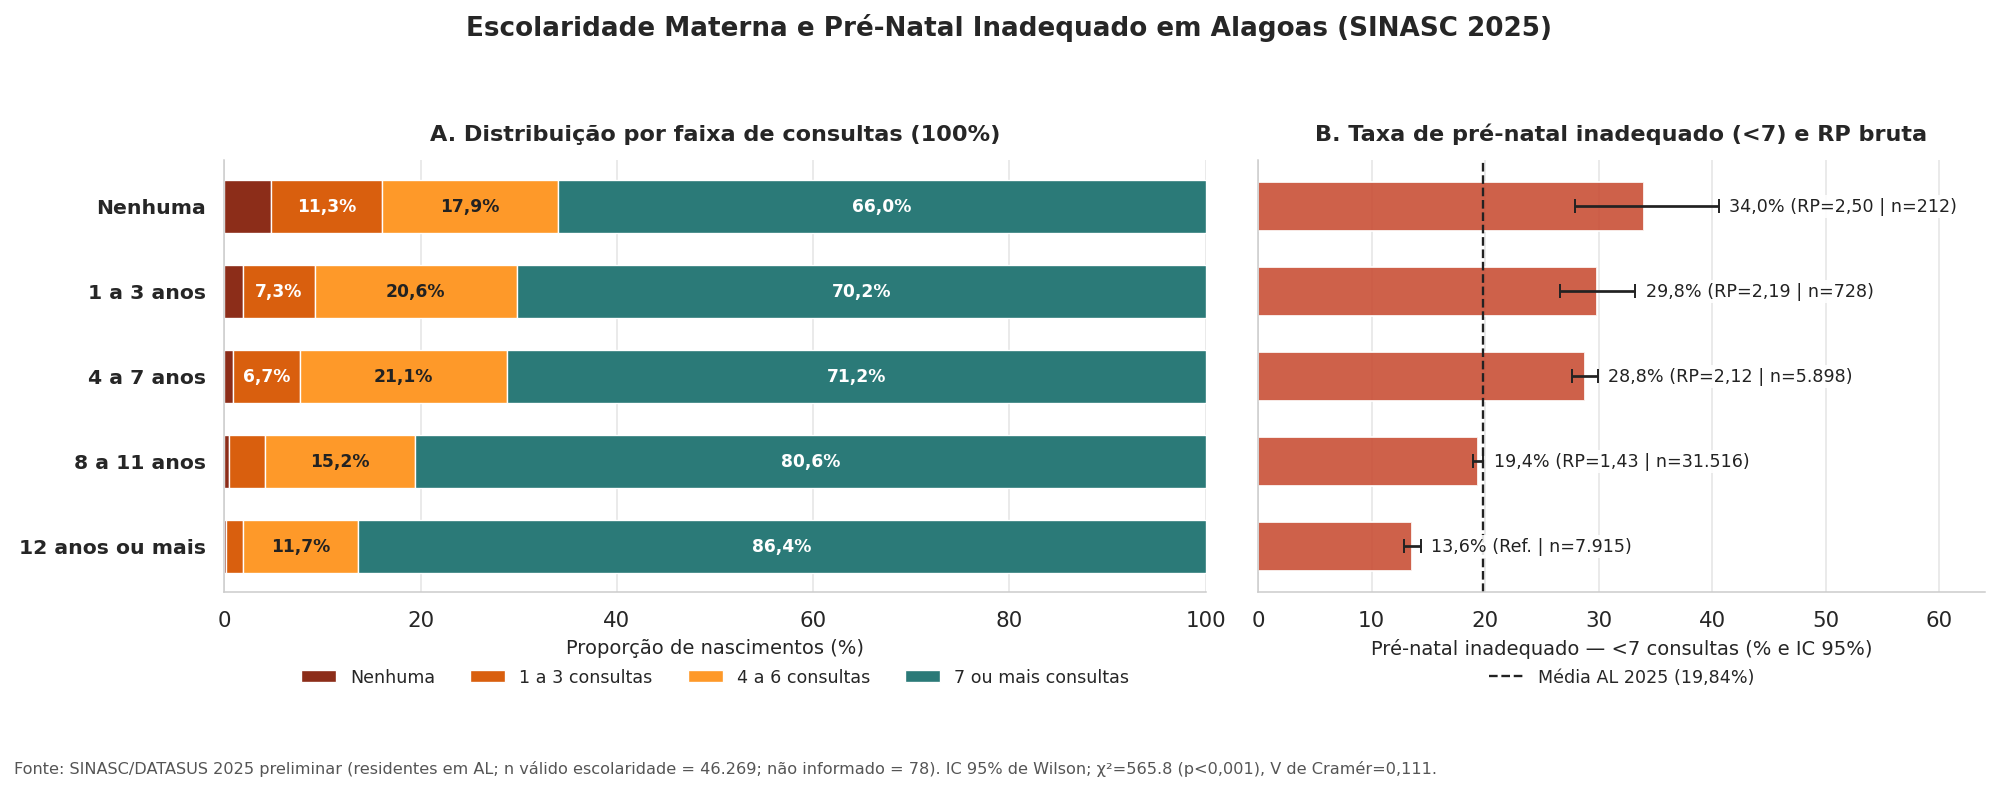

In [15]:
tab_esc = summarize_by_group(df, "ESCOLARIDADE_DESC", ORDEM_ESC, ref_group="12 anos ou mais")
tab_esc.to_csv(TREATED_DIR / "consultas_por_escolaridade_2025.csv", sep=";", index=False, encoding="utf-8-sig")

stats_esc = cramers_v_and_chi2(df, "ESCOLARIDADE_DESC")
print(
    f"Qui-quadrado 2025 (Escolaridade x Pré-natal inadequado): "
    f"chi2 = {stats_esc['chi2']:.2f} (gl={stats_esc['dof']}), "
    f"p = {stats_esc['p_valor']:.2e}, V de Cramér = {stats_esc['cramers_v']:.4f} (n={stats_esc['n']:,})"
)

stats_esc2010 = cramers_v_and_chi2(df, "ESCOLARIDADE_2010_DESC")
print(
    f"Checagem complementar 2025 (ESCMAE2010): chi2 = {stats_esc2010['chi2']:.2f}, "
    f"p = {stats_esc2010['p_valor']:.2e}, V de Cramér = {stats_esc2010['cramers_v']:.4f}"
)
display(tab_esc)

plot_esc = tab_esc[tab_esc["categoria"] != "Não informado"].copy().reset_index(drop=True)
y_pos = np.arange(len(plot_esc))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.35, 1.0]})

cores_emp = ["#8C2D19", "#D95F0E", "#FE9929", "#2B7A78"]
cols_n = ["n_nenhuma", "n_1_a_3", "n_4_a_6", "n_7_ou_mais"]
left = np.zeros(len(plot_esc))

for col_n, label, cor in zip(cols_n, ORDEM_CONSULTAS, cores_emp):
    pcts = plot_esc[col_n] / plot_esc["n_total"] * 100.0
    ax1.barh(y_pos, pcts, left=left, color=cor, height=0.62, edgecolor="white", linewidth=0.7, label=label)
    for i, (p, l) in enumerate(zip(pcts, left)):
        if p >= 5.5:
            txt_color = "white" if cor in ("#8C2D19", "#D95F0E", "#2B7A78") else "#222222"
            ax1.text(l + p / 2, i, f"{fmt_pt(p, 1)}%", va="center", ha="center", fontsize=8.8, fontweight="bold", color=txt_color)
    left += pcts

ax1.set_yticks(y_pos)
ax1.set_yticklabels(plot_esc["categoria"], fontsize=10.5, fontweight="bold")
ax1.invert_yaxis()
ax1.set_xlim(0, 100)
ax1.set_xlabel("Proporção de nascimentos (%)", fontsize=10)
ax1.set_title("A. Distribuição por faixa de consultas (100%)", fontsize=11.5, pad=10)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=9)
ax1.grid(axis="y", visible=False)
sns.despine(ax=ax1, top=True, right=True)

x_vals = plot_esc["taxa_inadequado_pct"].values
xerr = np.vstack([
    x_vals - plot_esc["ic95_inf_pct"].values,
    plot_esc["ic95_sup_pct"].values - x_vals,
])
ax2.barh(y_pos, x_vals, color=COR_ALERTA, alpha=0.88, height=0.58)
ax2.errorbar(x_vals, y_pos, xerr=xerr, fmt="none", ecolor="#222222", elinewidth=1.4, capsize=3.5)
ax2.axvline(TAXA_GERAL, color="#222222", linestyle="--", linewidth=1.2, label=f"Média AL 2025 ({fmt_pt(TAXA_GERAL, 2)}%)")

for i, row in plot_esc.iterrows():
    rp_txt = "Ref." if row["categoria"] == "12 anos ou mais" else f"RP={fmt_pt(row['rp_bruta'], 2)}"
    label_txt = f"{fmt_pt(row['taxa_inadequado_pct'], 1)}% ({rp_txt} | n={fmt_int_pt(row['n_total'])})"
    ax2.text(
        row["ic95_sup_pct"] + 0.9, i, label_txt, va="center", ha="left", fontsize=9, color="#222222",
        bbox=dict(boxstyle="square,pad=0.15", facecolor="white", edgecolor="none", alpha=0.88),
        zorder=5,
    )

ax2.set_xlim(0, 64)
ax2.set_xlabel("Pré-natal inadequado — <7 consultas (% e IC 95%)", fontsize=10)
ax2.set_title("B. Taxa de pré-natal inadequado (<7) e RP bruta", fontsize=11.5, pad=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, fontsize=9)
ax2.grid(axis="y", visible=False)
sns.despine(ax=ax2, top=True, right=True)

n_esc_na = int(tab_esc.loc[tab_esc["categoria"] == "Não informado", "n_total"].sum())
fig.suptitle("Escolaridade Materna e Pré-Natal Inadequado em Alagoas (SINASC 2025)", fontsize=13.5, fontweight="bold", y=0.98)
fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar (residentes em AL; n válido escolaridade = {fmt_int_pt(stats_esc['n'])}; "
    f"não informado = {n_esc_na}). IC 95% de Wilson; χ²={stats_esc['chi2']:.1f} (p<0,001), V de Cramér={fmt_pt(stats_esc['cramers_v'], 3)}.",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.savefig(FIG_DIR / "01_escolaridade_consultas.png", bbox_inches="tight")
plt.show()

### 2.2 Raça/Cor Materna e Pré-Natal Inadequado (2025)

Mantemos todos os grupos separados com `n` explícito e IC 95% de Wilson, adotando **Branca** como categoria de referência para o cálculo da Razão de Prevalência bruta (padrão adotado em estudos epidemiológicos de desigualdade racial em saúde no Brasil).

Qui-quadrado 2025 (Raça/Cor x Pré-natal inadequado): chi2 = 51.86 (gl=4), p = 1.47e-10, V de Cramér = 0.0335 (n=46,250)


,categoria,n_total,pct_amostra,n_nenhuma,n_1_a_3,n_4_a_6,n_7_ou_mais,n_inadequado,taxa_inadequado_pct,ic95_inf_pct,ic95_sup_pct,categoria_referencia,rp_bruta,rp_ic95_inf,rp_ic95_sup
0,Branca,4623,9.97,25,125,622,3851,772,16.70,15.65,17.80,Branca,1.000,1.000,1.000
1,Parda,39678,85.61,216,1574,6237,31651,8027,20.23,19.84,20.63,Branca,1.211,1.133,1.296
2,Preta,1324,2.86,13,57,212,1042,282,21.30,19.18,23.59,Branca,1.275,1.129,1.441
3,Amarela,336,0.72,4,10,50,272,64,19.05,15.21,23.59,Branca,1.141,0.907,1.435
4,Indígena,289,0.62,1,3,25,260,29,10.03,7.08,14.04,Branca,0.601,0.423,0.854
5,Não informado,97,0.21,0,1,18,78,19,19.59,12.91,28.58,Branca,NaN,NaN,NaN


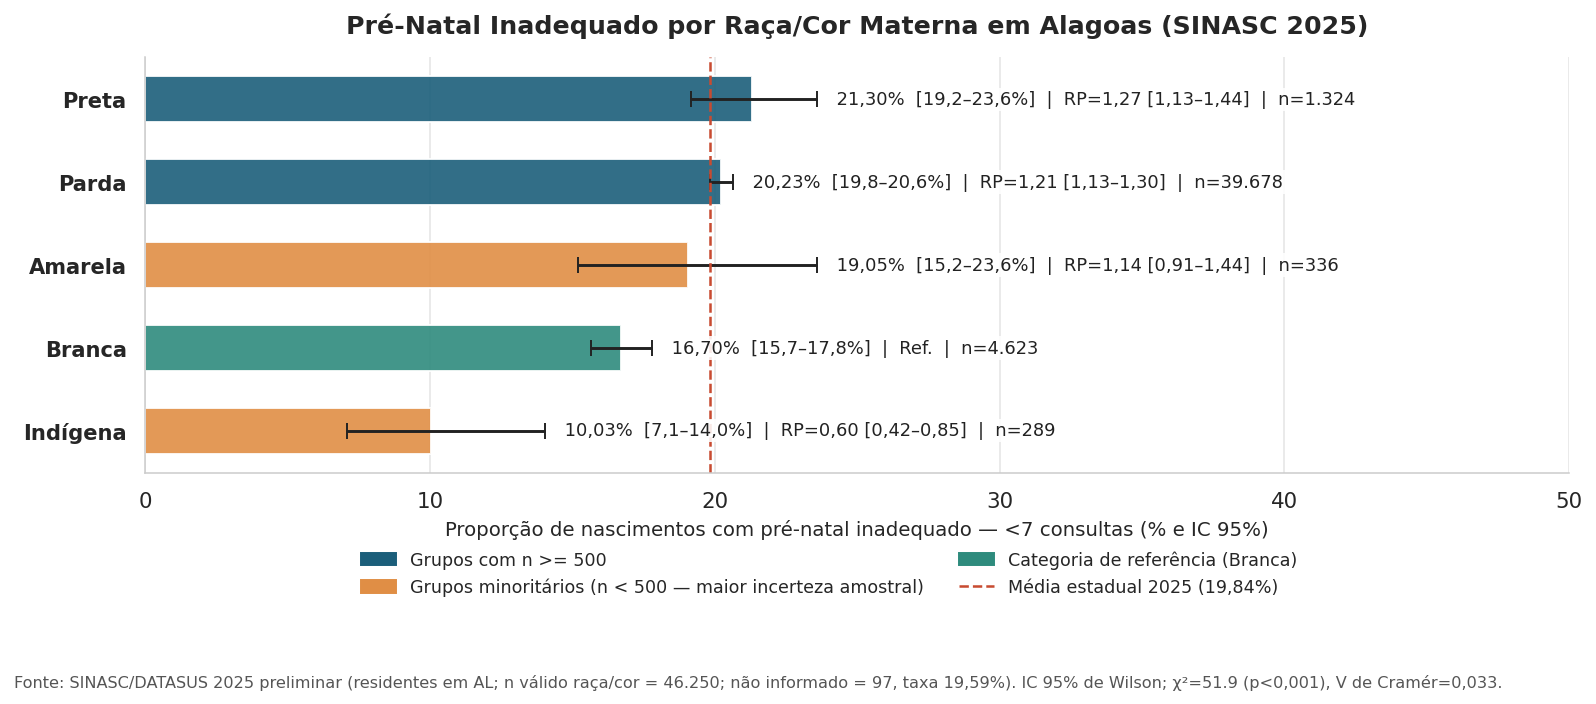

In [16]:
tab_raca = summarize_by_group(df, "RACACOR_DESC", ORDEM_RACA, ref_group="Branca")
tab_raca.to_csv(TREATED_DIR / "consultas_por_racacor_2025.csv", sep=";", index=False, encoding="utf-8-sig")

stats_raca = cramers_v_and_chi2(df, "RACACOR_DESC")
print(
    f"Qui-quadrado 2025 (Raça/Cor x Pré-natal inadequado): "
    f"chi2 = {stats_raca['chi2']:.2f} (gl={stats_raca['dof']}), "
    f"p = {stats_raca['p_valor']:.2e}, V de Cramér = {stats_raca['cramers_v']:.4f} (n={stats_raca['n']:,})"
)
display(tab_raca)

plot_raca = tab_raca[tab_raca["categoria"] != "Não informado"].sort_values("taxa_inadequado_pct", ascending=False).reset_index(drop=True)
y_pos = np.arange(len(plot_raca))

fig, ax = plt.subplots(figsize=(11.5, 5.2))
colors_raca = [COR_SECUNDARIA if c == "Branca" else (COR_DESTAQUE if n < 500 else COR_PRIMARIA) for c, n in zip(plot_raca["categoria"], plot_raca["n_total"])]

x_vals = plot_raca["taxa_inadequado_pct"].values
xerr = np.vstack([
    x_vals - plot_raca["ic95_inf_pct"].values,
    plot_raca["ic95_sup_pct"].values - x_vals,
])

ax.barh(y_pos, x_vals, color=colors_raca, height=0.56, alpha=0.9)
ax.errorbar(x_vals, y_pos, xerr=xerr, fmt="none", ecolor="#222222", elinewidth=1.5, capsize=4)
ax.axvline(TAXA_GERAL, color=COR_ALERTA, linestyle="--", linewidth=1.3, label=f"Média estadual 2025 ({fmt_pt(TAXA_GERAL, 2)}%)")

for i, row in plot_raca.iterrows():
    rp_txt = "Ref." if row["categoria"] == "Branca" else f"RP={fmt_pt(row['rp_bruta'], 2)} [{fmt_pt(row['rp_ic95_inf'], 2)}–{fmt_pt(row['rp_ic95_sup'], 2)}]"
    txt = f" {fmt_pt(row['taxa_inadequado_pct'], 2)}%  [{fmt_pt(row['ic95_inf_pct'], 1)}–{fmt_pt(row['ic95_sup_pct'], 1)}%]  |  {rp_txt}  |  n={fmt_int_pt(row['n_total'])}"
    ax.text(
        row["ic95_sup_pct"] + 0.5, i, txt, va="center", ha="left", fontsize=9.2, color="#222222",
        bbox=dict(boxstyle="square,pad=0.15", facecolor="white", edgecolor="none", alpha=0.88),
        zorder=5,
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_raca["categoria"], fontsize=10.8, fontweight="bold")
ax.invert_yaxis()
ax.set_xlim(0, 50)
ax.set_xlabel("Proporção de nascimentos com pré-natal inadequado — <7 consultas (% e IC 95%)", fontsize=10.2)
ax.set_title("Pré-Natal Inadequado por Raça/Cor Materna em Alagoas (SINASC 2025)", fontsize=13, pad=12)

legend_handles = [
    mpatches.Patch(color=COR_PRIMARIA, label="Grupos com n >= 500"),
    mpatches.Patch(color=COR_DESTAQUE, label="Grupos minoritários (n < 500 — maior incerteza amostral)"),
    mpatches.Patch(color=COR_SECUNDARIA, label="Categoria de referência (Branca)"),
    plt.Line2D([0], [0], color=COR_ALERTA, linestyle="--", linewidth=1.3, label=f"Média estadual 2025 ({fmt_pt(TAXA_GERAL, 2)}%)"),
]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.48, -0.15), ncol=2, frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, top=True, right=True)

raca_na_row = tab_raca[tab_raca["categoria"] == "Não informado"].iloc[0]
fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar (residentes em AL; n válido raça/cor = {fmt_int_pt(stats_raca['n'])}; "
    f"não informado = {fmt_int_pt(raca_na_row['n_total'])}, taxa {fmt_pt(raca_na_row['taxa_inadequado_pct'], 2)}%). "
    f"IC 95% de Wilson; χ²={stats_raca['chi2']:.1f} (p<0,001), V de Cramér={fmt_pt(stats_raca['cramers_v'], 3)}.",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.06, 1, 0.97])
plt.savefig(FIG_DIR / "02_racacor_inadequado.png", bbox_inches="tight")
plt.show()

### 2.3 Faixa Etária Materna e Pré-Natal Inadequado (2025)

Analisamos a idade da mãe (`IDADEMAE`, 11 a 57 anos, 0 ausentes) nas 6 faixas detalhadas (e exportamos também as 4 faixas de risco obstétrico em `consultas_por_faixa_etaria_2025.csv`).

Qui-quadrado 2025 (6 faixas): chi2 = 390.80 (gl=5), p = 2.84e-82, V de Cramér = 0.0918
Qui-quadrado 2025 (4 faixas): chi2 = 180.50 (gl=3), p = 6.86e-39, V de Cramér = 0.0624


,recorte,categoria,n_total,pct_amostra,n_nenhuma,n_1_a_3,n_4_a_6,n_7_ou_mais,n_inadequado,taxa_inadequado_pct,ic95_inf_pct,ic95_sup_pct,categoria_referencia,rp_bruta,rp_ic95_inf,rp_ic95_sup
0,6_faixas,Menor de 15 anos,346,0.75,2,22,72,250,96,27.75,23.29,32.69,30 a 34 anos,1.779,1.490,2.124
1,6_faixas,15 a 19 anos,6741,14.54,43,369,1281,5048,1693,25.11,24.09,26.16,30 a 34 anos,1.610,1.510,1.717
2,6_faixas,20 a 24 anos,12006,25.90,86,611,2104,9205,2801,23.33,22.58,24.09,30 a 34 anos,1.496,1.410,1.587
3,6_faixas,25 a 29 anos,12394,26.74,53,388,1783,10170,2224,17.94,17.28,18.63,30 a 34 anos,1.151,1.081,1.224
4,6_faixas,30 a 34 anos,8502,18.34,38,218,1070,7176,1326,15.60,14.84,16.38,30 a 34 anos,1.000,1.000,1.000
5,6_faixas,35 anos ou mais,6358,13.72,37,162,854,5305,1053,16.56,15.67,17.50,30 a 34 anos,1.062,0.986,1.144


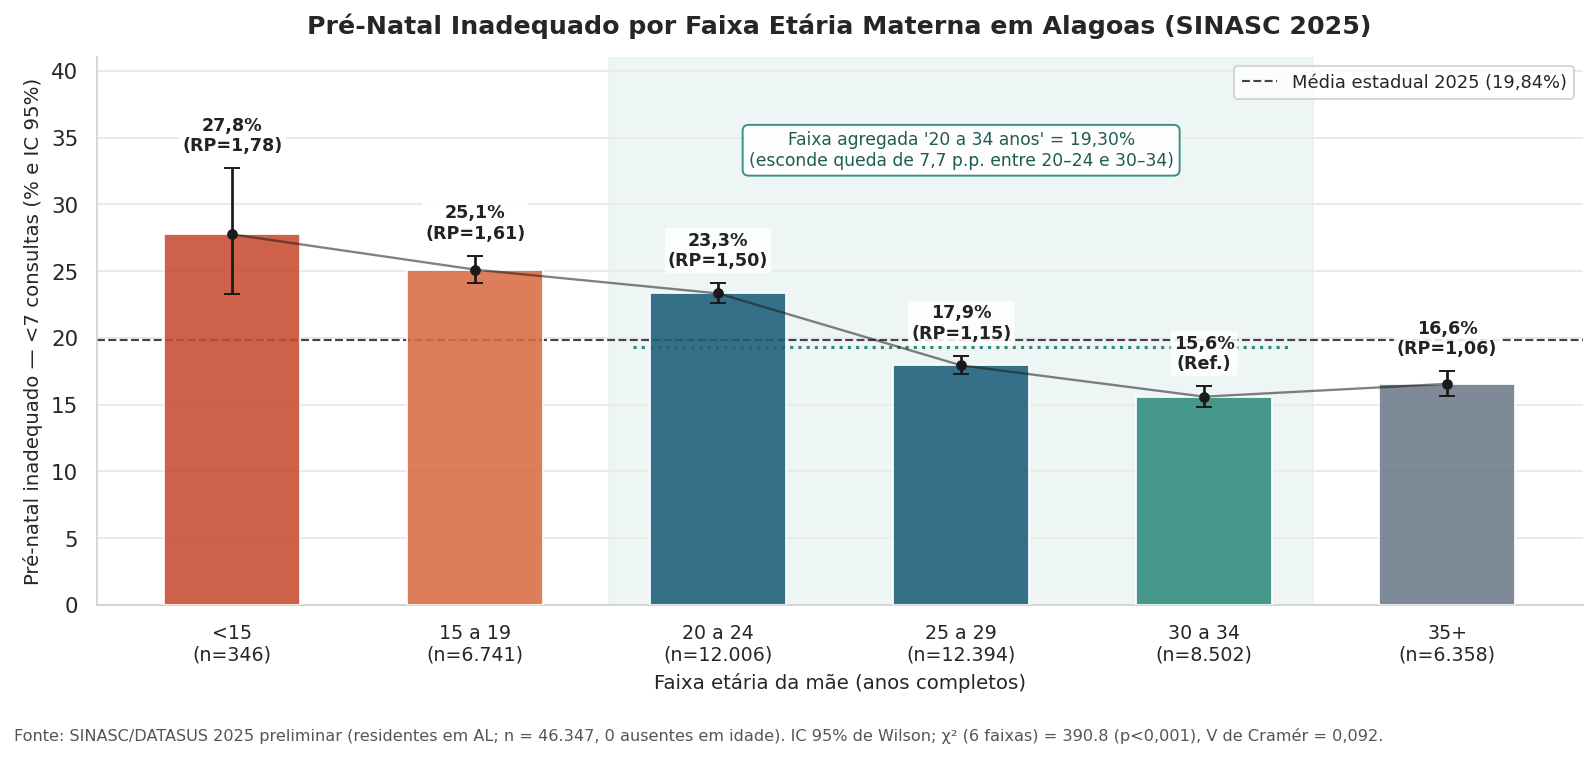

In [17]:
tab_idade6 = summarize_by_group(df, "FAIXA_ETARIA_DETALHADA", ORDEM_IDADE_6, ref_group="30 a 34 anos", include_missing=False)
tab_idade6.insert(0, "recorte", "6_faixas")

tab_idade4 = summarize_by_group(df, "FAIXA_ETARIA_MAE", ORDEM_IDADE_4, ref_group="35 anos ou mais", include_missing=False)
tab_idade4.insert(0, "recorte", "4_faixas")

tab_idade_all = pd.concat([tab_idade6, tab_idade4], ignore_index=True)
tab_idade_all.to_csv(TREATED_DIR / "consultas_por_faixa_etaria_2025.csv", sep=";", index=False, encoding="utf-8-sig")

stats_idade6 = cramers_v_and_chi2(df, "FAIXA_ETARIA_DETALHADA")
stats_idade4 = cramers_v_and_chi2(df, "FAIXA_ETARIA_MAE")
print(
    f"Qui-quadrado 2025 (6 faixas): chi2 = {stats_idade6['chi2']:.2f} (gl={stats_idade6['dof']}), "
    f"p = {stats_idade6['p_valor']:.2e}, V de Cramér = {stats_idade6['cramers_v']:.4f}"
)
print(
    f"Qui-quadrado 2025 (4 faixas): chi2 = {stats_idade4['chi2']:.2f} (gl={stats_idade4['dof']}), "
    f"p = {stats_idade4['p_valor']:.2e}, V de Cramér = {stats_idade4['cramers_v']:.4f}"
)
display(tab_idade6)

taxa_20_34 = float(tab_idade4.loc[tab_idade4["categoria"] == "20 a 34 anos", "taxa_inadequado_pct"].iloc[0])
queda_20_34 = float(
    tab_idade6.loc[tab_idade6["categoria"] == "20 a 24 anos", "taxa_inadequado_pct"].iloc[0]
    - tab_idade6.loc[tab_idade6["categoria"] == "30 a 34 anos", "taxa_inadequado_pct"].iloc[0]
)

fig, ax = plt.subplots(figsize=(11.5, 5.6))
x_pos = np.arange(len(tab_idade6))
y_vals = tab_idade6["taxa_inadequado_pct"].values
yerr = np.vstack([
    y_vals - tab_idade6["ic95_inf_pct"].values,
    tab_idade6["ic95_sup_pct"].values - y_vals,
])

ax.axvspan(1.55, 4.45, color="#E8F3F1", alpha=0.75, zorder=0)
ax.hlines(taxa_20_34, 1.65, 4.35, colors=COR_SECUNDARIA, linestyles=":", linewidth=1.6, zorder=2)
ax.text(
    3.0, 35.5,
    f"Faixa agregada '20 a 34 anos' = {fmt_pt(taxa_20_34, 2)}%\n(esconde queda de {fmt_pt(queda_20_34, 1)} p.p. entre 20–24 e 30–34)",
    ha="center", va="top", fontsize=8.8, color="#1D5C53",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor=COR_SECUNDARIA, alpha=0.95),
)

bar_colors = [COR_ALERTA, "#D96B43", COR_PRIMARIA, COR_PRIMARIA, COR_SECUNDARIA, COR_NEUTRA]
ax.bar(x_pos, y_vals, width=0.56, color=bar_colors, alpha=0.88, zorder=3)
ax.errorbar(x_pos, y_vals, yerr=yerr, fmt="o", color="#1A1A1A", ecolor="#1A1A1A", elinewidth=1.4, capsize=4, markersize=4.5, zorder=4)
ax.plot(x_pos, y_vals, color="#1A1A1A", linewidth=1.2, alpha=0.55, zorder=3)
ax.axhline(TAXA_GERAL, color="#444444", linestyle="--", linewidth=1.1, label=f"Média estadual 2025 ({fmt_pt(TAXA_GERAL, 2)}%)")

for i, row in tab_idade6.iterrows():
    rp_txt = "Ref." if row["categoria"] == "30 a 34 anos" else f"RP={fmt_pt(row['rp_bruta'], 2)}"
    ax.text(
        i, row["ic95_sup_pct"] + 1.0,
        f"{fmt_pt(row['taxa_inadequado_pct'], 1)}%\n({rp_txt})",
        ha="center", va="bottom", fontsize=9, fontweight="bold", color="#222222",
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="none", alpha=0.88),
        zorder=6,
    )

xtick_labels = [
    f"{cat.replace(' anos', '').replace('Menor de 15', '<15').replace('35 ou mais', '35+')}\n(n={fmt_int_pt(n)})"
    for cat, n in zip(tab_idade6["categoria"], tab_idade6["n_total"])
]
ax.set_xticks(x_pos)
ax.set_xticklabels(xtick_labels, fontsize=9.8)
ax.set_ylim(0, 41.0)
ax.set_ylabel("Pré-natal inadequado — <7 consultas (% e IC 95%)", fontsize=10.2)
ax.set_xlabel("Faixa etária da mãe (anos completos)", fontsize=10.2)
ax.set_title("Pré-Natal Inadequado por Faixa Etária Materna em Alagoas (SINASC 2025)", fontsize=13, pad=12)
ax.legend(loc="upper right", frameon=True, facecolor="white", fontsize=9.2)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax, top=True, right=True)

fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar (residentes em AL; n = {fmt_int_pt(N_TOTAL)}, 0 ausentes em idade). "
    f"IC 95% de Wilson; χ² (6 faixas) = {stats_idade6['chi2']:.1f} (p<0,001), V de Cramér = {fmt_pt(stats_idade6['cramers_v'], 3)}.",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig(FIG_DIR / "03_faixa_etaria_inadequado.png", bbox_inches="tight")
plt.show()

### 2.4 Análise Estratificada: Raça/Cor × Escolaridade Materna (2025)

Avaliamos a interação entre raça/cor e escolaridade com máscara visual para `n < 30` no heatmap (100% dos valores salvos em `cruzamento_raca_escolaridade_2025.csv`) e destaque para a faixa **`8 a 11 anos`**.

Raça/Cor 2025 DENTRO de '8 a 11 anos' (n=31,450): chi2 = 18.12 (gl=4), p = 1.1705e-03, V de Cramér = 0.0240


,categoria,n_total,taxa_inadequado_pct,ic95_inf_pct,ic95_sup_pct,rp_bruta,rp_ic95_inf,rp_ic95_sup
0,Branca,2321,19.73,18.16,21.40,1.000,1.000,1.000
1,Parda,27804,19.37,18.91,19.84,0.982,0.901,1.069
2,Preta,864,21.99,19.36,24.87,1.114,0.959,1.295
3,Amarela,238,19.75,15.19,25.27,1.001,0.765,1.310
4,Indígena,223,9.42,6.24,13.97,0.477,0.315,0.723


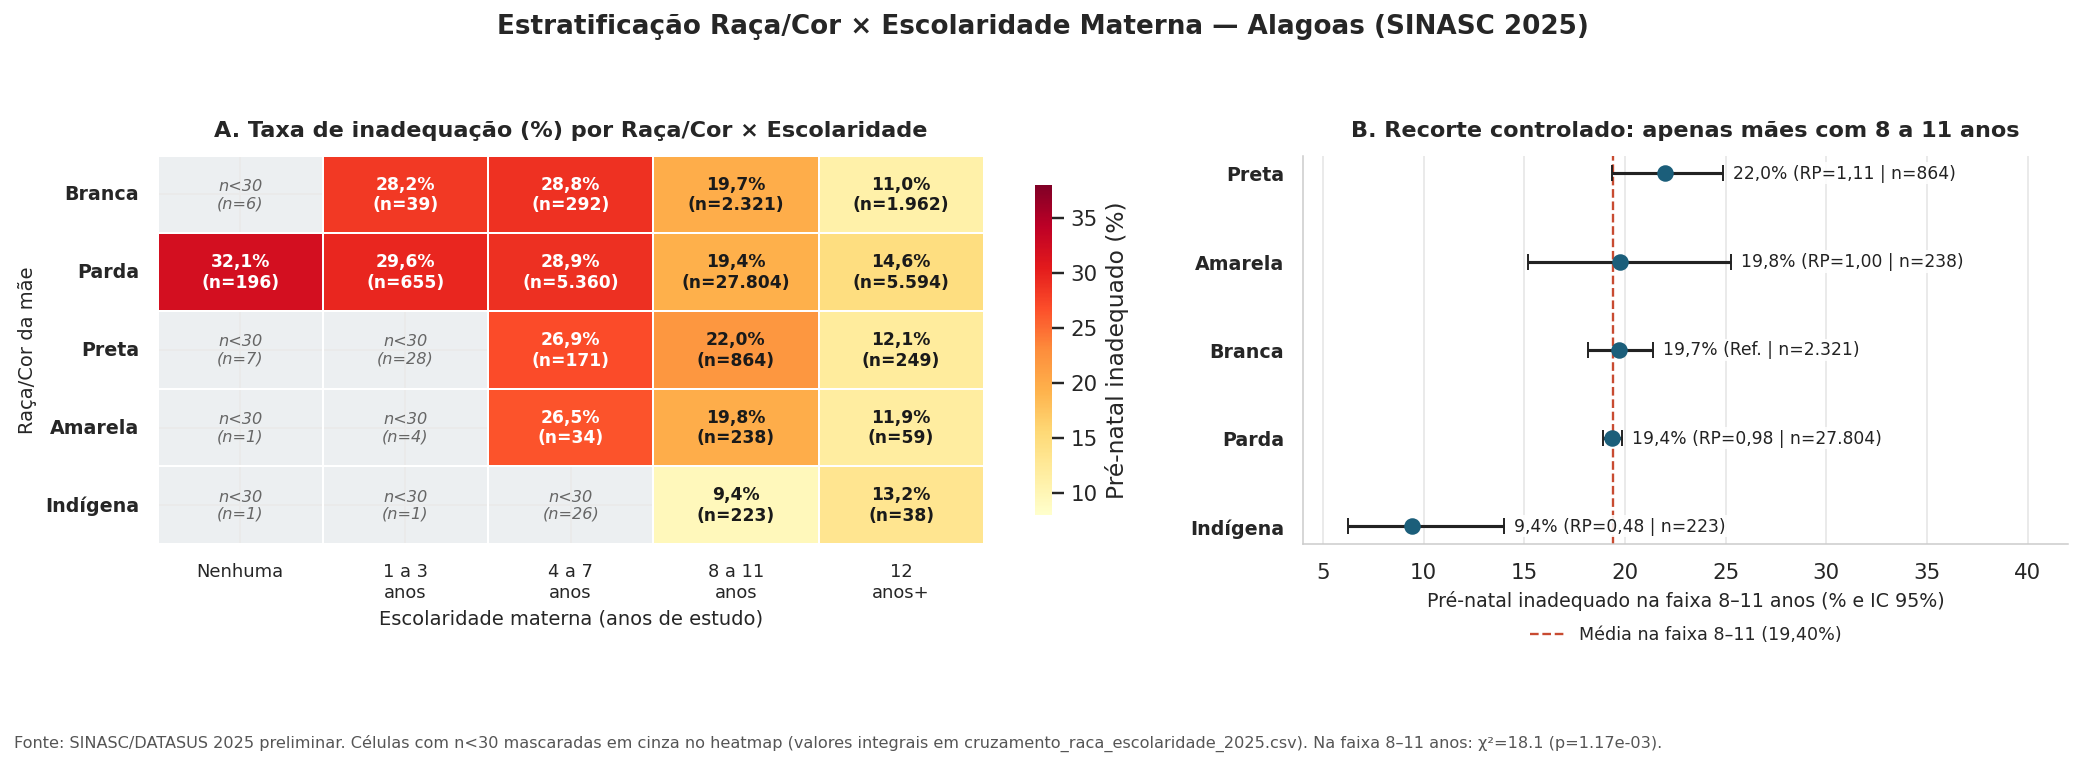

In [18]:
def build_crosstab_table(data: pd.DataFrame, row_col: str, col_col: str, row_order: list[str], col_order: list[str]) -> pd.DataFrame:
    sub = data[[row_col, col_col, "PRENATAL_INADEQUADO"]].dropna()
    rows = []
    for r in row_order:
        for c in col_order:
            cell = sub[(sub[row_col] == r) & (sub[col_col] == c)]
            n = int(len(cell))
            k = int(cell["PRENATAL_INADEQUADO"].sum())
            taxa = (k / n * 100.0) if n > 0 else np.nan
            ic_inf, ic_sup = wilson_ci(k, n) if n > 0 else (np.nan, np.nan)
            rows.append({
                row_col: r,
                col_col: c,
                "n_total": n,
                "n_inadequado": k,
                "taxa_inadequado_pct": round(taxa, 2) if pd.notna(taxa) else np.nan,
                "ic95_inf_pct": round(ic_inf, 2) if pd.notna(ic_inf) else np.nan,
                "ic95_sup_pct": round(ic_sup, 2) if pd.notna(ic_sup) else np.nan,
                "mascarado_heatmap_n_lt_30": bool(n < 30),
            })
    return pd.DataFrame(rows)


tab_re = build_crosstab_table(df, "RACACOR_DESC", "ESCOLARIDADE_DESC", ORDEM_RACA, ORDEM_ESC)
tab_re.to_csv(TREATED_DIR / "cruzamento_raca_escolaridade_2025.csv", sep=";", index=False, encoding="utf-8-sig")

df_8_11 = df[df["ESCOLARIDADE_DESC"] == "8 a 11 anos"].copy()
stats_raca_8_11 = cramers_v_and_chi2(df_8_11, "RACACOR_DESC")
tab_raca_8_11 = summarize_by_group(df_8_11, "RACACOR_DESC", ORDEM_RACA, ref_group="Branca", include_missing=False)
print(
    f"Raça/Cor 2025 DENTRO de '8 a 11 anos' (n={stats_raca_8_11['n']:,}): "
    f"chi2 = {stats_raca_8_11['chi2']:.2f} (gl={stats_raca_8_11['dof']}), "
    f"p = {stats_raca_8_11['p_valor']:.4e}, V de Cramér = {stats_raca_8_11['cramers_v']:.4f}"
)
display(tab_raca_8_11[["categoria", "n_total", "taxa_inadequado_pct", "ic95_inf_pct", "ic95_sup_pct", "rp_bruta", "rp_ic95_inf", "rp_ic95_sup"]])

piv_rate = tab_re.pivot(index="RACACOR_DESC", columns="ESCOLARIDADE_DESC", values="taxa_inadequado_pct").loc[ORDEM_RACA, ORDEM_ESC]
piv_n = tab_re.pivot(index="RACACOR_DESC", columns="ESCOLARIDADE_DESC", values="n_total").loc[ORDEM_RACA, ORDEM_ESC]
mask_small = piv_n < 30

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 5.4), gridspec_kw={"width_ratios": [1.35, 1.0]})

ax1.set_facecolor("#ECEFF1")
sns.heatmap(
    piv_rate,
    mask=mask_small,
    annot=False,
    cmap="YlOrRd",
    vmin=8,
    vmax=38,
    linewidths=1.0,
    linecolor="white",
    cbar_kws={"label": "Pré-natal inadequado (%)", "shrink": 0.85},
    ax=ax1,
)
for i, r in enumerate(ORDEM_RACA):
    for j, c in enumerate(ORDEM_ESC):
        n_val = int(piv_n.loc[r, c])
        rate_val = piv_rate.loc[r, c]
        if n_val < 30:
            ax1.text(j + 0.5, i + 0.5, f"n<30\n(n={n_val})", ha="center", va="center", fontsize=8.3, color="#666666", style="italic")
        else:
            txt_col = "white" if rate_val >= 26 else "#1A1A1A"
            ax1.text(j + 0.5, i + 0.5, f"{fmt_pt(rate_val, 1)}%\n(n={fmt_int_pt(n_val)})", ha="center", va="center", fontsize=8.8, fontweight="bold", color=txt_col)

ax1.set_title("A. Taxa de inadequação (%) por Raça/Cor × Escolaridade", fontsize=11.5, pad=10)
ax1.set_xlabel("Escolaridade materna (anos de estudo)", fontsize=10)
ax1.set_ylabel("Raça/Cor da mãe", fontsize=10)
ax1.set_xticklabels([c.replace(" anos", "\nanos").replace(" ou mais", "+") for c in ORDEM_ESC], rotation=0, fontsize=9.2)
ax1.set_yticklabels(ORDEM_RACA, rotation=0, fontsize=9.8, fontweight="bold")

plot_8_11 = tab_raca_8_11.sort_values("taxa_inadequado_pct", ascending=False).reset_index(drop=True)
y2 = np.arange(len(plot_8_11))
x2 = plot_8_11["taxa_inadequado_pct"].values
xerr2 = np.vstack([x2 - plot_8_11["ic95_inf_pct"].values, plot_8_11["ic95_sup_pct"].values - x2])

media_8_11 = df_8_11["PRENATAL_INADEQUADO"].mean() * 100
ax2.axvline(media_8_11, color=COR_ALERTA, linestyle="--", linewidth=1.2, label=f"Média na faixa 8–11 ({fmt_pt(media_8_11, 2)}%)")
ax2.errorbar(x2, y2, xerr=xerr2, fmt="o", color=COR_PRIMARIA, ecolor="#222222", elinewidth=1.6, capsize=4, markersize=7.5)

for i, row in plot_8_11.iterrows():
    rp_s = "Ref." if row["categoria"] == "Branca" else f"RP={fmt_pt(row['rp_bruta'], 2)}"
    ax2.text(
        row["ic95_sup_pct"] + 0.5, i,
        f"{fmt_pt(row['taxa_inadequado_pct'], 1)}% ({rp_s} | n={fmt_int_pt(row['n_total'])})",
        va="center", ha="left", fontsize=8.8, color="#222222",
        bbox=dict(boxstyle="square,pad=0.12", facecolor="white", edgecolor="none", alpha=0.88),
        zorder=5,
    )

ax2.set_yticks(y2)
ax2.set_yticklabels(plot_8_11["categoria"], fontsize=9.8, fontweight="bold")
ax2.invert_yaxis()
ax2.set_xlim(4, 42)
ax2.set_xlabel("Pré-natal inadequado na faixa 8–11 anos (% e IC 95%)", fontsize=9.8)
ax2.set_title("B. Recorte controlado: apenas mães com 8 a 11 anos", fontsize=11.5, pad=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, fontsize=9.0)
ax2.grid(axis="y", visible=False)
sns.despine(ax=ax2, top=True, right=True)

fig.suptitle("Estratificação Raça/Cor × Escolaridade Materna — Alagoas (SINASC 2025)", fontsize=13.5, fontweight="bold", y=0.98)
fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar. Células com n<30 mascaradas em cinza no heatmap (valores integrais em cruzamento_raca_escolaridade_2025.csv). "
    f"Na faixa 8–11 anos: χ²={stats_raca_8_11['chi2']:.1f} (p={stats_raca_8_11['p_valor']:.2e}).",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.savefig(FIG_DIR / "04_estratificacao_raca_escolaridade.png", bbox_inches="tight")
plt.show()

### 2.5 Análise Estratificada: Faixa Etária × Escolaridade Materna (2025)

Heatmap 6 × 5 com máscara visual para células `n < 30` ou estruturalmente nulas (`n = 0`), preservando 100% das combinações em `cruzamento_idade_escolaridade_2025.csv`.

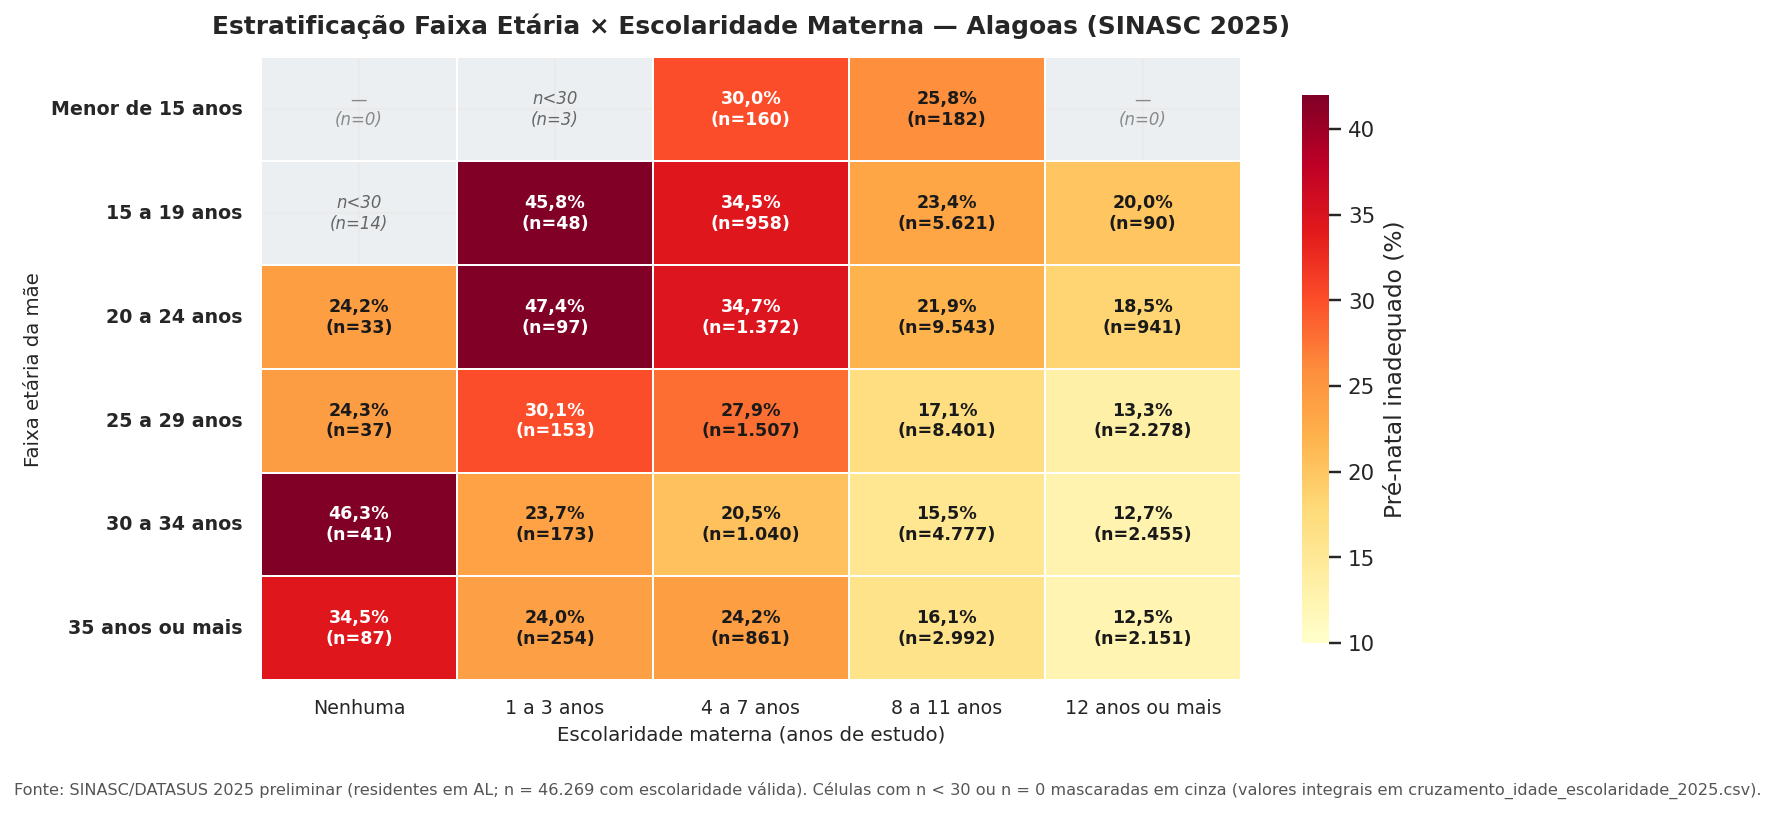

In [19]:
tab_ie = build_crosstab_table(df, "FAIXA_ETARIA_DETALHADA", "ESCOLARIDADE_DESC", ORDEM_IDADE_6, ORDEM_ESC)
tab_ie.to_csv(TREATED_DIR / "cruzamento_idade_escolaridade_2025.csv", sep=";", index=False, encoding="utf-8-sig")

piv_ie_rate = tab_ie.pivot(index="FAIXA_ETARIA_DETALHADA", columns="ESCOLARIDADE_DESC", values="taxa_inadequado_pct").loc[ORDEM_IDADE_6, ORDEM_ESC]
piv_ie_n = tab_ie.pivot(index="FAIXA_ETARIA_DETALHADA", columns="ESCOLARIDADE_DESC", values="n_total").loc[ORDEM_IDADE_6, ORDEM_ESC]
mask_ie = piv_ie_n < 30

fig, ax = plt.subplots(figsize=(10.8, 6.0))
ax.set_facecolor("#ECEFF1")
sns.heatmap(
    piv_ie_rate,
    mask=mask_ie,
    annot=False,
    cmap="YlOrRd",
    vmin=10,
    vmax=42,
    linewidths=1.0,
    linecolor="white",
    cbar_kws={"label": "Pré-natal inadequado (%)", "shrink": 0.88},
    ax=ax,
)

for i, r in enumerate(ORDEM_IDADE_6):
    for j, c in enumerate(ORDEM_ESC):
        n_val = int(piv_ie_n.loc[r, c])
        rate_val = piv_ie_rate.loc[r, c]
        if n_val == 0:
            ax.text(j + 0.5, i + 0.5, "—\n(n=0)", ha="center", va="center", fontsize=8.5, color="#888888", style="italic")
        elif n_val < 30:
            ax.text(j + 0.5, i + 0.5, f"n<30\n(n={n_val})", ha="center", va="center", fontsize=8.5, color="#666666", style="italic")
        else:
            txt_col = "white" if rate_val >= 28 else "#1A1A1A"
            ax.text(j + 0.5, i + 0.5, f"{fmt_pt(rate_val, 1)}%\n(n={fmt_int_pt(n_val)})", ha="center", va="center", fontsize=9.0, fontweight="bold", color=txt_col)

ax.set_title("Estratificação Faixa Etária × Escolaridade Materna — Alagoas (SINASC 2025)", fontsize=12.8, pad=12)
ax.set_xlabel("Escolaridade materna (anos de estudo)", fontsize=10.2)
ax.set_ylabel("Faixa etária da mãe", fontsize=10.2)
ax.set_xticklabels(ORDEM_ESC, rotation=0, fontsize=9.8)
ax.set_yticklabels(ORDEM_IDADE_6, rotation=0, fontsize=9.8, fontweight="bold")

fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar (residentes em AL; n = {fmt_int_pt(stats_esc['n'])} com escolaridade válida). "
    "Células com n < 30 ou n = 0 mascaradas em cinza (valores integrais em cruzamento_idade_escolaridade_2025.csv).",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig(FIG_DIR / "05_estratificacao_idade_escolaridade.png", bbox_inches="tight")
plt.show()

### 2.6 Análise de Sensibilidade: Controle do Confundidor Prematuridade (`>= 37 semanas`, 2025)

Comparamos todos os nascimentos válidos de 2025 frente ao recorte restrito a nascimentos **a termo (`PREMATURO == 0`, `>= 37 semanas`)** nas três dimensões principais.

Todos os nascimentos válidos 2025 : n = 46,347 | Inadequado = 19.84%
Apenas a termo (>= 37 semanas)    : n = 40,894 | Inadequado = 17.50%
Prematuros (< 37 semanas)         : n = 5,421 | Inadequado = 37.30%
Idade gestacional ausente (NaN)   : n = 32


,dimensao,categoria,n_total_todos,taxa_inadequado_pct_todos,rp_bruta_todos,n_total_a_termo,taxa_inadequado_pct_a_termo,rp_bruta_a_termo,diferenca_pp
0,Escolaridade,Nenhuma,212,33.96,2.501,163,29.45,2.476,4.51
1,Escolaridade,1 a 3 anos,728,29.81,2.195,601,26.62,2.238,3.19
2,Escolaridade,4 a 7 anos,5898,28.76,2.117,5086,26.23,2.205,2.53
3,Escolaridade,8 a 11 anos,31516,19.40,1.429,27933,17.05,1.433,2.35
4,Escolaridade,12 anos ou mais,7915,13.58,1.000,7045,11.89,1.000,1.69
5,Raça/Cor,Branca,4623,16.70,1.000,4110,14.74,1.000,1.96
6,Raça/Cor,Parda,39678,20.23,1.211,34972,17.87,1.212,2.36
7,Raça/Cor,Preta,1324,21.30,1.275,1165,18.88,1.281,2.42
8,Raça/Cor,Amarela,336,19.05,1.141,295,14.58,0.989,4.47
9,Raça/Cor,Indígena,289,10.03,0.601,267,8.24,0.559,1.79


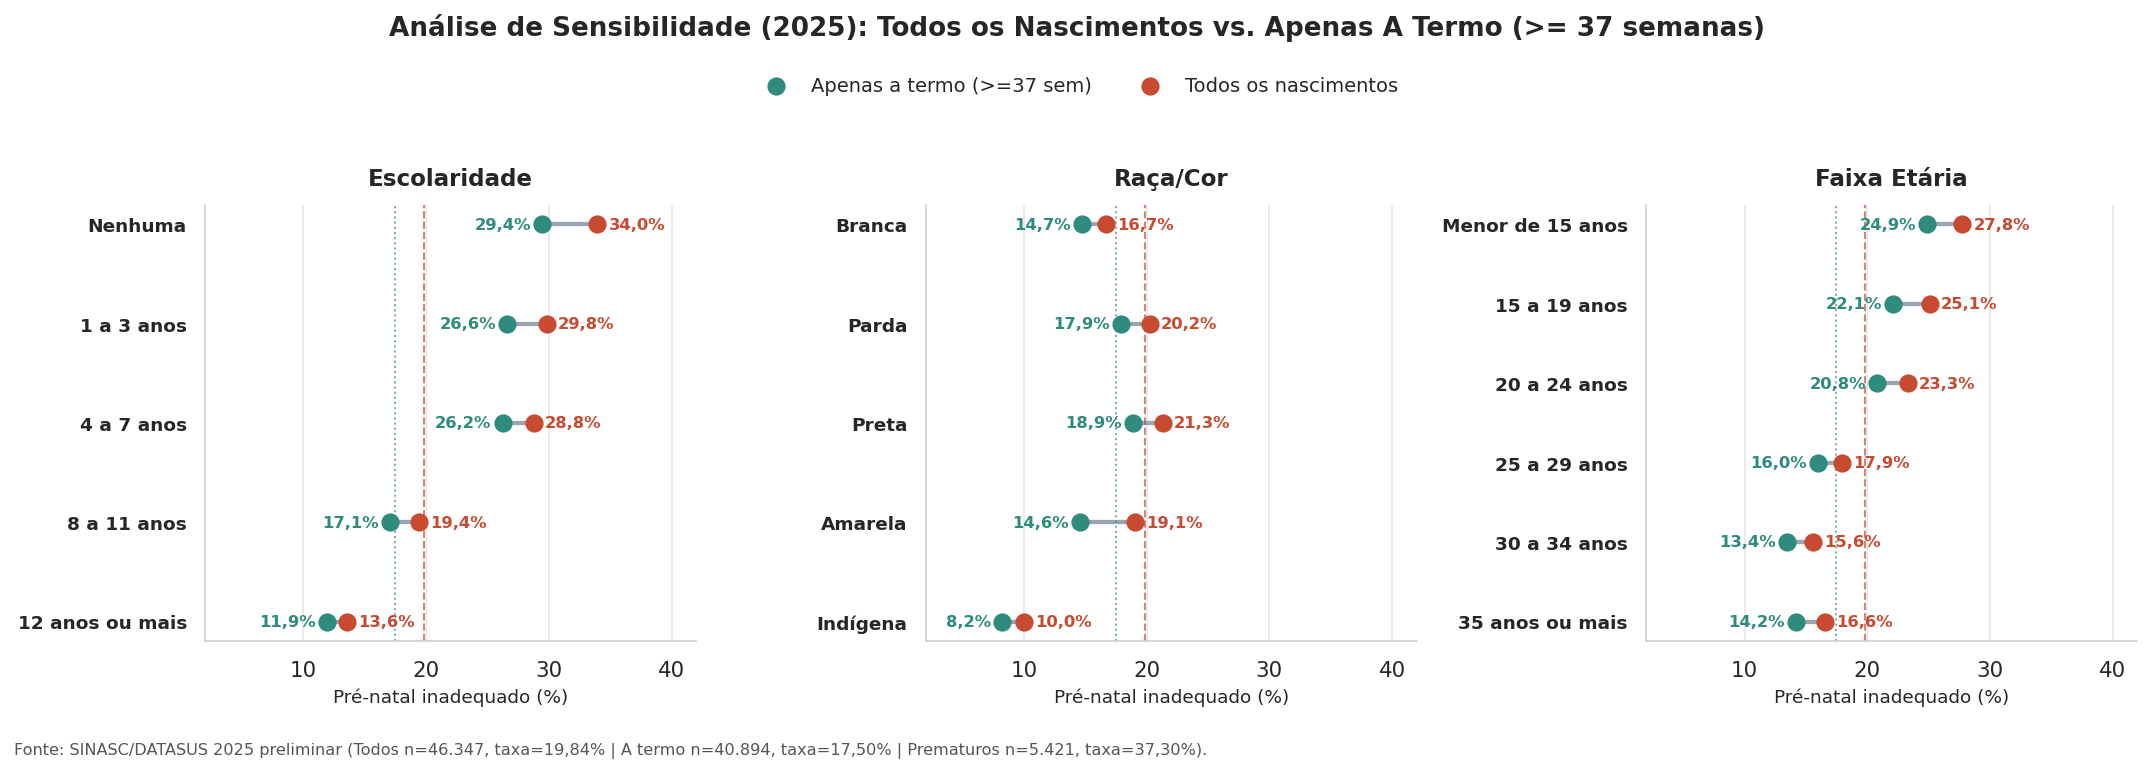

In [20]:
df_termo = df[df["PREMATURO"] == 0].copy()
df_prem = df[df["PREMATURO"] == 1].copy()

taxa_termo = df_termo["PRENATAL_INADEQUADO"].mean() * 100
taxa_prem = df_prem["PRENATAL_INADEQUADO"].mean() * 100
print(f"Todos os nascimentos válidos 2025 : n = {len(df):,} | Inadequado = {TAXA_GERAL:.2f}%")
print(f"Apenas a termo (>= 37 semanas)    : n = {len(df_termo):,} | Inadequado = {taxa_termo:.2f}%")
print(f"Prematuros (< 37 semanas)         : n = {len(df_prem):,} | Inadequado = {taxa_prem:.2f}%")
print(f"Idade gestacional ausente (NaN)   : n = {int(df['PREMATURO'].isna().sum()):,}")

sens_blocks = []
specs = [
    ("Escolaridade", "ESCOLARIDADE_DESC", ORDEM_ESC, "12 anos ou mais"),
    ("Raça/Cor", "RACACOR_DESC", ORDEM_RACA, "Branca"),
    ("Faixa Etária", "FAIXA_ETARIA_DETALHADA", ORDEM_IDADE_6, "30 a 34 anos"),
]

for dim_label, col, order, ref in specs:
    t_all = summarize_by_group(df, col, order, ref_group=ref, include_missing=False)
    t_term = summarize_by_group(df_termo, col, order, ref_group=ref, include_missing=False)
    merged = t_all[["categoria", "n_total", "taxa_inadequado_pct", "rp_bruta"]].merge(
        t_term[["categoria", "n_total", "taxa_inadequado_pct", "rp_bruta"]],
        on="categoria",
        suffixes=("_todos", "_a_termo"),
    )
    merged.insert(0, "dimensao", dim_label)
    merged["diferenca_pp"] = (merged["taxa_inadequado_pct_todos"] - merged["taxa_inadequado_pct_a_termo"]).round(2)
    sens_blocks.append(merged)

tab_sens = pd.concat(sens_blocks, ignore_index=True)
tab_sens.to_csv(TREATED_DIR / "sensibilidade_prematuridade_2025.csv", sep=";", index=False, encoding="utf-8-sig")
display(tab_sens)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4), sharex=True)

for ax, (dim_label, _, _, _) in zip(axes, specs):
    sub = tab_sens[tab_sens["dimensao"] == dim_label].reset_index(drop=True)
    y = np.arange(len(sub))

    for i, row in sub.iterrows():
        ax.plot(
            [row["taxa_inadequado_pct_a_termo"], row["taxa_inadequado_pct_todos"]],
            [i, i],
            color="#9AA5B1",
            linewidth=2.2,
            zorder=1,
        )
        ax.text(row["taxa_inadequado_pct_a_termo"] - 0.9, i, f"{fmt_pt(row['taxa_inadequado_pct_a_termo'], 1)}%", va="center", ha="right", fontsize=8.4, color=COR_SECUNDARIA, fontweight="bold")
        ax.text(row["taxa_inadequado_pct_todos"] + 0.9, i, f"{fmt_pt(row['taxa_inadequado_pct_todos'], 1)}%", va="center", ha="left", fontsize=8.4, color=COR_ALERTA, fontweight="bold")

    ax.scatter(sub["taxa_inadequado_pct_a_termo"], y, color=COR_SECUNDARIA, s=70, zorder=3, label="Apenas a termo (>=37 sem)")
    ax.scatter(sub["taxa_inadequado_pct_todos"], y, color=COR_ALERTA, s=70, zorder=3, label="Todos os nascimentos")
    ax.axvline(taxa_termo, color=COR_SECUNDARIA, linestyle=":", linewidth=1.0, alpha=0.7)
    ax.axvline(TAXA_GERAL, color=COR_ALERTA, linestyle="--", linewidth=1.0, alpha=0.7)

    ax.set_yticks(y)
    ax.set_yticklabels(sub["categoria"], fontsize=9.5, fontweight="bold")
    ax.invert_yaxis()
    ax.set_title(dim_label, fontsize=11.8, pad=10)
    ax.set_xlabel("Pré-natal inadequado (%)", fontsize=9.5)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, top=True, right=True)

axes[0].set_xlim(2, 42)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=False, fontsize=10)
fig.suptitle("Análise de Sensibilidade (2025): Todos os Nascimentos vs. Apenas A Termo (>= 37 semanas)", fontsize=13.5, fontweight="bold", y=0.99)
fig.text(
    0.01, 0.01,
    f"Fonte: SINASC/DATASUS 2025 preliminar (Todos n={fmt_int_pt(len(df))}, taxa={fmt_pt(TAXA_GERAL, 2)}% | "
    f"A termo n={fmt_int_pt(len(df_termo))}, taxa={fmt_pt(taxa_termo, 2)}% | Prematuros n={fmt_int_pt(len(df_prem))}, taxa={fmt_pt(taxa_prem, 2)}%).",
    fontsize=8.3, color="#555555",
)
plt.tight_layout(rect=[0, 0.04, 1, 0.89])
plt.savefig(FIG_DIR / "06_sensibilidade_prematuridade.png", bbox_inches="tight")
plt.show()

### 2.7 Auditoria de Dados Faltantes e Discussão: Quantidade vs. Qualidade (2025)

Avaliamos o perfil dos **51 registros** com `CONSULTAS == 9` (0,11%), os limites extremos de impacto na taxa estadual, o descompasso entre quantidade de consultas e início oportuno (Kotelchuck) e o ranking de força de associação (V de Cramér).

In [21]:
print("=== 1. AUDITORIA DOS 51 REGISTROS COM CONSULTAS == 9 (0,11% de AL 2025) ===")
print("Distribuição por Raça/Cor:")
print(df_ign["RACACOR_DESC"].fillna("Não informado").value_counts())
print("\nDistribuição por Escolaridade:")
print(df_ign["ESCOLARIDADE_DESC"].fillna("Não informado").value_counts())
print("\nDistribuição por Faixa Etária (6 faixas):")
print(df_ign["FAIXA_ETARIA_DETALHADA"].value_counts())

taxa_min_extremo = K_TOTAL / (N_TOTAL + len(df_ign)) * 100
taxa_max_extremo = (K_TOTAL + len(df_ign)) / (N_TOTAL + len(df_ign)) * 100
print(f"\nLimites extremos da taxa estadual 2025 se os 51 ignorados fossem 0% ou 100% inadequados: [{taxa_min_extremo:.2f}%, {taxa_max_extremo:.2f}%]")

print("\n=== 2. QUANTIDADE != QUALIDADE (MÊS DE INÍCIO E ÍNDICE DE KOTELCHUCK — 2025) ===")
df_7mais = df[df["CONSULTAS"] == 4].copy()
n_7mais = len(df_7mais)
tardio_7mais = int((df_7mais["MESPRENAT"] >= 4).sum())
kotel_inad_7mais = int((df_7mais["KOTELCHUCK"] == 2).sum())
print(f"Entre as {n_7mais:,} mães com 7 ou mais consultas:")
print(f"  - Iniciaram pré-natal após o 3º mês (MESPRENAT >= 4): {tardio_7mais:,} ({tardio_7mais/n_7mais*100:.2f}%)")
print(f"  - Classificadas como 'Inadequado' no Kotelchuck     : {kotel_inad_7mais:,} ({kotel_inad_7mais/n_7mais*100:.2f}%)")

print("\n=== 3. COMPARAÇÃO DA FORÇA DE ASSOCIAÇÃO (V DE CRAMÉR — 2025) ===")
resumo_forca = pd.DataFrame([
    {"Fator": "Escolaridade materna (5 faixas)", "n": stats_esc["n"], "chi2": round(stats_esc["chi2"], 2), "p_valor": stats_esc["p_valor"], "V_de_Cramer": round(stats_esc["cramers_v"], 4)},
    {"Fator": "Escolaridade 2010 (6 níveis)", "n": stats_esc2010["n"], "chi2": round(stats_esc2010["chi2"], 2), "p_valor": stats_esc2010["p_valor"], "V_de_Cramer": round(stats_esc2010["cramers_v"], 4)},
    {"Fator": "Faixa etária materna (6 faixas)", "n": stats_idade6["n"], "chi2": round(stats_idade6["chi2"], 2), "p_valor": stats_idade6["p_valor"], "V_de_Cramer": round(stats_idade6["cramers_v"], 4)},
    {"Fator": "Faixa etária materna (4 faixas)", "n": stats_idade4["n"], "chi2": round(stats_idade4["chi2"], 2), "p_valor": stats_idade4["p_valor"], "V_de_Cramer": round(stats_idade4["cramers_v"], 4)},
    {"Fator": "Raça/Cor materna (5 categorias)", "n": stats_raca["n"], "chi2": round(stats_raca["chi2"], 2), "p_valor": stats_raca["p_valor"], "V_de_Cramer": round(stats_raca["cramers_v"], 4)},
]).sort_values("V_de_Cramer", ascending=False)
display(resumo_forca)

=== 1. AUDITORIA DOS 51 REGISTROS COM CONSULTAS == 9 (0,11% de AL 2025) ===
Distribuição por Raça/Cor:
RACACOR_DESC
Parda            48
Preta             2
Não informado     1
Name: count, dtype: int64

Distribuição por Escolaridade:
ESCOLARIDADE_DESC
8 a 11 anos        33
4 a 7 anos         16
12 anos ou mais     1
Nenhuma             1
Name: count, dtype: int64

Distribuição por Faixa Etária (6 faixas):
FAIXA_ETARIA_DETALHADA
20 a 24 anos       18
25 a 29 anos       16
30 a 34 anos        9
15 a 19 anos        4
35 anos ou mais     4
Name: count, dtype: int64

Limites extremos da taxa estadual 2025 se os 51 ignorados fossem 0% ou 100% inadequados: [19.81%, 19.92%]

=== 2. QUANTIDADE != QUALIDADE (MÊS DE INÍCIO E ÍNDICE DE KOTELCHUCK — 2025) ===
Entre as 37,154 mães com 7 ou mais consultas:
  - Iniciaram pré-natal após o 3º mês (MESPRENAT >= 4): 2,380 (6.41%)
  - Classificadas como 'Inadequado' no Kotelchuck     : 2,380 (6.41%)

=== 3. COMPARAÇÃO DA FORÇA DE ASSOCIAÇÃO (V DE CRAMÉR — 

,Fator,n,chi2,p_valor,V_de_Cramer
1,Escolaridade 2010 (6 níveis),46269,686.68,3.718691e-146,0.1218
0,Escolaridade materna (5 faixas),46269,565.77,3.965204e-121,0.1106
2,Faixa etária materna (6 faixas),46347,390.80,2.844185e-82,0.0918
3,Faixa etária materna (4 faixas),46347,180.50,6.864865e-39,0.0624
4,Raça/Cor materna (5 categorias),46250,51.86,1.473690e-10,0.0335


### 2.8 Síntese dos Achados e Limitações

#### Resposta direta à pergunta de pesquisa (Alagoas, SINASC 2025)
Em Alagoas em 2025 (**n = 46.347** nascidos vivos de mães residentes com informação válida de consultas), **19,84% (9.193)** tiveram pré-natal inadequado (<7 consultas). Os três fatores analisados apresentam associação estatisticamente significativa ($p < 0{,}001$), com hierarquia bem definida de intensidade:

1. **Escolaridade materna (associação mais forte — V de Cramér = 0,111 em `ESCMAE` e 0,122 em `ESCMAE2010`):** exibe gradiente monotônico nítido, caindo de **33,96%** (*Nenhuma*, RP = 2,50 [IC 95%: 2,06–3,04]) até **13,58%** (*12 anos ou mais*, referência). A transição de `4 a 7 anos` (28,76%) para `8 a 11 anos` (19,40%) concentra uma redução de 9,36 pontos percentuais.
2. **Faixa etária materna (V de Cramér = 0,092 nas 6 faixas; 0,062 nas 4 faixas):** relação em formato de "L", com maiores proporções entre adolescentes `<15 anos` (**27,75%**, RP = 1,78 [1,49–2,12]) e `15–19 anos` (**25,11%**, RP = 1,61 [1,51–1,72]), caindo continuamente até o menor patamar em `30–34 anos` (**15,60%**) e mantendo-se próxima ao mínimo em `35+ anos` (**16,56%**). Quebrar a faixa agregada `20–34` (19,30%) revela um gradiente interno de **7,73 p.p.** entre `20–24` (**23,33%**) e `30–34` (**15,60%**).
3. **Raça/cor materna (V de Cramér = 0,034):** associação cerca de três vezes mais fraca que escolaridade e idade. Na análise bruta, mães **Pretas** (**21,30%**, RP = 1,28 [1,13–1,44]) e **Pardas** (**20,23%**, RP = 1,21 [1,13–1,30]) ficam acima de **Brancas** (**16,70%**), enquanto mães **Indígenas** apresentam **10,03%** (n=289, IC 95%: 7,1–14,0%; RP = 0,60 [0,42–0,85]) e **Amarelas** ficam em **19,05%** (n=336, sem diferença significativa frente a Brancas). Na estratificação controlada para `8 a 11 anos` de estudo (n=31.450; 68% da base), **Brancas (19,73%) e Pardas (19,37%, RP = 0,98) praticamente empatam**, enquanto o teste global ($\chi^2 = 18{,}12, p = 0{,}001$, V = 0,024) é puxado pela baixa taxa registrada em **Indígenas (9,42%)** e pela taxa mais alta em **Pretas (21,99%)**. Já na faixa de `12 anos ou mais`, **Pardas (14,6%)** permanecem acima de **Brancas (11,0%)**.
4. **Efeito combinado (Idade × Escolaridade):** mães jovens com baixa escolaridade chegam a **45,8%–47,4%** de inadequação (`15–19` e `20–24` com `1 a 3 anos`), quase quatro vezes a taxa de mães com `30+ anos` e `12+ anos` de estudo (**12,5%–12,7%**).
5. **Robustez frente à prematuridade:** partos prematuros (`< 37 semanas`, n=5.421) registram **37,30%** de pré-natal inadequado vs. **17,50%** nos nascimentos a termo (`>= 37 semanas`, n=40.894). Ao excluir os prematuros, todos os gradientes e razões de prevalência por escolaridade, faixa etária e raça/cor permanecem preservados.

#### Limitações metodológicas e éticas
- **Associação não implica causalidade:** trata-se de estudo observacional transversal sobre registros administrativos.
- **Ausência de renda direta:** o SINASC não registra renda familiar; escolaridade e raça/cor atuam como marcadores socioeconômicos estruturais, mas não esgotam as condições materiais de acesso.
- **Caráter preliminar dos dados de 2025:** os registros do SINASC 2025 estão sujeitos a revisão e retroalimentação tardia no DATASUS, o que exige cautela adicional especialmente na leitura de grupos menores (como Indígenas, n=289, e Amarelas, n=336).
- **Quantidade não mede toda a qualidade:** entre as **37.154** mães com 7 ou mais consultas, **2.380 (6,41%)** iniciaram o pré-natal após o 3º mês (`MESPRENAT >= 4`) e são classificadas como **Inadequado** pelo Índice de Kotelchuck — além de o SINASC não informar exames, vacinação ou qualidade clínica do atendimento.
- **Dados ignorados e amostras pequenas:** os 51 casos com `CONSULTAS == 9` (0,11%) restringem a incerteza extrema da taxa estadual ao intervalo **[19,81%, 19,92%]**. Nos cruzamentos duplos, células com `n < 30` foram mascaradas nos heatmaps (mantidas integralmente nos CSVs) para evitar interpretações instáveis.

## 3. Pergunta 2 · Contraste territorial e registros ignorados

Comparamos a proporção de nascidos vivos com menos de sete consultas nos 102 municípios em 2025 e verificamos como o ranking muda com números absolutos. A auditoria consulta a base original para estudar os registros com consultas ignoradas.

In [22]:
import os
import json
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Configuracao visual padrao
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def fmt_br(val, casas=2):
    return f'{val:.{casas}f}'.replace('.', ',')

def fmt_int(val):
    return f'{int(val):,}'.replace(',', '.')

arq_tratada = TRATADOS_AB2 / "base_tratada_SINASC_AL_2025.csv"
arq_original = entrada_2025
arq_ibge = entrada_ibge

In [23]:
# Tabela oficial IBGE dos 102 municipios de Alagoas (reserva caso o JSON nao seja enviado)
IBGE_FALLBACK = [[270010, "Água Branca", "Serrana do Sertão Alagoano", "Sertão Alagoano"], [270020, "Anadia", "São Miguel dos Campos", "Leste Alagoano"], [270030, "Arapiraca", "Arapiraca", "Agreste Alagoano"], [270040, "Atalaia", "Mata Alagoana", "Leste Alagoano"], [270050, "Barra de Santo Antônio", "Maceió", "Leste Alagoano"], [270060, "Barra de São Miguel", "Maceió", "Leste Alagoano"], [270070, "Batalha", "Batalha", "Sertão Alagoano"], [270080, "Belém", "Palmeira dos Índios", "Agreste Alagoano"], [270090, "Belo Monte", "Batalha", "Sertão Alagoano"], [270100, "Boca da Mata", "São Miguel dos Campos", "Leste Alagoano"], [270110, "Branquinha", "Mata Alagoana", "Leste Alagoano"], [270120, "Cacimbinhas", "Palmeira dos Índios", "Agreste Alagoano"], [270130, "Cajueiro", "Mata Alagoana", "Leste Alagoano"], [270135, "Campestre", "Mata Alagoana", "Leste Alagoano"], [270140, "Campo Alegre", "São Miguel dos Campos", "Leste Alagoano"], [270150, "Campo Grande", "Arapiraca", "Agreste Alagoano"], [270160, "Canapi", "Serrana do Sertão Alagoano", "Sertão Alagoano"], [270170, "Capela", "Mata Alagoana", "Leste Alagoano"], [270180, "Carneiros", "Santana do Ipanema", "Sertão Alagoano"], [270190, "Chã Preta", "Serrana dos Quilombos", "Leste Alagoano"], [270200, "Coité do Nóia", "Arapiraca", "Agreste Alagoano"], [270210, "Colônia Leopoldina", "Mata Alagoana", "Leste Alagoano"], [270220, "Coqueiro Seco", "Maceió", "Leste Alagoano"], [270230, "Coruripe", "São Miguel dos Campos", "Leste Alagoano"], [270235, "Craíbas", "Arapiraca", "Agreste Alagoano"], [270240, "Delmiro Gouveia", "Alagoana do Sertão do São Francisco", "Sertão Alagoano"], [270250, "Dois Riachos", "Santana do Ipanema", "Sertão Alagoano"], [270255, "Estrela de Alagoas", "Palmeira dos Índios", "Agreste Alagoano"], [270260, "Feira Grande", "Arapiraca", "Agreste Alagoano"], [270270, "Feliz Deserto", "Penedo", "Leste Alagoano"], [270280, "Flexeiras", "Mata Alagoana", "Leste Alagoano"], [270290, "Girau do Ponciano", "Arapiraca", "Agreste Alagoano"], [270300, "Ibateguara", "Serrana dos Quilombos", "Leste Alagoano"], [270310, "Igaci", "Palmeira dos Índios", "Agreste Alagoano"], [270320, "Igreja Nova", "Penedo", "Leste Alagoano"], [270330, "Inhapi", "Serrana do Sertão Alagoano", "Sertão Alagoano"], [270340, "Jacaré dos Homens", "Batalha", "Sertão Alagoano"], [270350, "Jacuípe", "Mata Alagoana", "Leste Alagoano"], [270360, "Japaratinga", "Litoral Norte Alagoano", "Leste Alagoano"], [270370, "Jaramataia", "Batalha", "Sertão Alagoano"], [270375, "Jequiá da Praia", "São Miguel dos Campos", "Leste Alagoano"], [270380, "Joaquim Gomes", "Mata Alagoana", "Leste Alagoano"], [270390, "Jundiá", "Mata Alagoana", "Leste Alagoano"], [270400, "Junqueiro", "São Miguel dos Campos", "Leste Alagoano"], [270410, "Lagoa da Canoa", "Arapiraca", "Agreste Alagoano"], [270420, "Limoeiro de Anadia", "Arapiraca", "Agreste Alagoano"], [270430, "Maceió", "Maceió", "Leste Alagoano"], [270440, "Major Isidoro", "Batalha", "Sertão Alagoano"], [270450, "Maragogi", "Litoral Norte Alagoano", "Leste Alagoano"], [270460, "Maravilha", "Santana do Ipanema", "Sertão Alagoano"], [270470, "Marechal Deodoro", "Maceió", "Leste Alagoano"], [270480, "Maribondo", "Palmeira dos Índios", "Agreste Alagoano"], [270490, "Mar Vermelho", "Palmeira dos Índios", "Agreste Alagoano"], [270500, "Mata Grande", "Serrana do Sertão Alagoano", "Sertão Alagoano"], [270510, "Matriz de Camaragibe", "Mata Alagoana", "Leste Alagoano"], [270520, "Messias", "Mata Alagoana", "Leste Alagoano"], [270530, "Minador do Negrão", "Palmeira dos Índios", "Agreste Alagoano"], [270540, "Monteirópolis", "Batalha", "Sertão Alagoano"], [270550, "Murici", "Mata Alagoana", "Leste Alagoano"], [270560, "Novo Lino", "Mata Alagoana", "Leste Alagoano"], [270570, "Olho d'Água das Flores", "Batalha", "Sertão Alagoano"], [270580, "Olho d'Água do Casado", "Alagoana do Sertão do São Francisco", "Sertão Alagoano"], [270590, "Olho d'Água Grande", "Traipu", "Agreste Alagoano"], [270600, "Olivença", "Batalha", "Sertão Alagoano"], [270610, "Ouro Branco", "Santana do Ipanema", "Sertão Alagoano"], [270620, "Palestina", "Santana do Ipanema", "Sertão Alagoano"], [270630, "Palmeira dos Índios", "Palmeira dos Índios", "Agreste Alagoano"], [270640, "Pão de Açúcar", "Santana do Ipanema", "Sertão Alagoano"], [270642, "Pariconha", "Serrana do Sertão Alagoano", "Sertão Alagoano"], [270644, "Paripueira", "Maceió", "Leste Alagoano"], [270650, "Passo de Camaragibe", "Litoral Norte Alagoano", "Leste Alagoano"], [270660, "Paulo Jacinto", "Palmeira dos Índios", "Agreste Alagoano"], [270670, "Penedo", "Penedo", "Leste Alagoano"], [270680, "Piaçabuçu", "Penedo", "Leste Alagoano"], [270690, "Pilar", "Maceió", "Leste Alagoano"], [270700, "Pindoba", "Serrana dos Quilombos", "Leste Alagoano"], [270710, "Piranhas", "Alagoana do Sertão do São Francisco", "Sertão Alagoano"], [270720, "Poço das Trincheiras", "Santana do Ipanema", "Sertão Alagoano"], [270730, "Porto Calvo", "Mata Alagoana", "Leste Alagoano"], [270740, "Porto de Pedras", "Litoral Norte Alagoano", "Leste Alagoano"], [270750, "Porto Real do Colégio", "Penedo", "Leste Alagoano"], [270760, "Quebrangulo", "Palmeira dos Índios", "Agreste Alagoano"], [270770, "Rio Largo", "Maceió", "Leste Alagoano"], [270780, "Roteiro", "São Miguel dos Campos", "Leste Alagoano"], [270790, "Santa Luzia do Norte", "Maceió", "Leste Alagoano"], [270800, "Santana do Ipanema", "Santana do Ipanema", "Sertão Alagoano"], [270810, "Santana do Mundaú", "Serrana dos Quilombos", "Leste Alagoano"], [270820, "São Brás", "Traipu", "Agreste Alagoano"], [270830, "São José da Laje", "Serrana dos Quilombos", "Leste Alagoano"], [270840, "São José da Tapera", "Santana do Ipanema", "Sertão Alagoano"], [270850, "São Luís do Quitunde", "Mata Alagoana", "Leste Alagoano"], [270860, "São Miguel dos Campos", "São Miguel dos Campos", "Leste Alagoano"], [270870, "São Miguel dos Milagres", "Litoral Norte Alagoano", "Leste Alagoano"], [270880, "São Sebastião", "Arapiraca", "Agreste Alagoano"], [270890, "Satuba", "Maceió", "Leste Alagoano"], [270895, "Senador Rui Palmeira", "Santana do Ipanema", "Sertão Alagoano"], [270900, "Tanque d'Arca", "Palmeira dos Índios", "Agreste Alagoano"], [270910, "Taquarana", "Arapiraca", "Agreste Alagoano"], [270915, "Teotônio Vilela", "São Miguel dos Campos", "Leste Alagoano"], [270920, "Traipu", "Traipu", "Agreste Alagoano"], [270930, "União dos Palmares", "Serrana dos Quilombos", "Leste Alagoano"], [270940, "Viçosa", "Serrana dos Quilombos", "Leste Alagoano"]]

if arq_ibge and os.path.exists(arq_ibge):
    with open(arq_ibge, 'r', encoding='utf-8') as f:
        ibge_json = json.load(f)
    df_ibge = pd.DataFrame([
        {
            'CODMUNRES': int(str(item['id'])[:6]),
            'MUNICIPIO': item['nome'],
            'MICRORREGIAO': item['microrregiao']['nome'],
            'MESORREGIAO': item['microrregiao']['mesorregiao']['nome']
        }
        for item in ibge_json
    ])
    origem_ibge = arq_ibge
else:
    df_ibge = pd.DataFrame(IBGE_FALLBACK, columns=['CODMUNRES', 'MUNICIPIO', 'MICRORREGIAO', 'MESORREGIAO'])
    origem_ibge = 'tabela oficial IBGE embutida no notebook'

# Carregar base original (quando disponivel) para auditoria de ignorados
df_raw = None
if arq_original and os.path.exists(arq_original):
    df_raw = pd.read_csv(arq_original, sep=';', low_memory=False)
    df_raw = df_raw.merge(df_ibge, on='CODMUNRES', how='left')

# Carregar base tratada (ou derivar em memoria se apenas a original foi enviada)
if arq_tratada and os.path.exists(arq_tratada):
    df = pd.read_csv(arq_tratada, sep=';')
    origem_base = arq_tratada
elif df_raw is not None:
    df = df_raw[df_raw['CODMUNRES'].astype(str).str.startswith('27') & df_raw['CONSULTAS'].isin([1, 2, 3, 4])].copy()
    df['PRENATAL_INADEQUADO'] = (df['CONSULTAS'] < 4).astype(int)
    origem_base = f'{arq_original} (filtrada em memoria)'
else:
    raise FileNotFoundError('Nenhum arquivo CSV encontrado. Envie base_tratada_SINASC_AL_2025.csv ou SINASC_AL_2025_residencia.csv.')

if 'MUNICIPIO' not in df.columns:
    df = df.merge(df_ibge, on='CODMUNRES', how='left')

print(f'Dados prontos ({origem_base}): {fmt_int(len(df))} registros validos.')
print(f'Nomenclatura territorial ({origem_ibge}): {df["MUNICIPIO"].nunique()} municipios | Sem correspondencia: {df["MUNICIPIO"].isna().sum()}')

Dados prontos (Saídas do notebook\dados_tratados\base_tratada_SINASC_AL_2025.csv): 46.347 registros validos.
Nomenclatura territorial (Dados\Brutos\IBGE_municipios_Alagoas.json): 102 municipios | Sem correspondencia: 0


### 3.1 Distribuição Estadual das Consultas, Estatística Descritiva e Contraste Regional

Esta seção reproduz todas as tabelas descritivas do relatório e dos cartões de KPI do painel HTML:
- Distribuição estadual das 4 faixas de `CONSULTAS` (mais os 51 ignorados na base original).
- Estatística descritiva completa dos 102 municípios (taxa %, volume de nascimentos e casos absolutos inadequados).
- Peso demográfico de Maceió, razão de escala entre o maior e o menor município (`369,4x`), composição de atendimento nos municípios extremos (`<= 3` consultas), resumo por mesorregião e microrregião, Top 10 melhores coberturas e lista de municípios de pequeno porte (`< 100` nascimentos).

In [24]:
# 1.1 Distribuicao estadual das faixas de consultas (base original vs. base tratada)
mapa_cons = {1: 'Nenhuma consulta', 2: '1 a 3 consultas', 3: '4 a 6 consultas', 4: '7 ou mais consultas', 9: 'Ignorado (excluido na limpeza)'}
mapa_class = {1: 'Inadequado (< 7)', 2: 'Inadequado (< 7)', 3: 'Inadequado (< 7)', 4: 'Adequado (>= 7)', 9: 'Removido do calculo'}

n_trat = len(df)
n_orig = len(df_raw) if df_raw is not None else n_trat
rows_faixas = []
for cod in [1, 2, 3, 4, 9]:
    if cod == 9:
        qtd = int((df_raw['CONSULTAS'] == 9).sum()) if df_raw is not None else 0
        pct_t = 'N/A'
    else:
        qtd = int((df['CONSULTAS'] == cod).sum())
        pct_t = f'{fmt_br(qtd / n_trat * 100)}%'
    pct_o = f'{fmt_br(qtd / n_orig * 100)}%' if df_raw is not None else 'N/A'
    rows_faixas.append({
        'Codigo': cod, 'Faixa_Consultas': mapa_cons[cod], 'Classificacao': mapa_class[cod],
        'Registros': qtd, '%_Base_Original': pct_o, '%_Base_Tratada': pct_t
    })
df_faixas_est = pd.DataFrame(rows_faixas)
print('=== 1.1 DISTRIBUICAO ESTADUAL DAS FAIXAS DE CONSULTAS ===')
print(df_faixas_est.to_string(index=False))

# 1.2 Agregacao municipal e rankings
mun = df.groupby(['CODMUNRES', 'MUNICIPIO', 'MESORREGIAO', 'MICRORREGIAO']).agg(
    total_nasc=('PRENATAL_INADEQUADO', 'count'),
    n_inadequado=('PRENATAL_INADEQUADO', 'sum'),
    n_adequado=('PRENATAL_INADEQUADO', lambda x: (x == 0).sum()),
    taxa_inadequado=('PRENATAL_INADEQUADO', lambda x: x.mean() * 100),
    c1_nenhuma=('CONSULTAS', lambda x: int((x == 1).sum())),
    c2_1a3=('CONSULTAS', lambda x: int((x == 2).sum())),
    c3_4a6=('CONSULTAS', lambda x: int((x == 3).sum())),
    c4_7mais=('CONSULTAS', lambda x: int((x == 4).sum())),
    pct_nenhuma=('CONSULTAS', lambda x: (x == 1).mean() * 100),
    pct_1a3=('CONSULTAS', lambda x: (x == 2).mean() * 100),
    pct_4a6=('CONSULTAS', lambda x: (x == 3).mean() * 100),
    pct_7mais=('CONSULTAS', lambda x: (x == 4).mean() * 100)
).reset_index()

if df_raw is not None:
    ign_map = df_raw[df_raw['CONSULTAS'] == 9]['CODMUNRES'].value_counts().to_dict()
    mun['ign_cod9'] = mun['CODMUNRES'].map(lambda c: int(ign_map.get(c, 0)))
else:
    mun['ign_cod9'] = 0

mun = mun.sort_values(['taxa_inadequado', 'total_nasc'], ascending=[False, False]).reset_index(drop=True)
mun['rank_prop'] = mun.index + 1
mun = mun.sort_values(['n_inadequado', 'taxa_inadequado'], ascending=[False, False]).reset_index(drop=True)
mun['rank_abs'] = mun.index + 1
mun['diff_rank'] = mun['rank_abs'] - mun['rank_prop']  # > 0: subiu em criticidade ao corrigir

# 1.3 Estatistica descritiva dos 3 indicadores municipais (Taxa %, Nascimentos, Casos Absolutos)
taxa_estadual = df['PRENATAL_INADEQUADO'].mean() * 100
desc_rows = []
for col_k, rotulo in [
    ('taxa_inadequado', 'Taxa de pre-natal inadequado (%)'),
    ('total_nasc', 'Total de nascimentos validos (n)'),
    ('n_inadequado', 'Casos inadequados absolutos (n)')
]:
    d = mun[col_k].describe(percentiles=[0.25, 0.5, 0.75])
    desc_rows.append({
        'Indicador_Municipal': rotulo,
        'Media': round(d['mean'], 2), 'Desvio_Padrao': round(d['std'], 2),
        'Min': round(d['min'], 2), 'Q1_25%': round(d['25%'], 2),
        'Mediana_50%': round(d['50%'], 2), 'Q3_75%': round(d['75%'], 2), 'Max': round(d['max'], 2)
    })
df_desc_mun = pd.DataFrame(desc_rows)
print('\n=== 1.2 ESTATISTICA DESCRITIVA ENTRE OS 102 MUNICIPIOS ===')
print(df_desc_mun.to_string(index=False))

iqr_taxa = mun['taxa_inadequado'].quantile(0.75) - mun['taxa_inadequado'].quantile(0.25)
cv_taxa = mun['taxa_inadequado'].std() / mun['taxa_inadequado'].mean() * 100
acima_media = int((mun['taxa_inadequado'] > taxa_estadual).sum())
abaixo_media = len(mun) - acima_media
mcz = mun[mun['CODMUNRES'] == 270430].iloc[0]
caj = mun[mun['CODMUNRES'] == 270130].iloc[0]
pind = mun.sort_values('total_nasc', ascending=True).iloc[0]

print(f'\nTaxa estadual ponderada: {fmt_br(taxa_estadual)}% ({fmt_int(df["PRENATAL_INADEQUADO"].sum())} de {fmt_int(len(df))})')
print(f'IQR da taxa municipal: {fmt_br(iqr_taxa)} p.p. | Coeficiente de Variacao (CV): {fmt_br(cv_taxa)}%')
print(f'Municipios acima da media estadual ({fmt_br(taxa_estadual)}%): {acima_media} ({fmt_br(acima_media/102*100, 1)}%) | Abaixo/igual: {abaixo_media} ({fmt_br(abaixo_media/102*100, 1)}%)')
print(f'Peso de Maceio: {fmt_br(mcz["total_nasc"]/len(df)*100)}% dos nascimentos e {fmt_br(mcz["n_inadequado"]/df["PRENATAL_INADEQUADO"].sum()*100)}% dos casos inadequados (taxa local: {fmt_br(mcz["taxa_inadequado"])}%)')
print(f'Razao de escala populacional: {mcz["MUNICIPIO"]} ({fmt_int(mcz["total_nasc"])}) / {pind["MUNICIPIO"]} ({fmt_int(pind["total_nasc"])}) = {fmt_br(mcz["total_nasc"]/pind["total_nasc"], 1)} vezes')
print(f'Atendimento critico (<= 3 consultas): Cajueiro = {fmt_br(caj["pct_nenhuma"] + caj["pct_1a3"])}% | Maceio = {fmt_br(mcz["pct_nenhuma"] + mcz["pct_1a3"])}%')

# 1.4 Resumo por Mesorregiao e Microrregiao
meso_resumo = df.groupby('MESORREGIAO').agg(
    municipios=('CODMUNRES', 'nunique'),
    nascimentos=('PRENATAL_INADEQUADO', 'count'),
    inadequados=('PRENATAL_INADEQUADO', 'sum'),
    taxa_ponderada=('PRENATAL_INADEQUADO', lambda x: round(x.mean() * 100, 2))
).reset_index().merge(
    mun.groupby('MESORREGIAO').agg(
        mediana_mun=('taxa_inadequado', lambda x: round(x.median(), 2)),
        min_mun=('taxa_inadequado', lambda x: round(x.min(), 2)),
        max_mun=('taxa_inadequado', lambda x: round(x.max(), 2))
    ).reset_index(),
    on='MESORREGIAO'
).sort_values('taxa_ponderada', ascending=False)
print('\n=== 1.3 RESUMO POR MESORREGIAO ===')
print(meso_resumo.to_string(index=False))

micro_resumo = df.groupby(['MESORREGIAO', 'MICRORREGIAO']).agg(
    municipios=('CODMUNRES', 'nunique'),
    nascimentos=('PRENATAL_INADEQUADO', 'count'),
    inadequados=('PRENATAL_INADEQUADO', 'sum'),
    taxa_ponderada=('PRENATAL_INADEQUADO', lambda x: round(x.mean() * 100, 2))
).reset_index().sort_values('taxa_ponderada', ascending=False)
print('\n=== 1.4 RESUMO POR MICRORREGIAO (13 DIVISOES) ===')
print(micro_resumo.to_string(index=False))

# 1.5 Top 10 Melhores Coberturas e Municipios de Pequeno Porte (< 100 nascimentos)
melhores_10 = mun.sort_values(['taxa_inadequado', 'total_nasc'], ascending=[True, False]).head(10)
print('\n=== 1.5 TOP 10 MELHORES COBERTURAS (MENOR % DE PRE-NATAL INADEQUADO) ===')
print(melhores_10[['rank_prop', 'MUNICIPIO', 'MESORREGIAO', 'total_nasc', 'n_inadequado', 'taxa_inadequado']].round({'taxa_inadequado': 2}).to_string(index=False))

pequenos = mun[mun['total_nasc'] < 100].sort_values('total_nasc', ascending=True)
print(f'\n=== 1.6 MUNICIPIOS COM MENOS DE 100 NASCIMENTOS ANUAIS (n = {len(pequenos)} municipios | sensibilidade estatistica) ===')
print(pequenos[['MUNICIPIO', 'MESORREGIAO', 'total_nasc', 'n_inadequado', 'taxa_inadequado', 'ign_cod9']].round({'taxa_inadequado': 2}).to_string(index=False))

=== 1.1 DISTRIBUICAO ESTADUAL DAS FAIXAS DE CONSULTAS ===
 Codigo                Faixa_Consultas       Classificacao  Registros %_Base_Original %_Base_Tratada
      1               Nenhuma consulta    Inadequado (< 7)        259           0,56%          0,56%
      2                1 a 3 consultas    Inadequado (< 7)       1770           3,81%          3,82%
      3                4 a 6 consultas    Inadequado (< 7)       7164          15,44%         15,46%
      4            7 ou mais consultas     Adequado (>= 7)      37154          80,08%         80,16%
      9 Ignorado (excluido na limpeza) Removido do calculo         51           0,11%            N/A



=== 1.2 ESTATISTICA DESCRITIVA ENTRE OS 102 MUNICIPIOS ===
             Indicador_Municipal  Media  Desvio_Padrao  Min  Q1_25%  Mediana_50%  Q3_75%      Max
Taxa de pre-natal inadequado (%)  16.02           6.42  0.0   11.17        15.19   20.16    34.05
Total de nascimentos validos (n) 454.38        1310.87 35.0  141.00       241.50  371.25 12929.00
 Casos inadequados absolutos (n)  90.13         389.84  0.0   16.00        37.00   60.75  3934.00

Taxa estadual ponderada: 19,84% (9.193 de 46.347)
IQR da taxa municipal: 8,99 p.p. | Coeficiente de Variacao (CV): 40,08%
Municipios acima da media estadual (19,84%): 28 (27,5%) | Abaixo/igual: 74 (72,5%)
Peso de Maceio: 27,90% dos nascimentos e 42,79% dos casos inadequados (taxa local: 30,43%)
Razao de escala populacional: Maceió (12.929) / Pindoba (35) = 369,4 vezes
Atendimento critico (<= 3 consultas): Cajueiro = 8,96% | Maceio = 8,24%

=== 1.3 RESUMO POR MESORREGIAO ===
     MESORREGIAO  municipios  nascimentos  inadequados  taxa_pondera

#### Visualização 1: Distribuição Municipal e Composição das Consultas por Mesorregião

- **Painel A:** Histograma das taxas nos 102 municípios com a mediana municipal (`15,19%`) e a média estadual ponderada (`19,84%`).
- **Painel B:** Barras empilhadas 100% detalhando as 4 faixas de consultas (`Nenhuma`, `1 a 3`, `4 a 6` e `7 ou mais`) nas mesorregiões e nos extremos municipais (`Cajueiro` e `Paulo Jacinto`).

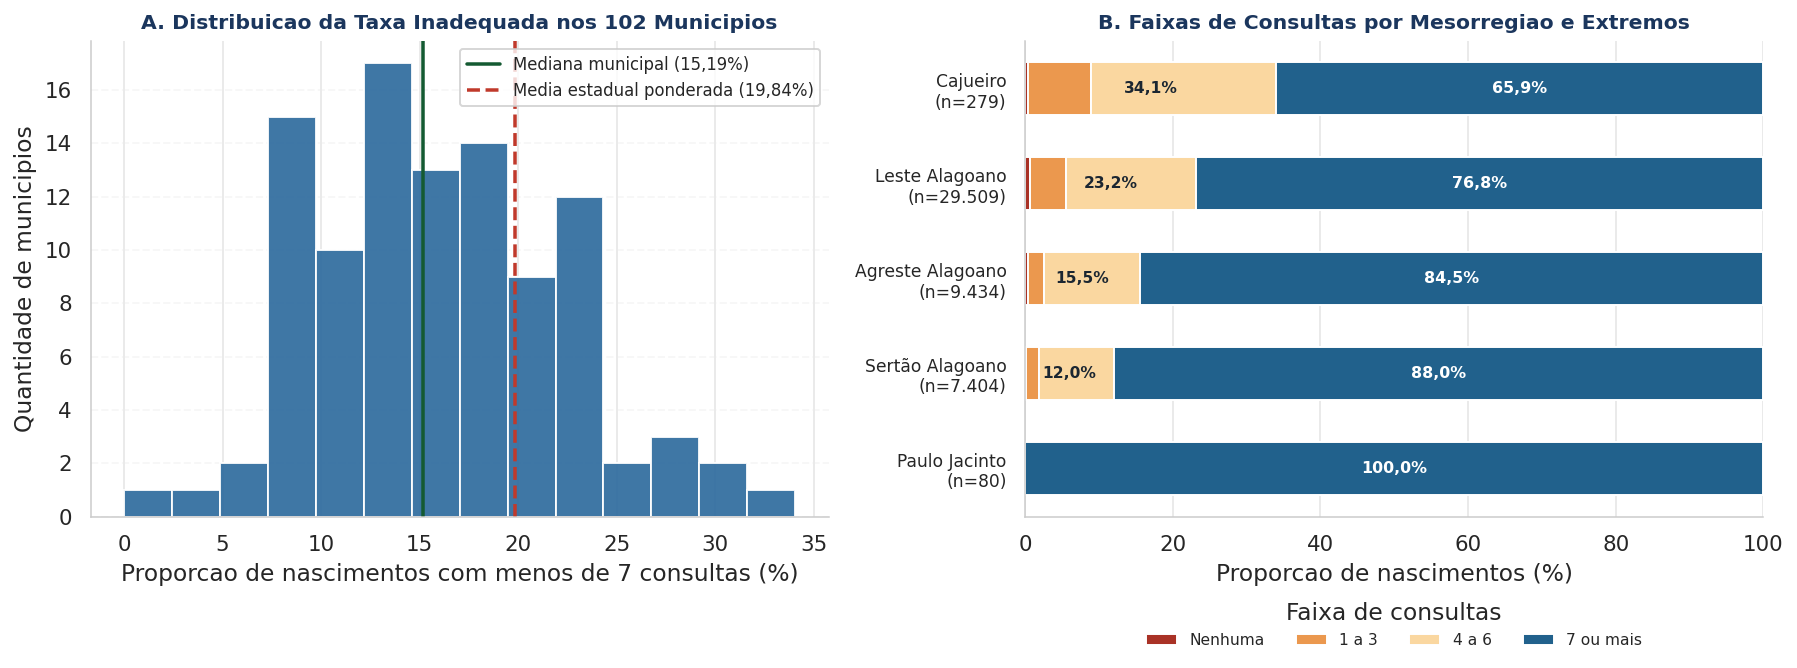

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mediana_mun = mun['taxa_inadequado'].median()
axes[0].hist(mun['taxa_inadequado'], bins=14, color='#2E6B9E', edgecolor='white', alpha=0.92)
axes[0].axvline(mediana_mun, color='#145A32', linestyle='-', linewidth=1.8, label=f'Mediana municipal ({fmt_br(mediana_mun)}%)')
axes[0].axvline(taxa_estadual, color='#C0392B', linestyle='--', linewidth=1.8, label=f'Media estadual ponderada ({fmt_br(taxa_estadual)}%)')
axes[0].set_title('A. Distribuicao da Taxa Inadequada nos 102 Municipios', fontsize=10.5, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Proporcao de nascimentos com menos de 7 consultas (%)')
axes[0].set_ylabel('Quantidade de municipios')
axes[0].grid(axis='y', linestyle='--', alpha=0.35)
axes[0].legend(loc='upper right', fontsize=8.5)

meso_plot = df.groupby('MESORREGIAO').agg(
    n=('CONSULTAS', 'count'),
    pct_nenhuma=('CONSULTAS', lambda x: (x == 1).mean() * 100),
    pct_1a3=('CONSULTAS', lambda x: (x == 2).mean() * 100),
    pct_4a6=('CONSULTAS', lambda x: (x == 3).mean() * 100),
    pct_7mais=('CONSULTAS', lambda x: (x == 4).mean() * 100)
).reindex(['Leste Alagoano', 'Agreste Alagoano', 'Sertão Alagoano']).reset_index()
meso_plot['label'] = meso_plot.apply(lambda r: f"{r['MESORREGIAO']}\n(n={fmt_int(r['n'])})", axis=1)

extremos = mun[mun['MUNICIPIO'].isin(['Cajueiro', 'Paulo Jacinto'])].sort_values('taxa_inadequado', ascending=False).copy()
extremos['label'] = extremos.apply(lambda r: f"{r['MUNICIPIO']}\n(n={fmt_int(r['total_nasc'])})", axis=1)

comp = pd.concat([
    extremos.iloc[[0]][['label', 'pct_nenhuma', 'pct_1a3', 'pct_4a6', 'pct_7mais']],
    meso_plot[['label', 'pct_nenhuma', 'pct_1a3', 'pct_4a6', 'pct_7mais']],
    extremos.iloc[[1]][['label', 'pct_nenhuma', 'pct_1a3', 'pct_4a6', 'pct_7mais']]
], ignore_index=True).iloc[::-1]

y_pos = np.arange(len(comp))
axes[1].barh(y_pos, comp['pct_nenhuma'], color='#A93226', height=0.56, label='Nenhuma')
axes[1].barh(y_pos, comp['pct_1a3'], left=comp['pct_nenhuma'], color='#EB984E', height=0.56, label='1 a 3')
axes[1].barh(y_pos, comp['pct_4a6'], left=comp['pct_nenhuma'] + comp['pct_1a3'], color='#FAD7A0', height=0.56, label='4 a 6')
axes[1].barh(y_pos, comp['pct_7mais'], left=comp['pct_nenhuma'] + comp['pct_1a3'] + comp['pct_4a6'], color='#21618C', height=0.56, label='7 ou mais')

for idx, row in enumerate(comp.itertuples()):
    inad = row.pct_nenhuma + row.pct_1a3 + row.pct_4a6
    if inad >= 6:
        axes[1].text(inad / 2, idx, f'{fmt_br(inad, 1)}%', va='center', ha='center', fontsize=8, fontweight='bold', color='#1B2631')
    axes[1].text(inad + row.pct_7mais / 2, idx, f'{fmt_br(row.pct_7mais, 1)}%', va='center', ha='center', fontsize=8.2, fontweight='bold', color='white')

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(comp['label'], fontsize=8.8)
axes[1].set_xlim(0, 100)
axes[1].set_xlabel('Proporcao de nascimentos (%)')
axes[1].set_title('B. Faixas de Consultas por Mesorregiao e Extremos', fontsize=10.5, fontweight='bold', color='#1B365D')
axes[1].legend(title='Faixa de consultas', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(SAIDAS_Q2 / 'fig1_distribuicao_e_mesorregioes.png', bbox_inches='tight')
plt.show()

### 3.2 Distorção por Números Absolutos e Exercício de Visualização Enganosa (Entrega 5)

- Compara a correlação de Pearson ($r$) em valores absolutos com a correlação de postos de Spearman ($\rho$) na proporção relativa.
- Mostra o **Top 10 Absoluto (Enganoso)** versus o **Top 10 Proporcional (Corrigido)** (incluindo o empate exato de `Paripueira` e `Jacuípe` em `24,19%`), além da mudança de posições (`diff_rank`) nos casos emblemáticos e da exportação da tabela completa dos 102 municípios (`tabela_102_municipios_AL_2025.csv`).

=== 2.1 PROVA ESTATISTICA DA DISTORCAO POR NUMEROS ABSOLUTOS ===
Correlacao Total de Nascimentos vs. Casos Absolutos Inadequados (Pearson): r = 0,9868
Correlacao Total de Nascimentos vs. Proporcao % Inadequada (Spearman): rho = 0,0067

=== 2.2 QUADRO COMPARATIVO: TOP 10 ABSOLUTO (ENGANOSO) VS. TOP 10 PROPORCIONAL (CORRIGIDO) ===
Pos   Enganoso (Absoluto)  Casos <7  Taxa Abs (%)   Corrigido (Proporcao)      Mesorregiao  Nasc (n)  Taxa Prop (%)
 1o                Maceió      3934         30.43                Cajueiro   Leste Alagoano       279          34.05
 2o             Arapiraca       530         14.77  Barra de Santo Antônio   Leste Alagoano       264          31.06
 3o             Rio Largo       287         22.44                  Maceió   Leste Alagoano     12929          30.43
 4o   Palmeira dos Índios       199         19.13           Joaquim Gomes   Leste Alagoano       281          29.18
 5o      Marechal Deodoro       188         20.89        São José da Laje   Leste Alagoan

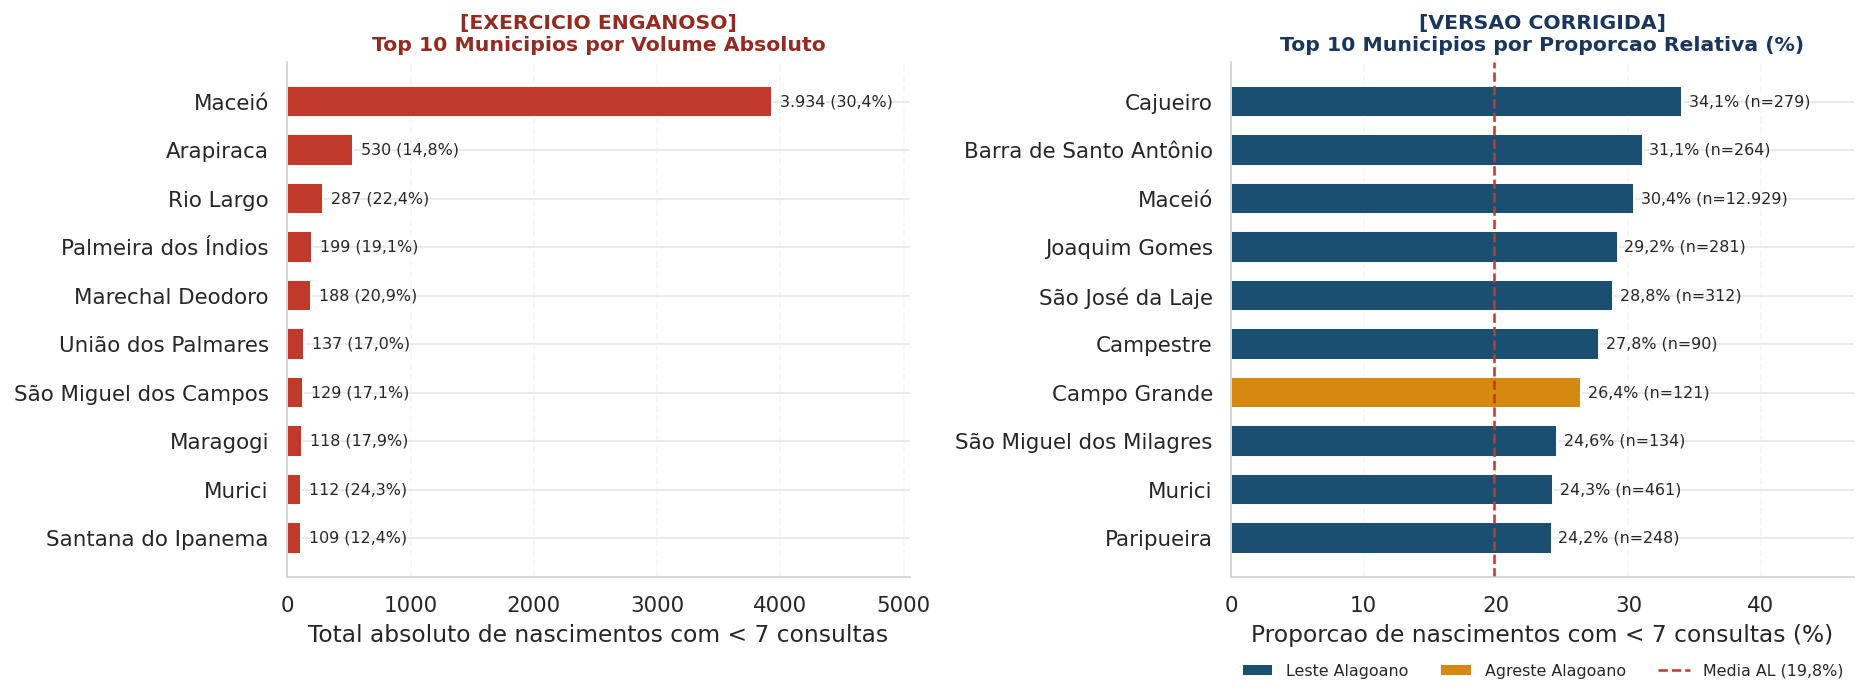

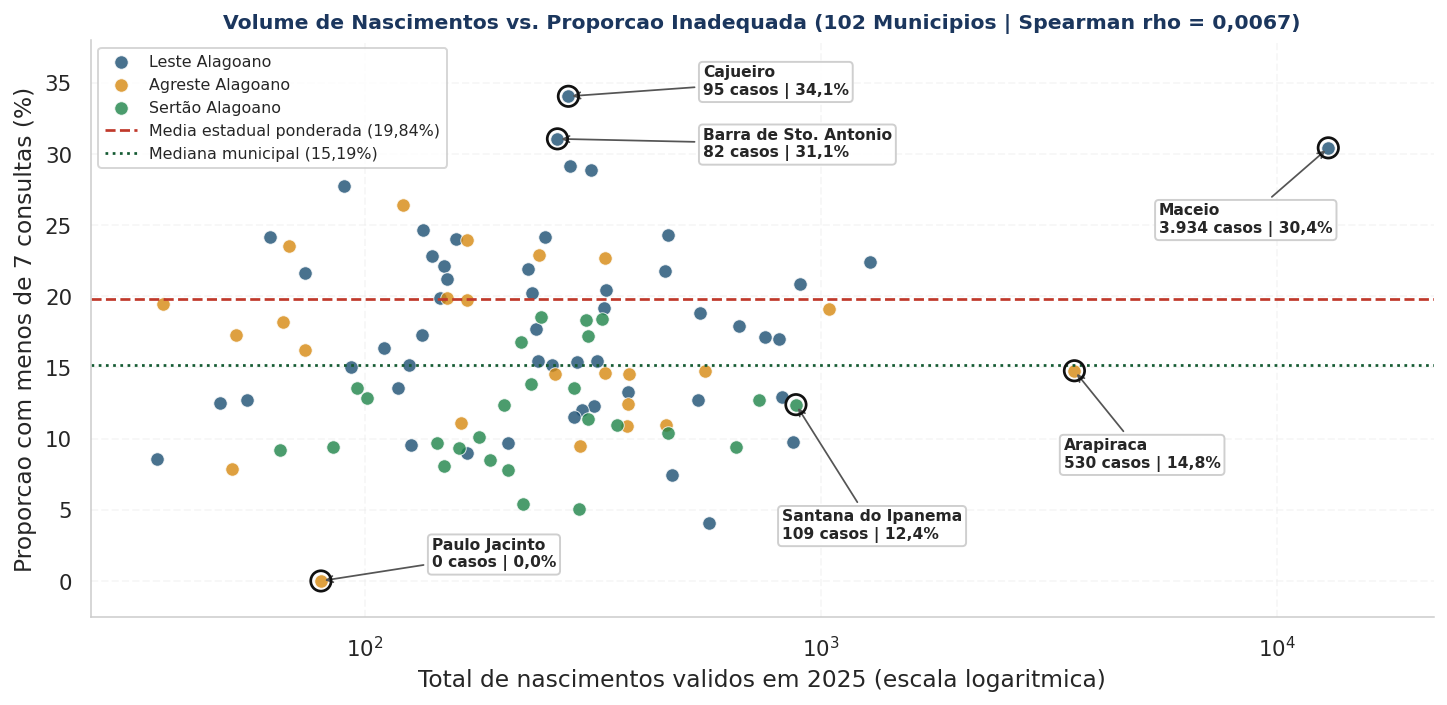

In [26]:
r_pearson = mun['total_nasc'].corr(mun['n_inadequado'], method='pearson')
rho_spearman = mun['total_nasc'].corr(mun['taxa_inadequado'], method='spearman')

print('=== 2.1 PROVA ESTATISTICA DA DISTORCAO POR NUMEROS ABSOLUTOS ===')
print(f'Correlacao Total de Nascimentos vs. Casos Absolutos Inadequados (Pearson): r = {fmt_br(r_pearson, 4)}')
print(f'Correlacao Total de Nascimentos vs. Proporcao % Inadequada (Spearman): rho = {fmt_br(rho_spearman, 4)}')

top10_abs = mun.sort_values(['n_inadequado', 'taxa_inadequado'], ascending=[False, False]).head(10).reset_index(drop=True)
top11_pct = mun.sort_values(['taxa_inadequado', 'total_nasc'], ascending=[False, False]).head(11).reset_index(drop=True)
top10_pct = top11_pct.head(10).copy()

comparativo = pd.DataFrame({
    'Pos': [f'{i}o' for i in range(1, 11)],
    'Enganoso (Absoluto)': top10_abs['MUNICIPIO'],
    'Casos <7': top10_abs['n_inadequado'],
    'Taxa Abs (%)': top10_abs['taxa_inadequado'].round(2),
    'Corrigido (Proporcao)': top10_pct['MUNICIPIO'],
    'Mesorregiao': top10_pct['MESORREGIAO'],
    'Nasc (n)': top10_pct['total_nasc'],
    'Taxa Prop (%)': top10_pct['taxa_inadequado'].round(2)
})
print('\n=== 2.2 QUADRO COMPARATIVO: TOP 10 ABSOLUTO (ENGANOSO) VS. TOP 10 PROPORCIONAL (CORRIGIDO) ===')
print(comparativo.to_string(index=False))
print('\n*Empate exato na 10a posicao proporcional (24,1935%):')
print(top11_pct.iloc[[9, 10]][['MUNICIPIO', 'MESORREGIAO', 'total_nasc', 'n_inadequado', 'taxa_inadequado']].to_string(index=False))

# Mudanca de posicoes (diff_rank = rank_abs - rank_prop) nos municipios emblemáticos do painel HTML
emblematicos = ['Cajueiro', 'Barra de Santo Antônio', 'Maceió', 'Murici', 'Arapiraca', 'Santana do Ipanema', 'Paulo Jacinto']
df_emb = mun[mun['MUNICIPIO'].isin(emblematicos)].sort_values('rank_prop')
print('\n=== 2.3 MUDANCA DE POSICAO NO RANKING (ABSOLUTO -> PROPORCIONAL) ===')
print(df_emb[['rank_prop', 'rank_abs', 'diff_rank', 'MUNICIPIO', 'MESORREGIAO', 'total_nasc', 'n_inadequado', 'taxa_inadequado', 'ign_cod9']].round({'taxa_inadequado': 2}).to_string(index=False))

# Exportar tabela completa dos 102 municipios (espelho do Explorador do painel HTML)
cols_exp = ['rank_prop', 'rank_abs', 'diff_rank', 'CODMUNRES', 'MUNICIPIO', 'MESORREGIAO', 'MICRORREGIAO',
            'total_nasc', 'n_inadequado', 'taxa_inadequado', 'c1_nenhuma', 'c2_1a3', 'c3_4a6', 'c4_7mais', 'ign_cod9']
df_102 = mun.sort_values('rank_prop')[cols_exp].copy()
df_102['taxa_inadequado'] = df_102['taxa_inadequado'].round(2)
df_102.to_csv(SAIDAS_Q2 / 'tabela_102_municipios_AL_2025.csv', sep=';', index=False, encoding='utf-8-sig')
print('\nTabela completa dos 102 municipios salva em: tabela_102_municipios_AL_2025.csv')

cores_meso = {
    'Leste Alagoano': '#1B4F72',
    'Agreste Alagoano': '#D68910',
    'Sertão Alagoano': '#1E8449'
}

# Visualizacao 2: Enganoso vs. Corrigido
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

t_abs_plot = top10_abs.iloc[::-1]
bars_abs = axes[0].barh(t_abs_plot['MUNICIPIO'], t_abs_plot['n_inadequado'], color='#C0392B', height=0.65)
axes[0].set_title('[EXERCICIO ENGANOSO]\nTop 10 Municipios por Volume Absoluto', fontsize=10.5, fontweight='bold', color='#922B21')
axes[0].set_xlabel('Total absoluto de nascimentos com < 7 consultas')
axes[0].set_xlim(0, 5050)
axes[0].grid(axis='x', linestyle='--', alpha=0.35)
for bar, row in zip(bars_abs, t_abs_plot.itertuples()):
    axes[0].text(row.n_inadequado + 65, bar.get_y() + bar.get_height()/2,
                 f'{fmt_int(row.n_inadequado)} ({fmt_br(row.taxa_inadequado, 1)}%)', va='center', fontsize=8.2)

t_pct_plot = top10_pct.iloc[::-1]
bars_pct = axes[1].barh(t_pct_plot['MUNICIPIO'], t_pct_plot['taxa_inadequado'],
                        color=[cores_meso[m] for m in t_pct_plot['MESORREGIAO']], height=0.65)
axes[1].axvline(taxa_estadual, color='#C0392B', linestyle='--', linewidth=1.3)
axes[1].set_title('[VERSAO CORRIGIDA]\nTop 10 Municipios por Proporcao Relativa (%)', fontsize=10.5, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Proporcao de nascimentos com < 7 consultas (%)')
axes[1].set_xlim(0, 47)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
for bar, row in zip(bars_pct, t_pct_plot.itertuples()):
    axes[1].text(row.taxa_inadequado + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{fmt_br(row.taxa_inadequado, 1)}% (n={fmt_int(row.total_nasc)})', va='center', fontsize=8.2)

leg_el = [
    Patch(facecolor='#1B4F72', label='Leste Alagoano'),
    Patch(facecolor='#D68910', label='Agreste Alagoano'),
    plt.Line2D([0], [0], color='#C0392B', lw=1.3, linestyle='--', label=f'Media AL ({fmt_br(taxa_estadual, 1)}%)')
]
axes[1].legend(handles=leg_el, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8.2, frameon=False)

plt.tight_layout()
plt.savefig(SAIDAS_Q2 / 'fig2_enganoso_vs_corrigido.png', bbox_inches='tight')
plt.show()

# Visualizacao 3: Dispersao Volume (log) vs. Proporcao (%)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for meso_nome, cor in cores_meso.items():
    sub_m = mun[mun['MESORREGIAO'] == meso_nome]
    ax.scatter(sub_m['total_nasc'], sub_m['taxa_inadequado'], alpha=0.8, color=cor, s=48, label=meso_nome, edgecolors='white', lw=0.5)

ax.axhline(taxa_estadual, color='#C0392B', linestyle='--', lw=1.4, label=f'Media estadual ponderada ({fmt_br(taxa_estadual)}%)')
ax.axhline(mediana_mun, color='#145A32', linestyle=':', lw=1.4, label=f'Mediana municipal ({fmt_br(mediana_mun)}%)')

destaques = {
    'Maceió': ('Maceio\n3.934 casos | 30,4%', (5500, 24.5)),
    'Arapiraca': ('Arapiraca\n530 casos | 14,8%', (3400, 8.0)),
    'Cajueiro': ('Cajueiro\n95 casos | 34,1%', (550, 34.2)),
    'Barra de Santo Antônio': ('Barra de Sto. Antonio\n82 casos | 31,1%', (550, 29.8)),
    'Santana do Ipanema': ('Santana do Ipanema\n109 casos | 12,4%', (820, 3.0)),
    'Paulo Jacinto': ('Paulo Jacinto\n0 casos | 0,0%', (140, 1.0))
}
for nome_m, (txt, (tx, ty)) in destaques.items():
    r = mun[mun['MUNICIPIO'] == nome_m].iloc[0]
    ax.scatter(r['total_nasc'], r['taxa_inadequado'], edgecolor='#111111', facecolor='none', s=110, lw=1.4, zorder=6)
    ax.annotate(txt, xy=(r['total_nasc'], r['taxa_inadequado']), xytext=(tx, ty), fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#CCCCCC', alpha=0.94),
                arrowprops=dict(arrowstyle='->', color='#555555', lw=0.9))

ax.set_xscale('log')
ax.set_xlim(25, 22000)
ax.set_ylim(-2.5, 38)
ax.set_title(f'Volume de Nascimentos vs. Proporcao Inadequada (102 Municipios | Spearman rho = {fmt_br(rho_spearman, 4)})',
             fontsize=10.5, fontweight='bold', color='#1B365D')
ax.set_xlabel('Total de nascimentos validos em 2025 (escala logaritmica)')
ax.set_ylabel('Proporcao com menos de 7 consultas (%)')
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend(loc='upper left', fontsize=8.2)
plt.tight_layout()
plt.savefig(SAIDAS_Q2 / 'fig3_dispersao_territorial.png', bbox_inches='tight')
plt.show()

### 3.3 Investigação Forense dos Registros Ignorados (`CONSULTAS == 9`) e Qualidade da Base Bruta

Retorna à base original (`SINASC_AL_2025_residencia.csv`, 46.398 registros) para reproduzir integralmente a **Aba 4 do Painel HTML** e responder por que os registros foram ignorados e o que eles revelam:
1. Distribuição por município de residência (9 municípios).
2. Origem institucional por estabelecimento de saúde (`CODESTAB` / CNES: 4 de 157 unidades) e local do parto (`LOCNASC`).
3. Ocorrência mensal em 2025.
4. Perfil comparativo entre `Adequado (>= 7)`, `Inadequado (< 7)` e `Ignorado (código 9)`.
5. Análise de sensibilidade (Alagoas, Maceió e Campestre).
6. **Tabela de qualidade de preenchimento das 9 principais variáveis da base bruta** (`IDADEPAI`, `DTULTMENST`, `CODOCUPMAE`, `MESPRENAT`, `ESTCIVMAE`, `RACACORMAE`, `ESCMAE`, `CONSPRENAT` e `CONSULTAS`).

Total na base original: 46.398 | Ignorados (CONSULTAS=9): 51 (0,11%)
Estabelecimentos (CNES) totais na base: 157 | CNES com ignorados: 4

=== 3.1 REGISTROS IGNORADOS POR MUNICIPIO DE RESIDENCIA ===
 CODMUNRES            MUNICIPIO      MESORREGIAO  ignorados  pct_dos_51
    270430               Maceió   Leste Alagoano         42       82.35
    270135            Campestre   Leste Alagoano          2        3.92
    270040              Atalaia   Leste Alagoano          1        1.96
    270130             Cajueiro   Leste Alagoano          1        1.96
    270210   Colônia Leopoldina   Leste Alagoano          1        1.96
    270480            Maribondo Agreste Alagoano          1        1.96
    270850 São Luís do Quitunde   Leste Alagoano          1        1.96
    270890               Satuba   Leste Alagoano          1        1.96
    270940               Viçosa   Leste Alagoano          1        1.96

=== 3.2 CONCENTRACAO INSTITUCIONAL (4 DE 157 CNES) ===
   CNES                   

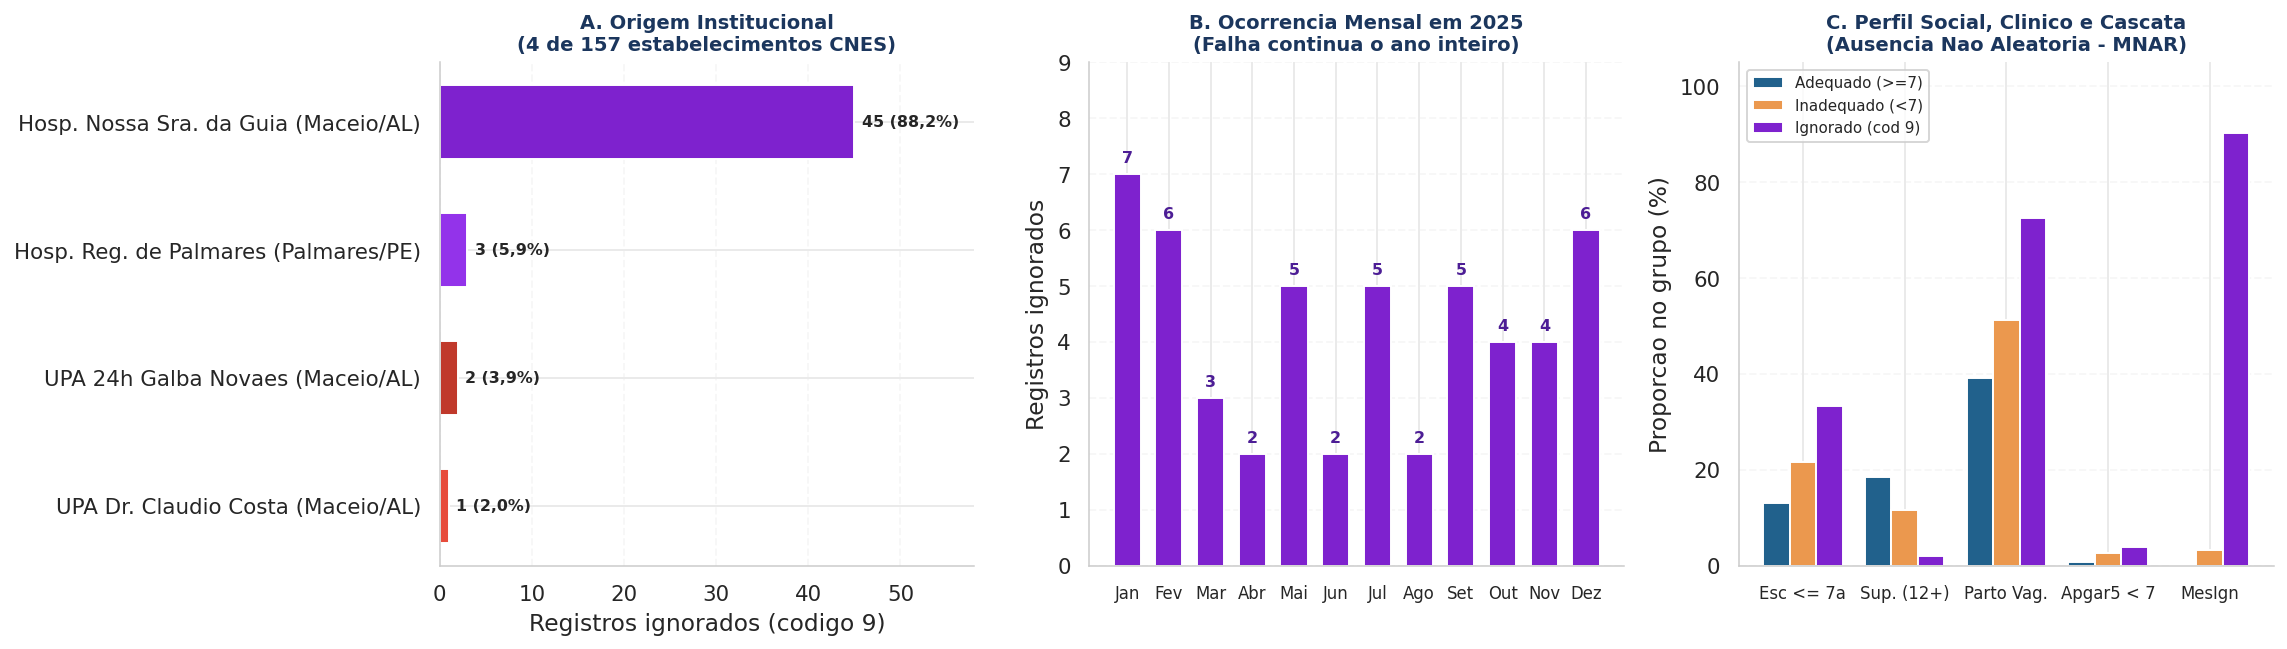

In [27]:
if df_raw is None:
    print('Aviso: localize SINASC_AL_2025_residencia.csv para executar a auditoria dos 51 registros ignorados.')
else:
    ign = df_raw[df_raw['CONSULTAS'] == 9].copy()
    val = df_raw[df_raw['CONSULTAS'].isin([1, 2, 3, 4])].copy()
    val_adeq = val[val['CONSULTAS'] == 4]
    val_inad = val[val['CONSULTAS'] < 4]

    print(f'Total na base original: {fmt_int(len(df_raw))} | Ignorados (CONSULTAS=9): {len(ign)} ({fmt_br(len(ign)/len(df_raw)*100)}%)')
    print(f'Estabelecimentos (CNES) totais na base: {df_raw["CODESTAB"].nunique()} | CNES com ignorados: {ign["CODESTAB"].nunique()}')

    print('\n=== 3.1 REGISTROS IGNORADOS POR MUNICIPIO DE RESIDENCIA ===')
    ign_mun = ign.groupby(['CODMUNRES', 'MUNICIPIO', 'MESORREGIAO']).size().reset_index(name='ignorados').sort_values('ignorados', ascending=False)
    ign_mun['pct_dos_51'] = (ign_mun['ignorados'] / len(ign) * 100).round(2)
    print(ign_mun.to_string(index=False))

    mapa_cnes = {
        6303153.0: 'Hosp. Nossa Sra. da Guia (Maceio/AL)',
        2428393.0: 'Hosp. Reg. de Palmares (Palmares/PE)',
        4156714.0: 'UPA 24h Galba Novaes (Maceio/AL)',
        2008769.0: 'UPA Dr. Claudio Costa (Maceio/AL)'
    }
    rows_cnes = []
    for cnes_id, qtd_ign in ign['CODESTAB'].value_counts().items():
        sub = df_raw[df_raw['CODESTAB'] == cnes_id]
        sub_v = sub[sub['CONSULTAS'].isin([1, 2, 3, 4])]
        rows_cnes.append({
            'CNES': int(cnes_id),
            'Estabelecimento': mapa_cnes.get(cnes_id, str(int(cnes_id))),
            'Ignorados': int(qtd_ign),
            'Nasc_CNES': int(len(sub)),
            'Taxa_Ign_%': round(qtd_ign / len(sub) * 100, 2),
            'Inad_Validos_%': round((sub_v['CONSULTAS'] < 4).mean() * 100, 2) if len(sub_v) > 0 else np.nan
        })
    df_cnes = pd.DataFrame(rows_cnes)
    print('\n=== 3.2 CONCENTRACAO INSTITUCIONAL (4 DE 157 CNES) ===')
    print(df_cnes.to_string(index=False))

    loc_hosp_ign = (ign['LOCNASC'] == 1).sum()
    loc_hosp_tot = (df_raw['LOCNASC'] == 1).sum()
    loc_upa_ign = (ign['LOCNASC'] == 2).sum()
    loc_upa_tot = (df_raw['LOCNASC'] == 2).sum()
    print('\n=== 3.3 LOCAL DO PARTO (LOCNASC) ===')
    print(f'Hospitais (cod 1): {loc_hosp_ign} ignorados em {fmt_int(loc_hosp_tot)} partos ({fmt_br(loc_hosp_ign/loc_hosp_tot*100)}%)')
    print(f'Outros estab. / UPAs (cod 2): {loc_upa_ign} ignorados em {fmt_int(loc_upa_tot)} partos ({fmt_br(loc_upa_ign/loc_upa_tot*100)}%) -> {(loc_upa_ign/loc_upa_tot)/(loc_hosp_ign/loc_hosp_tot):.1f}x maior')

    def resumir_grupo(d, nome):
        return {
            'Grupo': nome,
            'n': len(d),
            'Esc<=7a(%)': round(d['ESCMAE'].isin([1, 2, 3]).mean() * 100, 1),
            'Esc12+a(%)': round((d['ESCMAE'] == 5).mean() * 100, 1),
            'Preta/Parda(%)': round(d['RACACORMAE'].isin([2, 4]).mean() * 100, 1),
            'PartoVag(%)': round((d['PARTO'] == 1).mean() * 100, 1),
            'Apgar5<7(%)': round((d['APGAR5'] < 7).mean() * 100, 2),
            'MesPreNat_Ign(%)': round((d['MESPRENAT'].isna() | (d['MESPRENAT'] == 99)).mean() * 100, 2),
            'Kotelchuck_Ign(%)': round((d['KOTELCHUCK'].isna() | (d['KOTELCHUCK'] == 9)).mean() * 100, 2),
            'AtrasoMed_DIFDATA(d)': round(d['DIFDATA'].median(), 1),
            'AtrasoMedia_DIFDATA(d)': round(d['DIFDATA'].mean(), 1)
        }

    df_perfil_3 = pd.DataFrame([
        resumir_grupo(val_adeq, 'Adequado (>= 7)'),
        resumir_grupo(val_inad, 'Inadequado (< 7)'),
        resumir_grupo(ign, 'Ignorado (cod 9)')
    ])
    print('\n=== 3.4 PERFIL SOCIOECONOMICO, CLINICO E OPERACIONAL DOS 3 GRUPOS ===')
    print(df_perfil_3.to_string(index=False))

    def sensibilidade(sub, nome):
        tot = len(sub)
        n_ign = int((sub['CONSULTAS'] == 9).sum())
        n_inad = int(sub['CONSULTAS'].isin([1, 2, 3]).sum())
        n_val = tot - n_ign
        t_obs = n_inad / n_val * 100
        t_oti = n_inad / tot * 100
        t_pes = (n_inad + n_ign) / tot * 100
        return {
            'Recorte': nome, 'Originais': tot, 'Ignorados': n_ign,
            'Observado_%': round(t_obs, 2),
            'Otimista_%': round(t_oti, 2),
            'Pessimista_%': round(t_pes, 2),
            'Delta_Pess_pp': round(t_pes - t_obs, 2)
        }

    df_sens = pd.DataFrame([
        sensibilidade(df_raw, 'Alagoas (Estado)'),
        sensibilidade(df_raw[df_raw['CODMUNRES'] == 270430], 'Maceio (Capital)'),
        sensibilidade(df_raw[df_raw['CODMUNRES'] == 270135], 'Campestre (Pequeno porte)')
    ])
    print('\n=== 3.5 ANALISE DE SENSIBILIDADE DOS REGISTROS IGNORADOS ===')
    print(df_sens.to_string(index=False))

    # 3.6 Qualidade de preenchimento das 9 principais variaveis na base bruta (espelho da tabela do HTML)
    specs_omissao = [
        ('IDADEPAI',   [99], 'Idade do pai'),
        ('DTULTMENST', [],   'Data da ultima menstruacao'),
        ('CODOCUPMAE', [],   'Ocupacao da mae'),
        ('MESPRENAT',  [99], 'Mes de inicio do pre-natal'),
        ('ESTCIVMAE',  [9],  'Estado civil materno'),
        ('RACACORMAE', [9],  'Raca/cor materna'),
        ('ESCMAE',     [9],  'Escolaridade materna'),
        ('CONSPRENAT', [99], 'Numero exato de consultas'),
        ('CONSULTAS',  [9],  'Faixa de consultas (Alvo)')
    ]
    rows_omissao = []
    for col_v, cods_ign, desc_v in specs_omissao:
        n_nan = int(df_raw[col_v].isna().sum())
        n_cod = int(df_raw[col_v].isin(cods_ign).sum()) if cods_ign else 0
        tot_aus = n_nan + n_cod
        rows_omissao.append({
            'Variavel': col_v,
            'Descricao': desc_v,
            'Nulo_NaN': n_nan,
            'Cod_Ign': n_cod,
            'Total_Ausente': tot_aus,
            '%_Base': round(tot_aus / len(df_raw) * 100, 2)
        })
    df_qualidade_vars = pd.DataFrame(rows_omissao)
    print('\n=== 3.6 QUALIDADE DE PREENCHIMENTO DAS 9 PRINCIPAIS VARIAVEIS (BASE BRUTA, N = 46.398) ===')
    print(df_qualidade_vars.to_string(index=False))

    # Visualizacao 4: Painel Forense dos Registros Ignorados
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

    cnes_plot = df_cnes.iloc[::-1]
    bars_c = axes[0].barh(cnes_plot['Estabelecimento'], cnes_plot['Ignorados'], color=['#E74C3C', '#C0392B', '#9333EA', '#7E22CE'], height=0.58)
    axes[0].set_title('A. Origem Institucional\n(4 de 157 estabelecimentos CNES)', fontsize=10, fontweight='bold', color='#1B365D')
    axes[0].set_xlabel('Registros ignorados (codigo 9)')
    axes[0].set_xlim(0, 58)
    axes[0].grid(axis='x', linestyle='--', alpha=0.35)
    for bar, row in zip(bars_c, cnes_plot.itertuples()):
        axes[0].text(row.Ignorados + 0.8, bar.get_y() + bar.get_height()/2,
                     f'{row.Ignorados} ({fmt_br(row.Ignorados/51*100, 1)}%)', va='center', fontsize=8.2, fontweight='bold')

    ign['MES_NASC'] = ign['DTNASC'].astype(str).str.zfill(8).str[2:4].astype(int)
    mes_counts = [int((ign['MES_NASC'] == m).sum()) for m in range(1, 13)]
    meses_lbl = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
    bars_m = axes[1].bar(meses_lbl, mes_counts, color='#7E22CE', width=0.65)
    axes[1].set_title('B. Ocorrencia Mensal em 2025\n(Falha continua o ano inteiro)', fontsize=10, fontweight='bold', color='#1B365D')
    axes[1].set_ylabel('Registros ignorados')
    axes[1].set_ylim(0, 9)
    axes[1].tick_params(axis='x', labelsize=8.5)
    axes[1].grid(axis='y', linestyle='--', alpha=0.35)
    for bar, val_m in zip(bars_m, mes_counts):
        axes[1].text(bar.get_x() + bar.get_width()/2, val_m + 0.2, str(val_m), ha='center', fontsize=8.2, fontweight='bold', color='#4C1D95')

    metricas = ['Esc <= 7a', 'Sup. (12+)', 'Parto Vag.', 'Apgar5 < 7', 'MesIgn']
    v_adeq = [df_perfil_3.loc[0, 'Esc<=7a(%)'], df_perfil_3.loc[0, 'Esc12+a(%)'], df_perfil_3.loc[0, 'PartoVag(%)'], df_perfil_3.loc[0, 'Apgar5<7(%)'], df_perfil_3.loc[0, 'MesPreNat_Ign(%)']]
    v_inad = [df_perfil_3.loc[1, 'Esc<=7a(%)'], df_perfil_3.loc[1, 'Esc12+a(%)'], df_perfil_3.loc[1, 'PartoVag(%)'], df_perfil_3.loc[1, 'Apgar5<7(%)'], df_perfil_3.loc[1, 'MesPreNat_Ign(%)']]
    v_ign  = [df_perfil_3.loc[2, 'Esc<=7a(%)'], df_perfil_3.loc[2, 'Esc12+a(%)'], df_perfil_3.loc[2, 'PartoVag(%)'], df_perfil_3.loc[2, 'Apgar5<7(%)'], df_perfil_3.loc[2, 'MesPreNat_Ign(%)']]
    x = np.arange(len(metricas))
    w = 0.26
    axes[2].bar(x - w, v_adeq, width=w, color='#21618C', label='Adequado (>=7)')
    axes[2].bar(x,     v_inad, width=w, color='#EB984E', label='Inadequado (<7)')
    axes[2].bar(x + w, v_ign,  width=w, color='#7E22CE', label='Ignorado (cod 9)')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(metricas, fontsize=8.5)
    axes[2].set_ylim(0, 105)
    axes[2].set_ylabel('Proporcao no grupo (%)')
    axes[2].set_title('C. Perfil Social, Clinico e Cascata\n(Ausencia Nao Aleatoria - MNAR)', fontsize=10, fontweight='bold', color='#1B365D')
    axes[2].grid(axis='y', linestyle='--', alpha=0.35)
    axes[2].legend(loc='upper left', fontsize=7.8)

    plt.tight_layout()
    plt.savefig(SAIDAS_Q2 / 'fig4_investigacao_ignorados.png', bbox_inches='tight')
    plt.show()

### 3.4 Exportação dos gráficos e da tabela municipal

O pacote com as quatro figuras e o CSV dos 102 municípios fica na pasta de saídas da pergunta 2.

In [28]:
arquivos_saida = [
    'fig1_distribuicao_e_mesorregioes.png',
    'fig2_enganoso_vs_corrigido.png',
    'fig3_dispersao_territorial.png',
    'fig4_investigacao_ignorados.png',
    'tabela_102_municipios_AL_2025.csv'
]
existentes = [f for f in arquivos_saida if (SAIDAS_Q2 / f).is_file()]
zip_saida = SAIDAS_Q2 / 'entregaveis_pergunta2_sinasc_al_2025.zip'

with zipfile.ZipFile(zip_saida, 'w', zipfile.ZIP_DEFLATED) as zf:
    for arq in existentes:
        zf.write(SAIDAS_Q2 / arq, arcname=arq)

print(f'Pacote salvo com {len(existentes)} arquivos: {zip_saida}')

Pacote salvo com 5 arquivos: Saídas do notebook\pergunta_2\entregaveis_pergunta2_sinasc_al_2025.zip


### 3.5 Síntese dos Resultados e Limitações Metodológicas

#### Principais Achados
1. **Desigualdade territorial:** A taxa de pré-natal inadequado varia de **0,00%** (`Paulo Jacinto`) a **34,05%** (`Cajueiro`), com mediana municipal de **15,19%** e taxa estadual ponderada de **19,84%**.
2. **Gradiente leste para oeste:** O **Leste Alagoano** concentra 9 dos 10 piores municípios e registra **23,18%** de inadequação ponderada, frente a **15,51%** no Agreste e **12,03%** no Sertão.
3. **Distorção por números absolutos:** Rankings brutos refletem o porte populacional ($r = 0,9868$), gerando falso alarme em polos como `Arapiraca` (`14,77%`) e `Santana do Ipanema` (`12,39%`), enquanto ocultam cidades menores vulneráveis. Na proporção relativa, a correlação cai para $\rho = 0,0067$.
4. **Auditoria dos 51 ignorados:** Concentram-se em apenas **4 de 157 CNES** (88,2% no Hospital Nossa Senhora da Guia), têm taxa **18,3x maior em UPAs** do que em hospitais e mostram perfil de ausência não aleatória (MNAR), com maior vulnerabilidade social, `72,5%` de parto vaginal, atraso médio de `82,0` dias na digitação e `90,2%` de omissão em cascata no mês de início do pré-natal.

#### Limitações Metodológicas
- **Quantidade não mede qualidade clínica:** O corte de 7 consultas não mede exames, vacinas ou início no 1º trimestre.
- **Denominadores pequenos:** Em municípios com menos de 100 nascimentos (`Pindoba`, `Mar Vermelho`, `Paulo Jacinto`), poucos casos causam forte oscilação percentual.
- **Sensibilidade dos ignorados:** No cenário pessimista, o impacto máximo é de `+0,09 p.p.` no estado e `+0,23 p.p.` em Maceió, mas chega a `+1,57 p.p.` em `Campestre`.

## 4. Pergunta 3 · Quanto o perfil materno e o município ajudam na previsão?

**Projeto AB2 · Introdução à Ciência de Dados · UFAL**

**Objetivo.** Avaliar se o perfil materno, o município de residência e o histórico obstétrico disponíveis no início da gestação ajudam a prever menos de sete consultas registradas até o parto. A unidade de análise é o nascido vivo de mãe residente em Alagoas.

**Resumo dos resultados.** A regressão logística 4a reduziu o erro das probabilidades frente à referência constante e teve ROC-AUC próxima de 0,70 nos testes de 2025 e 2026. Com o limiar fixado na validação, a sensibilidade foi de 85,22% e 86,13%, respectivamente.

**Execução.** Execute o notebook inteiro em ordem. As células iniciais preparam a base preditiva de 2025 a partir dos insumos. Use o README para instalar as dependências e localizar os arquivos de entrada.

### 4.1 Preparação dos dados para a previsão

Usamos o CSV preditivo de 2025 gerado na etapa de limpeza deste notebook. São 46.347 nascidos vivos com consultas informadas, após excluir 51 registros com alvo ignorado. Para a previsão, o CSV mantém o mês de nascimento e os campos usados no modelo e na avaliação. O alvo vale 1 para zero a seis consultas registradas e 0 para sete ou mais.

Fontes: [SINASC 2025 preliminar](https://dadosabertos.saude.gov.br/dataset/sistema-de-informacao-sobre-nascidos-vivos-sinasc/resource/7f63d984-97aa-44da-891d-72b1dd6c5122) · [SINASC 2026, segunda prévia](https://dadosabertos.saude.gov.br/dataset/sistema-de-informacao-sobre-nascidos-vivos-sinasc/resource/6bb82548-4f33-4eb0-8e32-e1be63b4413b).

In [29]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import display

arquivo_2025 = TRATADOS_AB2 / "base_preditiva_SINASC_AL_2025.csv"
colunas_codigo = ["ESCMAE", "ESTCIVMAE", "CODMUNRES", "RACACORMAE", "CONSULTAS"]
colunas_numericas = [
    "IDADEMAE", "QTDGESTANT", "QTDFILVIVO", "QTDFILMORT", "SEMAGESTAC",
    "CONSPRENAT", "MENOS_7_CONSULTAS",
]
base_supervisionada = pd.read_csv(arquivo_2025, sep=";", encoding="utf-8-sig", dtype={
    **dict.fromkeys(["MES_NASCIMENTO", *colunas_codigo], "string"),
    **dict.fromkeys(colunas_numericas, "Int64"),
})
municipios = json.loads(
    entrada_ibge.read_text(encoding="utf-8-sig")
)
if not base_supervisionada["MENOS_7_CONSULTAS"].isin([0, 1]).all():
    raise ValueError("O CSV preditivo deve conter apenas alvos 0 e 1.")

linhas, colunas = base_supervisionada.shape
print(f"Base preditiva de 2025: {linhas} registros e {colunas} colunas.")

entradas_finais_2025 = ["IDADEMAE", "ESCMAE", "ESTCIVMAE", "CODMUNRES",
                        "QTDGESTANT", "QTDFILVIVO", "QTDFILMORT"]
faltantes = base_supervisionada[entradas_finais_2025].isna()
display(pd.DataFrame({
    "Registros sem informação": faltantes.sum(),
    "Percentual sem informação": faltantes.mean().map(lambda taxa: f"{taxa:.2%}".replace(".", ",")),
}))

Base preditiva de 2025: 46347 registros e 17 colunas.


,Registros sem informação,Percentual sem informação
IDADEMAE,0,"0,00%"
ESCMAE,78,"0,17%"
ESTCIVMAE,168,"0,36%"
CODMUNRES,0,"0,00%"
QTDGESTANT,44,"0,09%"
QTDFILVIVO,71,"0,15%"
QTDFILMORT,89,"0,19%"


#### Divisão temporal

Janeiro a agosto de 2025 compõem o ajuste inicial, setembro e outubro a validação, e novembro e dezembro o teste principal.

**Motivo.** O objetivo é verificar se o modelo funciona em registros de meses posteriores. Usamos o mês de nascimento só para separar os dados. Gestações de blocos diferentes podem ter ocorrido nos mesmos meses, pois a data disponível é a do parto.

In [30]:
mes = pd.to_datetime(base_supervisionada["MES_NASCIMENTO"], format="%Y-%m", errors="coerce")
if not mes.dt.year.eq(2025).all():
    raise ValueError("O CSV preditivo contém mês ausente, inválido ou fora de 2025.")
mapa_periodos = {**dict.fromkeys(range(1, 9), "Treino"),
                 9: "Validação", 10: "Validação", 11: "Teste", 12: "Teste"}
base_supervisionada["PARTICAO_2025"] = mes.dt.month.map(mapa_periodos).astype("string")
contagem_periodos = pd.crosstab(
    base_supervisionada["PARTICAO_2025"],
    base_supervisionada["MENOS_7_CONSULTAS"].map({0: "Sete ou mais", 1: "Menos de sete"}),
).reindex(["Treino", "Validação", "Teste"])
display(contagem_periodos.assign(Total=contagem_periodos.sum(axis=1)))

treino_tratado = base_supervisionada.loc[base_supervisionada["PARTICAO_2025"].eq("Treino")]

MENOS_7_CONSULTAS,Menos de sete,Sete ou mais,Total
PARTICAO_2025,,,
Treino,6671,24958,31629
Validação,1270,6220,7490
Teste,1252,5976,7228


### 4.2 Seleção de variáveis

**Entradas candidatas.** Idade, escolaridade, situação conjugal, município e antecedentes obstétricos. Testamos raça/cor como acréscimo separado. Idade e residência registradas no parto aproximam as informações disponíveis no início da gestação.

**Motivo.** As entradas simulam o que poderia ser conhecido no início da gestação. Duração final, prematuridade, peso e tipo de parto são observados depois. O número de consultas define ou permite conferir o alvo.

In [31]:
entradas_candidatas = {
    "Perfil materno": ["IDADEMAE", "ESCMAE", "ESTCIVMAE"],
    "Perfil materno e município": ["IDADEMAE", "ESCMAE", "ESTCIVMAE", "CODMUNRES"],
}
partes_supervisionadas = {
    nome: base_supervisionada.loc[base_supervisionada["PARTICAO_2025"].eq(nome)]
    for nome in ["Treino", "Validação", "Teste"]
}

### 4.3 Modelos e critérios de avaliação

**Motivo de testar dois modelos.** A regressão logística mede o ganho ao incluir blocos de variáveis. A árvore rasa testa se cortes e interações ajudam usando as mesmas entradas da regressão 4a. Essas duas comparações atendem à pergunta da AB2. A referência constante representa a frequência do alvo no treino.

| Critério | Interpretação |
|---|---|
| **Brier e Log Loss** | Medem o erro das probabilidades por registro. Menor é melhor. Log Loss penaliza mais os erros cometidos com alta confiança. |
| **ROC-AUC** | Mede a ordenação por risco. Uma ROC-AUC de 0,70 indica que, ao sortear um caso de menos de sete consultas e um de sete ou mais, o modelo tende a dar maior risco ao primeiro em cerca de 70% das comparações, contando meio ponto por empate. |
| **Calibração** | Compara as probabilidades previstas com as proporções observadas em grupos de registros com previsões semelhantes. |
| **Sensibilidade e precisão dos alertas** | Em um limiar fixo, medem quanto dos casos reais foi identificado e quanto dos alertas corresponde a casos reais. |

A acurácia fica como métrica complementar. Na validação, prever sete ou mais consultas para todos acertaria 83,04% dos registros e deixaria passar todos os casos de menos de sete. Para a regra de alerta, priorizamos identificar casos reais e comparamos a sensibilidade com o volume de falsos positivos.

### 4.4 Pré-processamento

| Variável | Regressão logística | Árvore rasa |
|---|---|---|
| Idade materna | Imputação pela mediana e padronização com `StandardScaler` | Imputação pela mediana, mantendo a escala em anos. As divisões da árvore dependem da ordem dos valores. |
| Escolaridade, situação conjugal, município e raça/cor, quando incluída | Codificação indicadora (*one-hot*) | Mesma codificação |
| Contagens do histórico obstétrico | Agrupamento em faixas seguido de *one-hot* | Mesmas faixas e codificação |

A idade foi a única variável padronizada nas regressões. A transformação calcula `(idade − média) / desvio-padrão` e fica no passo `idade → padronizacao` do pipeline. As categorias recebem indicadores 0/1 porque seus códigos identificam grupos. Os campos do histórico são agrupados em faixas para permitir diferenças de risco entre faixas e reunir contagens raras.

O pipeline estima a mediana, a média, o desvio-padrão e as categorias na janela de ajuste. Validação e testes recebem as transformações aprendidas nessa janela. Faltantes categóricos são representados por “Sem informação”, e categorias novas são aceitas pelo codificador.

In [32]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

entradas_v1 = entradas_candidatas["Perfil materno"]
colunas_categoricas_v1 = ["ESCMAE", "ESTCIVMAE"]
alvo = "MENOS_7_CONSULTAS"

def preparar_entradas(registros, entradas, colunas_categoricas):
    dados = registros[entradas].copy()
    dados["IDADEMAE"] = dados["IDADEMAE"].astype("float64")
    categorias = dados[colunas_categoricas].astype("object")
    dados[colunas_categoricas] = categorias.where(categorias.notna(), np.nan)
    return dados

treino_v1 = partes_supervisionadas["Treino"]
validacao_v1 = partes_supervisionadas["Validação"]
X_treino_v1 = preparar_entradas(treino_v1, entradas_v1, colunas_categoricas_v1)
X_validacao_v1 = preparar_entradas(validacao_v1, entradas_v1, colunas_categoricas_v1)
y_treino_v1 = treino_v1[alvo].astype(int)
y_validacao_v1 = validacao_v1[alvo].astype(int)

preparacao_v1 = ColumnTransformer([
    ("idade", Pipeline([
        ("mediana", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler()),
    ]), ["IDADEMAE"]),
    ("categorias", Pipeline([
        ("faltantes", SimpleImputer(strategy="constant", fill_value="Sem informação")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), colunas_categoricas_v1),
])
modelo_v1 = Pipeline([
    ("preparacao", preparacao_v1),
    ("regressao", LogisticRegression(max_iter=1000)),
])

### 4.5 Desenvolvimento na validação

Comparamos cada variável do perfil isoladamente, depois as três juntas. Mantemos a regressão para medir o ganho do município, do histórico obstétrico e de raça/cor. Na comparação de algoritmos, a árvore usa todas as entradas da regressão 4a, com a mesma validação de setembro e outubro.

In [33]:
probabilidades_validacao = {
    "Versão 0 · Referência": np.full(len(y_validacao_v1), y_treino_v1.mean()),
}

def avaliar_probabilidades(previsoes, y_real=None):
    if y_real is None:
        y_real = y_validacao_v1
    return pd.DataFrame.from_dict({
        versao: {
            "Brier": brier_score_loss(y_real, probabilidades),
            "Log loss": log_loss(y_real, probabilidades),
            "ROC-AUC": roc_auc_score(y_real, probabilidades),
            "Probabilidade média": probabilidades.mean(),
            "Proporção observada": y_real.mean(),
        }
        for versao, probabilidades in previsoes.items()
    }, orient="index")

#### Variáveis do perfil materno avaliadas separadamente

In [34]:
from sklearn.base import clone

experimentos_variaveis = {
    "Só idade": ["IDADEMAE"],
    "Só escolaridade": ["ESCMAE"],
    "Só situação conjugal": ["ESTCIVMAE"],
    "Sem idade": ["ESCMAE", "ESTCIVMAE"],
    "Sem escolaridade": ["IDADEMAE", "ESTCIVMAE"],
    "Sem situação conjugal": ["IDADEMAE", "ESCMAE"],
}

def prever_variacoes(configuracoes):
    probabilidades = {}
    for nome, entradas in configuracoes.items():
        transformacoes = []
        for etapa, transformador, colunas in preparacao_v1.transformers:
            colunas_selecionadas = [coluna for coluna in colunas if coluna in entradas]
            if colunas_selecionadas:
                transformacoes.append((etapa, clone(transformador), colunas_selecionadas))
        modelo_experimento = Pipeline([
            ("preparacao", ColumnTransformer(transformacoes)),
            ("regressao", clone(modelo_v1.named_steps["regressao"])),
        ])
        modelo_experimento.fit(X_treino_v1[entradas], y_treino_v1)
        probabilidades[nome] = modelo_experimento.predict_proba(
            X_validacao_v1[entradas]
        )[:, 1]
    return probabilidades


nomes_isoladas = ["Só idade", "Só escolaridade", "Só situação conjugal"]
previsoes_isoladas = prever_variacoes({nome: experimentos_variaveis[nome] for nome in nomes_isoladas})
display(avaliar_probabilidades({**probabilidades_validacao, **previsoes_isoladas}).round(4))

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
Versão 0 · Referência,0.1425,0.4606,0.5000,0.2109,0.1696
Só idade,0.1418,0.4580,0.5597,0.2114,0.1696
Só escolaridade,0.1405,0.4542,0.5675,0.2088,0.1696
Só situação conjugal,0.1406,0.4531,0.5830,0.2120,0.1696


#### Versão 1 · Perfil materno completo

A regressão usa idade, escolaridade e situação conjugal. Depois do ajuste, retiramos uma variável por vez para medir sua contribuição ao modelo completo.

In [35]:
modelo_v1.fit(X_treino_v1, y_treino_v1)
completo = "Versão 1 · Perfil materno"
probabilidades_validacao[completo] = modelo_v1.predict_proba(X_validacao_v1)[:, 1]
metricas_validacao = avaliar_probabilidades(probabilidades_validacao)
display(metricas_validacao.round(4))

nomes_retiradas = ["Sem idade", "Sem escolaridade", "Sem situação conjugal"]
previsoes_retiradas = prever_variacoes({nome: experimentos_variaveis[nome] for nome in nomes_retiradas})
colunas_metricas = ["Brier", "Log loss", "ROC-AUC"]
sem_uma = avaliar_probabilidades({
    completo: probabilidades_validacao[completo], **previsoes_retiradas
})[colunas_metricas]
delta_sem_uma = sem_uma.subtract(sem_uma.loc[completo]).add_prefix("Δ ")
display(sem_uma.join(delta_sem_uma).round(4))

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
Versão 0 · Referência,0.1425,0.4606,0.5000,0.2109,0.1696
Versão 1 · Perfil materno,0.1387,0.4481,0.6193,0.2101,0.1696


,Brier,Log loss,ROC-AUC,Δ Brier,Δ Log loss,Δ ROC-AUC
Versão 1 · Perfil materno,0.1387,0.4481,0.6193,0.0000,0.0000,0.0000
Sem idade,0.1391,0.4492,0.6118,0.0004,0.0011,-0.0075
Sem escolaridade,0.1403,0.4524,0.5958,0.0016,0.0043,-0.0235
Sem situação conjugal,0.1398,0.4519,0.5947,0.0011,0.0038,-0.0246


#### Versão 2 · Município de residência

O município entra como categoria.

In [36]:
entradas_v2 = entradas_candidatas["Perfil materno e município"]
categorias_v2 = [*colunas_categoricas_v1, "CODMUNRES"]
preparacao_v2 = ColumnTransformer([
    ("idade", clone(preparacao_v1.named_transformers_["idade"]), ["IDADEMAE"]),
    ("categorias", clone(preparacao_v1.named_transformers_["categorias"]), categorias_v2),
])
modelo_v2 = Pipeline([
    ("preparacao", preparacao_v2),
    ("regressao", clone(modelo_v1.named_steps["regressao"])),
])

X_treino_v2 = preparar_entradas(treino_v1, entradas_v2, categorias_v2)
X_validacao_v2 = preparar_entradas(validacao_v1, entradas_v2, categorias_v2)
modelo_v2.fit(X_treino_v2, y_treino_v1)
probabilidade_v2 = modelo_v2.predict_proba(X_validacao_v2)[:, 1]
nome_v2 = "Versão 2 · Perfil e município"
metricas_com_municipio = avaliar_probabilidades({
    **probabilidades_validacao, nome_v2: probabilidade_v2,
})
display(metricas_com_municipio.round(4))
display(
    metricas_com_municipio.loc[nome_v2, colunas_metricas]
    .subtract(metricas_com_municipio.loc[completo, colunas_metricas])
    .rename("Diferença da versão 2 em relação à versão 1")
    .round(5)
)

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
Versão 0 · Referência,0.1425,0.4606,0.5000,0.2109,0.1696
Versão 1 · Perfil materno,0.1387,0.4481,0.6193,0.2101,0.1696
Versão 2 · Perfil e município,0.1337,0.4308,0.6819,0.2114,0.1696


Brier      -0.00502
Log loss   -0.01725
ROC-AUC     0.06256
Name: Diferença da versão 2 em relação à versão 1, dtype: float64

#### Versão 3 · Gestações anteriores

Acrescentamos o número de gestações anteriores nas faixas 0, 1, 2 e 3 ou mais.

In [37]:
def acrescentar_historico(registros):
    dados = preparar_entradas(registros, entradas_v2, categorias_v2)
    faixas = pd.cut(
        registros["QTDGESTANT"],
        bins=[-1, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3 ou mais"],
    ).astype("object")
    dados["FAIXA_GESTACOES_ANTERIORES"] = faixas.where(faixas.notna(), np.nan)
    return dados

X_treino_v3 = acrescentar_historico(treino_v1)
X_validacao_v3 = acrescentar_historico(validacao_v1)
categorias_v3 = [*categorias_v2, "FAIXA_GESTACOES_ANTERIORES"]
modelo_v3 = clone(modelo_v2).set_params(preparacao=ColumnTransformer([
    ("idade", clone(preparacao_v2.named_transformers_["idade"]), ["IDADEMAE"]),
    ("categorias", clone(preparacao_v2.named_transformers_["categorias"]), categorias_v3),
]))
modelo_v3.fit(X_treino_v3, y_treino_v1)
probabilidade_v3 = modelo_v3.predict_proba(X_validacao_v3)[:, 1]

nome_v3 = "Versão 3 · Perfil, município e histórico"
metricas_com_historico = avaliar_probabilidades({
    nome_v2: probabilidade_v2,
    nome_v3: probabilidade_v3,
})
display(metricas_com_historico.round(5))

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
Versão 2 · Perfil e município,0.13372,0.43083,0.68186,0.21142,0.16956
"Versão 3 · Perfil, município e histórico",0.13092,0.42307,0.70269,0.21177,0.16956


#### Versões 4a e 4 · Histórico ampliado e raça/cor

A versão 4a inclui filhos nascidos vivos e perdas anteriores. A versão 4 acrescenta raça/cor materna para medir seu ganho adicional.

In [38]:
faixas_historico_v4 = {
    "FAIXA_FILHOS_VIVOS_ANTERIORES": ("QTDFILVIVO", [-1, 0, 1, 2, np.inf], ["0", "1", "2", "3 ou mais"]),
    "FAIXA_PERDAS_ANTERIORES": ("QTDFILMORT", [-1, 0, 1, np.inf], ["0", "1", "2 ou mais"]),
}

def preparar_entradas_v4(registros, incluir_raca_cor=False):
    dados = acrescentar_historico(registros)
    for destino, (origem, limites, rotulos) in faixas_historico_v4.items():
        faixa = pd.cut(registros[origem], bins=limites, labels=rotulos).astype("object")
        dados[destino] = faixa.where(faixa.notna(), np.nan)
    if incluir_raca_cor:
        raca_cor = registros["RACACORMAE"].astype("object")
        dados["RACACORMAE"] = raca_cor.where(raca_cor.notna(), np.nan)
    return dados

X_treino_v4 = preparar_entradas_v4(treino_v1, incluir_raca_cor=True)
X_validacao_v4 = preparar_entradas_v4(validacao_v1, incluir_raca_cor=True)
nome_v4a = "Versão 4a · Histórico ampliado"
nome_v4 = "Versão 4 · Histórico ampliado e raça/cor"
categorias_v4a = [*categorias_v3, *faixas_historico_v4]
categorias_por_versao_v4 = {
    nome_v4a: categorias_v4a,
    nome_v4: [*categorias_v4a, "RACACORMAE"],
}
probabilidades_extensoes = {nome_v3: probabilidade_v3}
modelos_extensoes = {}
for versao, categorias in categorias_por_versao_v4.items():
    entradas = ["IDADEMAE", *categorias]
    modelo = clone(modelo_v3).set_params(preparacao=ColumnTransformer([
        ("idade", clone(modelo_v3.named_steps["preparacao"].named_transformers_["idade"]), ["IDADEMAE"]),
        ("categorias", clone(modelo_v3.named_steps["preparacao"].named_transformers_["categorias"]), categorias),
    ]))
    modelo.fit(X_treino_v4[entradas], y_treino_v1)
    modelos_extensoes[versao] = modelo
    probabilidades_extensoes[versao] = modelo.predict_proba(X_validacao_v4[entradas])[:, 1]

metricas_extensoes = avaliar_probabilidades(probabilidades_extensoes)
display(metricas_extensoes.round(5))

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
"Versão 3 · Perfil, município e histórico",0.13092,0.42307,0.70269,0.21177,0.16956
Versão 4a · Histórico ampliado,0.12976,0.41954,0.71077,0.21137,0.16956
Versão 4 · Histórico ampliado e raça/cor,0.12972,0.41945,0.71111,0.21151,0.16956


##### Desempenho por raça/cor na validação

In [39]:
grupos_raca_cor = validacao_v1["RACACOR_DESC"].fillna("Sem informação")
linhas_grupos_v4 = []
for grupo, indices in grupos_raca_cor.groupby(grupos_raca_cor).groups.items():
    alvo_grupo = y_validacao_v1.loc[indices].to_numpy()
    posicoes = y_validacao_v1.index.get_indexer(indices)
    for versao in (nome_v4a, nome_v4):
        probabilidades = probabilidades_extensoes[versao][posicoes]
        linhas_grupos_v4.append({
            "Raça/cor materna": grupo,
            "Versão": versao,
            "Registros": len(alvo_grupo),
            "Casos reais": int(alvo_grupo.sum()),
            "Proporção observada": alvo_grupo.mean(),
            "Probabilidade média": probabilidades.mean(),
            "Brier": brier_score_loss(alvo_grupo, probabilidades),
        })
metricas_grupos_v4 = pd.DataFrame(linhas_grupos_v4)
display(metricas_grupos_v4.round(4))

,Raça/cor materna,Versão,Registros,Casos reais,Proporção observada,Probabilidade média,Brier
0,Amarela,Versão 4a · Histórico ampliado,53,12,0.2264,0.2231,0.1475
1,Amarela,Versão 4 · Histórico ampliado e raça/cor,53,12,0.2264,0.2154,0.1482
2,Branca,Versão 4a · Histórico ampliado,758,113,0.1491,0.1798,0.1242
3,Branca,Versão 4 · Histórico ampliado e raça/cor,758,113,0.1491,0.1705,0.1235
4,Indigena,Versão 4a · Histórico ampliado,41,1,0.0244,0.1988,0.0640
5,Indigena,Versão 4 · Histórico ampliado e raça/cor,41,1,0.0244,0.1388,0.0418
6,Parda,Versão 4a · Histórico ampliado,6420,1108,0.1726,0.2148,0.1308
7,Parda,Versão 4 · Histórico ampliado e raça/cor,6420,1108,0.1726,0.2161,0.1309
8,Preta,Versão 4a · Histórico ampliado,200,34,0.1700,0.2252,0.1292
9,Preta,Versão 4 · Histórico ampliado e raça/cor,200,34,0.1700,0.2396,0.1310


#### Ganho por bloco na regressão

O município trouxe o maior ganho na ordem testada. A ROC-AUC passou de 0,619 para 0,682 e o Brier caiu de 0,13875 para 0,13372. O histórico ampliado levou a ROC-AUC a 0,711. Incluir raça/cor depois do histórico mudou pouco as métricas gerais, por isso comparamos a árvore com a regressão 4a.

#### Árvore rasa · Mesmas entradas da regressão 4a

A árvore usa profundidade máxima de 3 e mínimo de 100 registros por folha. Comparamos as probabilidades e os alertas para a meta de sensibilidade de 90%.

In [40]:
from math import ceil
from sklearn.tree import DecisionTreeClassifier

entradas_arvore = ["IDADEMAE", *categorias_v4a]
preparacao_arvore = ColumnTransformer([
    ("idade", SimpleImputer(strategy="median"), ["IDADEMAE"]),
    ("categorias", clone(
        modelo_v3.named_steps["preparacao"].named_transformers_["categorias"]
    ), categorias_v4a),
])
modelo_arvore = Pipeline([
    ("preparacao", preparacao_arvore),
    ("arvore", DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=100, random_state=0
    )),
])
modelo_arvore.fit(X_treino_v4[entradas_arvore], y_treino_v1)
probabilidade_arvore = modelo_arvore.predict_proba(X_validacao_v4[entradas_arvore])[:, 1]
probabilidades_arvore_vs_regressao = {
    "Regressão 4a": probabilidades_extensoes[nome_v4a],
    "Árvore rasa": probabilidade_arvore,
}
metricas_arvore_vs_regressao = avaliar_probabilidades(probabilidades_arvore_vs_regressao)
display(metricas_arvore_vs_regressao.round(5))

,Brier,Log loss,ROC-AUC,Probabilidade média,Proporção observada
Regressão 4a,0.12976,0.41954,0.71077,0.21137,0.16956
Árvore rasa,0.13557,0.43805,0.64760,0.21223,0.16956


#### Definição do limiar na validação

Damos prioridade a identificar casos de menos de sete consultas. Para cada modelo, usamos o maior limiar que identifica pelo menos **90% dos casos reais** em setembro e outubro. Com 1.270 casos, isso exige pelo menos 1.143 alertas corretos. Entre os limiares que atingem a meta, o maior gera menos falsos positivos. Empates no limiar entram juntos e podem elevar a sensibilidade acima de 90%.

Depois de selecionar a regressão 4a, fixamos seu limiar e o aplicamos aos dois testes.

In [41]:
def avaliar_limiar(probabilidades, limiar, y_real):
    previu_sim = probabilidades >= limiar
    ocorreu_sim = y_real.to_numpy() == 1
    verdadeiros_positivos = int((previu_sim & ocorreu_sim).sum())
    falsos_positivos = int((previu_sim & ~ocorreu_sim).sum())
    falsos_negativos = int(ocorreu_sim.sum()) - verdadeiros_positivos
    return {
        "Limiar": limiar,
        "Casos identificados": verdadeiros_positivos,
        "Falsos positivos": falsos_positivos,
        "Falsos negativos": falsos_negativos,
        "Sensibilidade": verdadeiros_positivos / ocorreu_sim.sum(),
        "Precisão dos alertas": (
            verdadeiros_positivos / previu_sim.sum() if previu_sim.any() else float("nan")
        ),
    }

def limiar_para_sensibilidade(probabilidades, y_real, meta):
    casos_reais = y_real.to_numpy() == 1
    casos_alvo = ceil(meta * casos_reais.sum())
    probabilidades_dos_casos = np.sort(probabilidades[casos_reais])[::-1]
    return probabilidades_dos_casos[casos_alvo - 1]

def percentual(valor):
    return "" if pd.isna(valor) else f"{valor:.2%}".replace(".", ",")

def formatar_percentuais(tabela, colunas):
    return tabela.assign(**{coluna: tabela[coluna].map(percentual) for coluna in colunas})

def tabela_limiares(previsoes, limiares, y_real):
    return pd.DataFrame.from_dict({
        nome: avaliar_limiar(probabilidades, limiares[nome], y_real)
        for nome, probabilidades in previsoes.items()
    }, orient="index")

colunas_percentuais_alertas = ["Limiar", "Sensibilidade", "Precisão dos alertas"]

previsoes_para_comparar = {
    **probabilidades_validacao,
    nome_v2: probabilidade_v2,
    **probabilidades_extensoes,
    "Árvore rasa": probabilidade_arvore,
}
limiares_meta_90 = {
    nome: limiar_para_sensibilidade(probabilidades, y_validacao_v1, meta=0.90)
    for nome, probabilidades in previsoes_para_comparar.items()
}
comparacao_meta_90 = tabela_limiares(previsoes_para_comparar, limiares_meta_90, y_validacao_v1)

display(formatar_percentuais(comparacao_meta_90, colunas_percentuais_alertas))

limiar_final = limiares_meta_90[nome_v4a]
print(f"Limiar da regressão 4a fixado para os testes: {percentual(limiar_final)}")

,Limiar,Casos identificados,Falsos positivos,Falsos negativos,Sensibilidade,Precisão dos alertas
Versão 0 · Referência,"21,09%",1270,6220,0,"100,00%","16,96%"
Versão 1 · Perfil materno,"13,45%",1143,5126,127,"90,00%","18,23%"
Versão 2 · Perfil e município,"11,88%",1143,4629,127,"90,00%","19,80%"
"Versão 3 · Perfil, município e histórico","11,69%",1143,4546,127,"90,00%","20,09%"
Versão 4a · Histórico ampliado,"11,88%",1143,4391,127,"90,00%","20,65%"
Versão 4 · Histórico ampliado e raça/cor,"11,98%",1143,4366,127,"90,00%","20,75%"
Árvore rasa,"12,50%",1193,5452,77,"93,94%","17,95%"


Limiar da regressão 4a fixado para os testes: 11,88%


### 4.6 Testes temporais

#### Teste principal · Novembro e dezembro de 2025

A regressão 4a foi selecionada na validação. Reajustamos o pipeline em janeiro a outubro e aplicamos ao teste o limiar fixo de aproximadamente 11,88%.

In [42]:
modelo_escolhido = modelos_extensoes[nome_v4a]
entradas_finais = ["IDADEMAE", *categorias_v4a]
desenvolvimento_2025 = pd.concat([treino_v1, validacao_v1]).sort_index()
teste_2025 = partes_supervisionadas["Teste"]

def ajustar_modelo_final(registros):
    entradas = preparar_entradas_v4(registros)[entradas_finais]
    return clone(modelo_escolhido).fit(entradas, registros[alvo].astype(int))

def exibir_alertas(alertas):
    tabela = alertas.astype("object").to_frame()
    for linha, valor in alertas.items():
        tabela.loc[linha, alertas.name] = percentual(valor) if linha in colunas_percentuais_alertas else int(valor)
    display(tabela)

def avaliar_teste_final(modelo, desenvolvimento, teste):
    y_teste = teste[alvo].astype(int)
    probabilidades = modelo.predict_proba(preparar_entradas_v4(teste)[entradas_finais])[:, 1]
    taxa_referencia = desenvolvimento[alvo].mean()
    metricas_probabilidade = avaliar_probabilidades({
        "Referência constante": np.full(len(y_teste), taxa_referencia),
        "Regressão 4a": probabilidades,
    }, y_teste)
    alertas = avaliar_limiar(probabilidades, limiar_final, y_teste)
    alertas["Registros avaliados"] = len(y_teste)
    alertas["Casos reais"] = int(y_teste.sum())
    return metricas_probabilidade, pd.Series(alertas, name="Regressão 4a"), pd.Series(probabilidades, index=teste.index)

modelo_final_2025 = ajustar_modelo_final(desenvolvimento_2025)
metricas_teste_2025, alertas_teste_2025, probabilidades_teste_2025 = avaliar_teste_final(
    modelo_final_2025, desenvolvimento_2025, teste_2025
)

#### Teste complementar · Janeiro a agosto de 2026

O CSV de 2025 já vem tratado pelo notebook do grupo. O CSV de 2026 chega com os códigos da prévia e datas no formato AAAA-MM-DD. Para tornar os campos comparáveis, validamos residência e período, aplicamos a mesma definição do alvo e tratamos ausências e códigos ignorados ou inválidos nas colunas usadas pela avaliação. Excluímos 62 registros da prévia sem resposta válida.

Para 2026, reajustamos o mesmo pipeline com todo 2025. Mantivemos as faixas do histórico, a imputação, a padronização da idade, a codificação das categorias e o limiar escolhido na validação. Os parâmetros de imputação e padronização são estimados novamente com todo 2025. Os dados de 2026 passam apenas pela transformação e pela previsão.

In [43]:
mapa_alvo = {"1": 1, "2": 1, "3": 1, "4": 0}
dominios = {
    **dict.fromkeys(["ESCMAE", "ESTCIVMAE", "RACACORMAE"], {"1", "2", "3", "4", "5"}),
    "CODMUNRES": {str(municipio["id"])[:6] for municipio in municipios},
    "CONSULTAS": set(mapa_alvo),
}

colunas_numericas_finais = ["IDADEMAE", "QTDGESTANT", "QTDFILVIVO", "QTDFILMORT"]
colunas_categoricas_finais = ["ESCMAE", "ESTCIVMAE", "CODMUNRES", "CONSULTAS", "RACACORMAE"]
caminho_2026 = entrada_2026
bruta_2026 = pd.read_csv(
    caminho_2026, sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False,
    usecols=["DTNASC", *colunas_numericas_finais, *colunas_categoricas_finais],
)
datas_2026 = pd.to_datetime(bruta_2026["DTNASC"].str.strip(), format="%Y-%m-%d", errors="coerce")
residencia_al = bruta_2026["CODMUNRES"].str.strip().str.startswith("27", na=False)
periodo_2026 = datas_2026.between("2026-01-01", "2026-08-31")
tratada_2026 = bruta_2026.loc[residencia_al & periodo_2026].copy()
for coluna in [*colunas_categoricas_finais, *colunas_numericas_finais]:
    texto = tratada_2026[coluna].str.strip()
    texto = texto.mask(texto.eq(""))
    if coluna in colunas_numericas_finais:
        inteiro = texto.str.fullmatch(r"[0-9]+", na=False)
        tratada_2026[coluna] = pd.to_numeric(texto.where(inteiro), errors="coerce").astype("Int64")
    else:
        tratada_2026[coluna] = texto.where(texto.isin(dominios[coluna]))
tratada_2026[alvo] = tratada_2026["CONSULTAS"].map(mapa_alvo).astype("Int64")
teste_2026 = tratada_2026.loc[tratada_2026[alvo].notna()]

janelas_equivalentes = {
    "Jan–ago/2025": treino_tratado,
    "Jan–ago/2026": teste_2026,
}
resumo_mesmos_meses = pd.DataFrame.from_dict({
    janela: {
        "Registros com alvo conhecido": len(registros),
        "Menos de 7 consultas": int(registros[alvo].eq(1).sum()),
        "Proporção observada": registros[alvo].mean(),
    }
    for janela, registros in janelas_equivalentes.items()
}, orient="index")
display(resumo_mesmos_meses.round(5))
print(f"Prévia de 2026: {len(tratada_2026) - len(teste_2026)} registros sem alvo válido.")

modelo_final_2026 = ajustar_modelo_final(base_supervisionada)
metricas_teste_2026, alertas_teste_2026, probabilidades_teste_2026 = avaliar_teste_final(
    modelo_final_2026, base_supervisionada, teste_2026
)

,Registros com alvo conhecido,Menos de 7 consultas,Proporção observada
Jan–ago/2025,31629,6671,0.21091
Jan–ago/2026,28664,5617,0.19596


Prévia de 2026: 62 registros sem alvo válido.


### 4.7 Resultados e interpretação

#### Total de registros

A média das probabilidades estima a frequência no conjunto. As duas janelas têm durações e ajustes diferentes, por isso os resultados são apresentados lado a lado.

In [44]:
periodos_teste = {
    "Nov–dez/2025": (teste_2025, probabilidades_teste_2025),
    "Jan–ago/2026": (teste_2026, probabilidades_teste_2026),
}
resumo_total = pd.DataFrame.from_dict({
    periodo: {
        "Registros": len(registros),
        "Proporção observada": registros[alvo].mean(),
        "Probabilidade média prevista": probabilidades.mean(),
    }
    for periodo, (registros, probabilidades) in periodos_teste.items()
}, orient="index")
display(formatar_percentuais(resumo_total, ["Proporção observada", "Probabilidade média prevista"]))

,Registros,Proporção observada,Probabilidade média prevista
Nov–dez/2025,7228,"17,32%","19,91%"
Jan–ago/2026,28664,"19,60%","19,76%"


#### Resultados por escolaridade e raça/cor

O volume, a proporção observada e a probabilidade média mostram em quais grupos as estimativas se aproximam do observado. A tabela completa de avaliação por grupo permanece disponível em `verificacao_grupos`.

In [45]:
def resumir_grupos_teste(registros, probabilidades, coluna, coluna_rotulo):
    mapa_rotulos = (
        base_supervisionada[[coluna, coluna_rotulo]].dropna().drop_duplicates()
        .set_index(coluna)[coluna_rotulo]
    )
    grupo = registros[coluna].map(mapa_rotulos).fillna("Sem informação")
    y_real = registros[alvo].astype(int)
    alerta = probabilidades.ge(limiar_final)
    resumo = (
        pd.DataFrame({
            "Grupo": grupo, "Alvo": y_real, "Prevista": probabilidades,
            "Identificado": alerta & y_real.eq(1),
            "Falso positivo": alerta & y_real.eq(0),
        })
        .groupby("Grupo", sort=False)
        .agg(
            Registros=("Alvo", "size"), Casos=("Alvo", "sum"),
            Observada=("Alvo", "mean"), Prevista=("Prevista", "mean"),
            Identificados=("Identificado", "sum"), Falsos_positivos=("Falso positivo", "sum"),
        )
    )
    resumo["Sensibilidade"] = resumo["Identificados"] / resumo["Casos"].where(resumo["Casos"].gt(0))
    total_negativos = resumo["Registros"] - resumo["Casos"]
    resumo["Taxa de falsos positivos"] = resumo["Falsos_positivos"] / total_negativos.where(total_negativos.gt(0))
    return resumo.sort_values("Registros", ascending=False)

verificacao_grupos = {}
for coluna, coluna_rotulo in [("ESCMAE", "ESCOLARIDADE_DESC"), ("RACACORMAE", "RACACOR_DESC")]:
    verificacao_grupos[coluna] = pd.concat({
        periodo: resumir_grupos_teste(registros, probabilidades, coluna, coluna_rotulo)
        for periodo, (registros, probabilidades) in periodos_teste.items()
    }, names=["Período"])
    resultado = verificacao_grupos[coluna][["Registros", "Observada", "Prevista"]]
    display(formatar_percentuais(resultado, ["Observada", "Prevista"]))

Registros Observada Prevista
Período      Grupo                                        
Nov–dez/2025 8 a 11 anos           4926    16,63%   19,68%
             12 anos ou mais       1319    12,81%   13,71%
             4 a 7 anos             840    25,95%   29,11%
             1 a 3 anos              97    32,99%   28,86%
             Nenhuma                 35    25,71%   39,76%
             Sem informação          11    45,45%   21,52%
Jan–ago/2026 8 a 11 anos          20021    19,41%   19,57%
             12 anos ou mais       4972    14,20%   13,76%
             4 a 7 anos            3148    27,51%   28,54%
             1 a 3 anos             355    26,20%   30,14%
             Nenhuma                117    40,17%   33,15%
             Sem informação          51    37,25%   33,40%

Registros Observada Prevista
Período      Grupo                                       
Nov–dez/2025 Parda                6132    17,69%   20,22%
             Branca                777    15,57%   17,40%
             Preta                 227    16,30%   20,94%
             Amarela                49    14,29%   18,45%
             Indigena               37     5,41%   16,85%
             Sem informação          6     0,00%   18,72%
Jan–ago/2026 Parda               24404    19,92%   20,16%
             Branca               2970    16,73%   16,31%
             Preta                 862    20,65%   21,11%
             Indigena              188    15,96%   16,99%
             Amarela               165    21,82%   19,62%
             Sem informação         75    20,00%   18,37%

#### Resultados por registro

Brier e Log Loss avaliam as probabilidades. ROC-AUC e precisão média medem a ordenação. Para o alerta com limiar fixo, verificamos a matriz de confusão, a sensibilidade e a precisão.

In [46]:
from sklearn.metrics import average_precision_score, confusion_matrix

display(pd.concat({"Nov–dez/2025": metricas_teste_2025, "Jan–ago/2026": metricas_teste_2026}, names=["Período"])[["Brier", "Log loss", "ROC-AUC"]].round(5))

resumos_verificacao = {}
for periodo, (registros, probabilidades) in periodos_teste.items():
    y_real = registros[alvo].astype(int)
    verdadeiros_negativos, falsos_positivos, falsos_negativos, verdadeiros_positivos = (
        confusion_matrix(y_real, probabilidades.ge(limiar_final), labels=[0, 1]).ravel()
    )
    assert verdadeiros_positivos + falsos_negativos == y_real.sum()
    assert verdadeiros_negativos + falsos_positivos == y_real.eq(0).sum()
    resumos_verificacao[periodo] = {
        "Registros": len(y_real),
        "Verdadeiros positivos": verdadeiros_positivos,
        "Falsos positivos": falsos_positivos,
        "Verdadeiros negativos": verdadeiros_negativos,
        "Falsos negativos": falsos_negativos,
        "Acurácia": (verdadeiros_positivos + verdadeiros_negativos) / len(y_real),
        "Sensibilidade": verdadeiros_positivos / y_real.sum(),
        "Precisão dos alertas": verdadeiros_positivos / (verdadeiros_positivos + falsos_positivos),
        "Precisão média": average_precision_score(y_real, probabilidades),
        "Referência da precisão média": y_real.mean(),
    }
verificacao_testes = pd.DataFrame.from_dict(resumos_verificacao, orient="index")
display(formatar_percentuais(verificacao_testes, [
    "Acurácia", "Sensibilidade", "Precisão dos alertas", "Precisão média",
    "Referência da precisão média",
]))

Brier  Log loss  ROC-AUC
Período                                                      
Nov–dez/2025 Referência constante  0.14410   0.46380  0.50000
             Regressão 4a          0.13162   0.42600  0.69921
Jan–ago/2026 Referência constante  0.15757   0.49477  0.50000
             Regressão 4a          0.14335   0.45439  0.69829

,Registros,Verdadeiros positivos,Falsos positivos,Verdadeiros negativos,Falsos negativos,Acurácia,Sensibilidade,Precisão dos alertas,Precisão média,Referência da precisão média
Nov–dez/2025,7228,1067,3984,1992,185,"42,32%","85,22%","21,12%","35,14%","17,32%"
Jan–ago/2026,28664,4838,15413,7634,779,"43,51%","86,13%","23,89%","37,82%","19,60%"


##### Calibração por faixa de probabilidade

Registros  Prevista  Observada
Período      Faixa                                        
Nov–dez/2025 (-0.001, 0.1]       1640    0.0698     0.0805
             (0.1, 0.2]          2659    0.1473     0.1155
             (0.2, 0.3]          1503    0.2454     0.1929
             (0.3, 0.4]           887    0.3441     0.2841
             (0.4, 0.5]           367    0.4425     0.4768
             (0.5, 0.6]           128    0.5386     0.5859
             (0.6, 0.7]            42    0.6295        0.5
             (0.7, 0.8]             2    0.7445        0.0
Jan–ago/2026 (-0.001, 0.1]       6194    0.0695     0.0902
             (0.1, 0.2]         10897    0.1475     0.1338
             (0.2, 0.3]          6246    0.2451     0.2272
             (0.3, 0.4]          3304    0.3439     0.3447
             (0.4, 0.5]          1484    0.4433     0.4858
             (0.5, 0.6]           451    0.5435      0.612
             (0.6, 0.7]            80    0.6320      0.525
             (0.7, 0.8]             8    0.7264      0.375

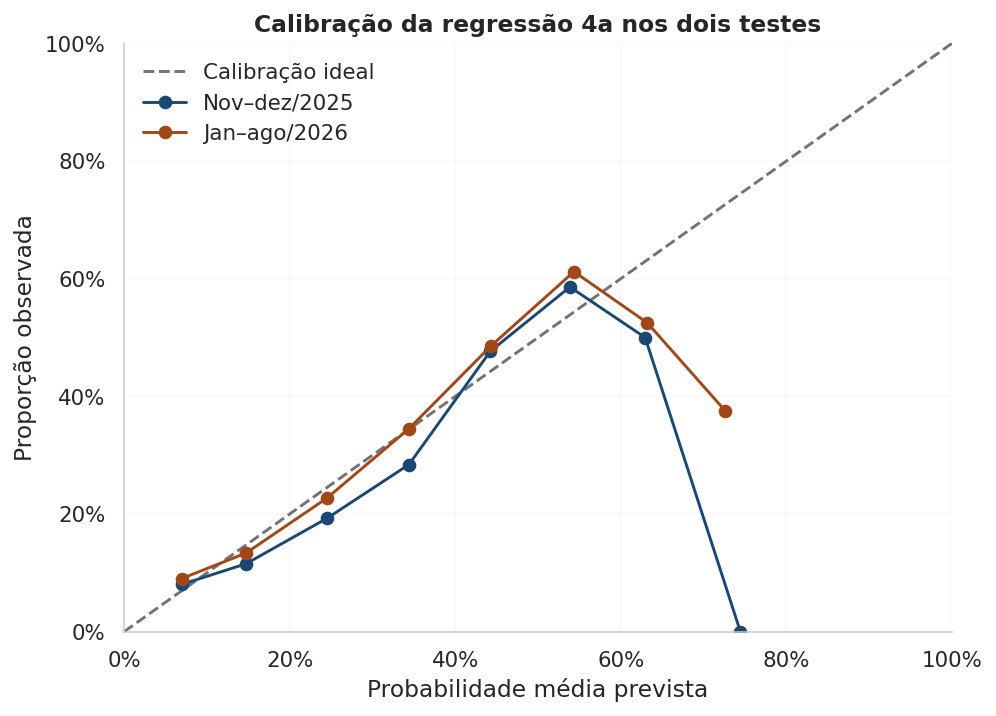

In [47]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig_calibracao, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.plot([0, 1], [0, 1], color="0.45", linestyle="--", label="Calibração ideal")
tabelas_calibracao = {}
for (periodo, (registros, probabilidades)), cor in zip(
    periodos_teste.items(), ["#184976", "#A34717"]
):
    faixas = pd.cut(probabilidades, bins=np.linspace(0, 1, 11), include_lowest=True)
    tabela = (
        pd.DataFrame({"Faixa": faixas, "Prevista": probabilidades, "Observada": registros[alvo]})
        .groupby("Faixa", observed=True)
        .agg(Registros=("Observada", "size"), Prevista=("Prevista", "mean"), Observada=("Observada", "mean"))
    )
    tabelas_calibracao[periodo] = tabela
    ax.plot(tabela["Prevista"], tabela["Observada"], color=cor, marker="o", label=periodo)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Probabilidade média prevista",
       ylabel="Proporção observada", title="Calibração da regressão 4a nos dois testes")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.2)
ax.legend(frameon=False)
display(pd.concat(tabelas_calibracao, names=["Período"]).round(4))
plt.show()

Na faixa de 70% a 80% de probabilidade prevista, havia apenas 2 registros no teste de 2025 e 8 no de 2026. O baixo volume torna a proporção observada nessa faixa instável.

#### Interpretação dos resultados

No total, a estimativa média ficou acima da frequência observada no teste de 2025 e ficou próxima dela na prévia de 2026. Por grupo, a frequência observada foi maior entre mães com 4 a 7 anos de estudo que entre as com 12 anos ou mais, nos dois testes. Essa diferença pode orientar investigações sobre acesso ao pré-natal. A decisão sobre uma ação pública também depende dos volumes, da oferta local e de outras evidências.

No nível individual, se um registro fictício recebesse 25% de probabilidade de menos de sete consultas, ele ultrapassaria o limiar de 11,88%. Nesse cenário hipotético, o alerta poderia motivar uma revisão por uma equipe. O exemplo ilustra a interpretação de uma previsão.

Nos testes, a regressão melhorou a ordenação em relação à referência, mas a regra de alerta gerou muitos falsos positivos e ficou abaixo da meta de sensibilidade. Na faixa de 60% a 70%, havia 42 registros em 2025 e 80 em 2026. O estudo é retrospectivo e cobre nascidos vivos registrados no SINASC.

## 5. Conclusão geral

Em Alagoas, em 2025, 19,84% dos nascidos vivos com informação de pré-natal tinham menos de sete consultas registradas. A proporção variou entre grupos maternos, com a diferença mais marcada por escolaridade. Entre municípios, a comparação por proporção revelou diferenças que o volume absoluto ocultava. Na validação, a ROC-AUC passou de 0,500 na referência para 0,619 com o perfil materno e 0,682 com a inclusão do município. Os resultados ajudam a localizar desigualdades na frequência registrada de consultas. A qualidade clínica do pré-natal exige outros indicadores.